# Évolution du projet : comment est-on arrivé là ? (FD001)

**Question du jury** : « Comment êtes-vous arrivés à ce résultat ? » Ce notebook raconte le parcours, **étape par étape**. Il ne sert pas de preuve des résultats finaux (ce sont les notebooks `resultats/FD00X.ipynb`) : c'est le récit des décisions, avec le chiffre qui a justifié chacune.

**Règles de lecture**

1. **Une seule chose change à chaque étape**, toujours présentée au même format : ce qui change, pourquoi, la figure avant / après, le lien vers le notebook d'origine (archivé au tag `v1-avant-reorganisation` sur GitHub).
2. **Validation croisée et test côte à côte.** Nos décisions ont été prises sur la validation croisée ; montrer le test seul ferait croire qu'on a choisi en le regardant.
3. **Aucun chiffre recopié à la main** (plan de réorganisation, section 9.2). Chaque chiffre est **recalculé** ici (modèles à arbres, LSTM de l'étape 3) ou **lu** dans un fichier versionné du dépôt (réseaux du calcul de nuit Optuna : `docs/resultats/04h/`). Le seul chiffre qui ne peut être ni l'un ni l'autre (benchmark exploratoire, notebook supprimé) est signalé comme tel. Les chiffres écrits dans les cellules de texte sont contrôlés par du code juste après (fonction `verifier`, bilan en section 8).

**Plan**

- Vue d'ensemble : l'escalier du RMSE FD001
- Étape 1 : benchmark exploratoire → XGBoost de la Phase 3
- Étape 2 : normalisation par régime (FD002, FD004)
- Étape 3 : arbres → LSTM (réglages fixés à l'avance)
- Étape 4 : écart à l'état initial (`ecartinit_20`), 5 modèles
- Étape 5 : Optuna sur les arbres
- Étape 6 : Optuna sur les réseaux
- 7. Pistes et diagnostics (ce qu'on a mesuré sans le retenir)
- 8. L'escalier, chiffres recalculés, et contrôle des chiffres cités

**Exécution** : une vingtaine de minutes à la première exécution (surtout les recherches d'hyperparamètres de l'étape 5 et le LSTM de l'étape 3), moins ensuite : ces deux calculs longs sont mis en cache dans `sorties/evolution/` (dossier non versionné), derrière des drapeaux `RELANCER_... = False` explicites.

## Vue d'ensemble : l'escalier du RMSE FD001

| Étape | Ce qui change (une seule chose) | Modèle concerné | Notebook d'origine (tag `v1-avant-reorganisation`) |
|---|---|---|---|
| 1 | Benchmark exploratoire (Random Forest) → XGBoost de la Phase 3, pipeline reproductible | XGBoost | [03_modelisation](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/03_modelisation.ipynb) |
| 2 | Normalisation des capteurs par régime de vol | XGBoost, FD002 et FD004 (FD001 inchangé : un seul régime) | [01b_sous_jeux_fd002_fd004](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/01b_sous_jeux_fd002_fd004.ipynb) |
| 3 | Arbres → LSTM, réglages fixés à l'avance | LSTM | [03b_deep_learning_lstm_cnn](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/03b_deep_learning_lstm_cnn.ipynb) |
| 4 | Variable `ecartinit_20` (écart de chaque capteur à son état de départ) | les 5 modèles qui apprennent | [04e_feature_engineering](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04e_feature_engineering.ipynb), [05_comparaison_evaluation](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/05_comparaison_evaluation.ipynb) |
| 5 | Réglages des arbres cherchés par Optuna au lieu d'être fixés à la main | XGBoost, LightGBM, Random Forest | [04d_hyperparametres](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04d_hyperparametres.ipynb), [04f_modele_final](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04f_modele_final.ipynb), [04g_comparaison_modeles](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04g_comparaison_modeles.ipynb) |
| 6 | Réglages des réseaux cherchés par Optuna, puis ensemble de 5 graines | LSTM | [04h_optuna_reseaux](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04h_optuna_reseaux.ipynb) |

**Où est la figure ?** Un notebook s'exécute de haut en bas : l'escalier ne peut être tracé qu'une fois chaque chiffre recalculé dans sa section. Il est donc en **section 8**, avec le tableau complet (validation croisée, test, provenance de chaque chiffre).

## Réglages communs

**Ce qu'on fait** : on importe les fonctions du dossier `src/` (et celles du script `scripts/generer_predictions_arbres.py`, qui a produit les prédictions des arbres de la démo) au lieu de recopier leur code ici.

**Machine partagée** : les modèles à arbres utilisent au plus 4 cœurs (`N_JOBS_ARBRES`). Sans tirage aléatoire de lignes (`subsample` = 1, cas de la Phase 3), XGBoost donne les mêmes arbres quel que soit le nombre de cœurs ; avec `subsample` < 1 (réglages finaux), le résultat dépend du nombre de cœurs et de la machine (voir l'étape 5). `xgboost` est importé **avant** `torch` (note OpenMP de `src/deep_learning.py`).

In [1]:
import sys
sys.path.insert(0, "..")  # la racine du depot devient importable : "from src ..." marche depuis notebooks/

import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # avertissement d'affichage, sans effet sur les calculs

# bibliotheques standard de Python
import copy      # deepcopy : copie independante d'une configuration (l'original reste intact)
import json      # lecture des resultats du 04h et des caches de ce notebook
import os        # chemins de fichiers
import time      # chronometres

# xgboost AVANT torch (note OpenMP de src/deep_learning.py) : torch arrive avec src.inference, plus bas
from xgboost import XGBRegressor

# calcul, tableaux, figures, tests statistiques
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display  # affiche plusieurs tableaux dans une meme cellule
from scipy import stats

# fonctions du projet (dossier src/)
from src.config_modele import (
    CONFIG_LIGHTGBM_BASE,          # LightGBM a reglages de base (notebook 05, section B)
    CONFIG_PHASE3,                 # XGBoost de la Phase 3 (notebook 03)
    CONFIG_RANDOM_FOREST_BASE,     # Random Forest a reglages de base (notebook 05, section B)
    CONFIG_REFERENCE_NAIVE,        # predit toujours la moyenne de la cible d'entrainement
    CONFIG_XGBOOST_FINAL,          # reglages finaux d'Optuna (notebook 04f)
    construire_fabrique_depuis_config,  # configuration -> fonction qui renvoie un modele neuf
)
from src.evaluation import (
    calculer_plis,                          # les 5 plis de validation croisee par moteur (verifies)
    comparer_apparie,                       # test t apparie + test de Wilcoxon signe
    demontrer_constantes_score_degenerees,  # demonstration de la section 7.1
    erreurs_par_moteur,                     # RMSE moteur par moteur
    evaluer_en_validation_croisee,          # entraine et evalue un modele sur les 5 plis
    evaluer_sur_test,                       # evalue un modele entraine sur le test officiel (dernier cycle)
    metriques_regression,                   # toutes les metriques de regression du protocole
    nb_surestimes,                          # nombre de predictions surestimees de plus d'un seuil
    rmse,                                   # racine de l'erreur quadratique moyenne
    score_nasa,                             # score asymetrique NASA (13 / 10)
)
from src.features import preparer_test, preparer_train  # pipeline des Phases 1 a 3 (FD001)
from src.inference import module_script_arbres          # charge scripts/generer_predictions_arbres.py (sans le lancer)
from src.sous_jeux import (
    DESCRIPTION_SOUS_JEUX,         # regimes et modes de panne de chaque sous-jeu
    REGIME_EN_FEATURE_PAR_DEFAUT,  # decision "regime en one-hot" (etape 2)
    SOUS_JEUX,                     # ["FD001", "FD002", "FD003", "FD004"]
    charger_rul_sous_jeu,          # RUL vraie du test (RUL_FD00X.txt)
    preparer_sous_jeu,             # meme pipeline, generalise aux 4 sous-jeux
)

script_arbres = module_script_arbres()  # les fonctions du script des arbres (sa fonction main n'est pas lancee)

PLAFOND_RUL = 125         # plafond de la RUL (Phase 2)
SEUIL_SURESTIMATION = 20  # cycles : une surestimation de plus de 20 cycles est comptee comme dangereuse (Phase 3)
SEUIL_ALERTE = 30         # cycles : RUL predite <= 30 -> maintenance ; hypothese de travail (notebook 05)
GRAINE = 42               # graine des plis et des modeles (Phase 3)
N_JOBS_ARBRES = 4         # coeurs donnes aux modeles a arbres (machine partagee)

DOSSIER_04H = os.path.join("..", "docs", "resultats", "04h")       # resultats versionnes du calcul de nuit (reseaux)
# resultats versionnes du 03b, execution du 2026-11-04 (celle de STATUS.md et de 02_choix_du_modele) : README du dossier
DOSSIER_03B = os.path.join("..", "docs", "resultats", "03b")
DOSSIER_EVOLUTION = os.path.join("..", "sorties", "evolution")     # caches de ce notebook (non versionnes)
os.makedirs(DOSSIER_EVOLUTION, exist_ok=True)

# couleurs : memes teintes que le notebook 05, toujours la meme teinte pour la meme chose
COULEUR_1 = "#2a78d6"      # bleu   : le modele "apres", ou XGBoost
COULEUR_2 = "#eb6834"      # orange : surestimations, LSTM
COULEUR_3 = "#1baf7a"      # vert d'eau
COULEUR_GRIS = "#a9a8a3"   # gris   : le modele "avant"
COULEUR_TEXTE = "#52514e"  # gris fonce (reperes, annotations)
plt.rcParams["axes.grid"] = True        # quadrillage sur toutes les figures
plt.rcParams["axes.axisbelow"] = True   # quadrillage dessine sous les barres et les points
plt.rcParams["grid.color"] = "#e4e3df"  # quadrillage gris clair, discret
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

debut_notebook = time.perf_counter()  # chronometre de l'execution complete

In [2]:
def config_avec_coeurs(config, n_jobs=N_JOBS_ARBRES):
    """
    Copie une configuration de src/config_modele.py en imposant le nombre de coeurs du modele.

    Le nombre de coeurs ne change pas les predictions de la Random Forest ni de LightGBM (graine fixee),
    ni celles de XGBoost sans tirage de lignes (subsample = 1) : il ne change que la vitesse. La
    configuration d'origine n'est pas modifiee (copie independante).

    Parameters
    ----------
    config : dict
        Une configuration (format de src/config_modele.py).
    n_jobs : int, optionnel
        Nombre de coeurs impose (4 par defaut).

    Returns
    -------
    dict
        La copie, avec "n_jobs" dans ses hyperparametres (sauf pour la reference naive, qui n'en a pas).
    """
    copie = copy.deepcopy(config)  # l'original reste intact
    if copie["famille"] in ["xgboost", "lightgbm", "random_forest"]:
        copie["hyperparametres"]["n_jobs"] = int(n_jobs)
    return copie


# --- controle des chiffres ecrits dans les cellules de texte (bilan en section 8) ---
CONTROLES = []  # une ligne par chiffre cite : description, valeur citee, valeur recalculee ou lue, identique ?


def verifier(description, valeur_citee, valeur_calculee, decimales=2, ecart_attendu=False):
    """
    Compare un chiffre ecrit dans une cellule de texte au chiffre recalcule (ou lu) par le code.

    Le notebook ne s'arrete pas si les deux different : l'ecart est affiche ici et dans le bilan de la
    section 8, pour etre corrige ou explique (rien n'est cache). `ecart_attendu=True` sert aux chiffres
    publies ailleurs (STATUS.md) dont on sait deja, et dit dans le texte, qu'ils different des fichiers.

    Parameters
    ----------
    description : str
        Ce que represente le chiffre.
    valeur_citee : float
        Le chiffre tel qu'il est ecrit dans le texte.
    valeur_calculee : float
        Le chiffre recalcule (ou lu dans un fichier) par le code.
    decimales : int, optionnel
        Nombre de decimales du chiffre cite (2 par defaut).
    ecart_attendu : bool, optionnel
        Vrai si un ecart est deja connu et explique dans le texte (il reste affiche).

    Returns
    -------
    bool
        Vrai si le chiffre calcule, arrondi comme le texte, est egal au chiffre cite.
    """
    arrondi = round(float(valeur_calculee), decimales)
    identique = bool(np.isclose(arrondi, float(valeur_citee), rtol=0.0, atol=1e-9))
    ligne = {}
    ligne["description"] = description
    ligne["valeur_citee"] = valeur_citee
    ligne["valeur_calculee"] = arrondi
    ligne["identique"] = identique
    ligne["ecart_attendu_explique"] = bool(ecart_attendu)
    CONTROLES.append(ligne)
    etat = "OK   "
    if not identique:
        etat = "ECART"
        if ecart_attendu:
            etat = "ECART ATTENDU (explique dans le texte)"
    print(f"{etat} {description} : cite {valeur_citee}, calcule {arrondi}")
    return identique


# --- l'escalier : une "marche" par modele et par etape, remplie au fil des sections ---
ESCALIER = []


def ajouter_marche(etape, modele, rmse_cv, protocole_cv, rmse_test, provenance):
    """
    Enregistre un point de l'escalier (trace en section 8).

    Parameters
    ----------
    etape : str
        Le numero de l'etape ("0" a "6", avec une lettre si plusieurs modeles a la meme etape).
    modele : str
        Le modele, tel qu'affiche.
    rmse_cv : float
        RMSE de validation (NaN s'il n'existe pas).
    protocole_cv : str
        Les plis de cette validation (ex. "5 plis, graine 42").
    rmse_test : float
        RMSE du test officiel FD001, contre la RUL brute (NaN s'il n'existe pas).
    provenance : str
        D'ou viennent les chiffres ("recalcule ici", nom du fichier lu, ...).
    """
    marche = {}
    marche["etape"] = etape
    marche["modele"] = modele
    marche["rmse_cv"] = float(rmse_cv)
    marche["protocole_cv"] = protocole_cv
    marche["rmse_test"] = float(rmse_test)
    marche["provenance"] = provenance
    ESCALIER.append(marche)

## Étape 1 : benchmark exploratoire → XGBoost de la Phase 3

- **Ce qui change** : le modèle de référence. Un notebook exploratoire (Random Forest) avait donné un premier chiffre sur le test FD001, sans suivre la normalisation, le lissage ni la documentation par phase. On le remplace par un **XGBoost dont tout le pipeline est dans le dépôt** (Phases 1 à 3) et reproductible par quiconque.
- **Pourquoi** : un chiffre qu'on ne peut pas refaire ne peut pas être défendu. Le benchmark garde un seul rôle : une référence chiffrée à battre.
- **Notebook d'origine** : [03_modelisation](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/03_modelisation.ipynb) (sections 7 à 10 et 13).
- **Notions** : features glissantes, score NASA, validation croisée par moteur (`GroupKFold`) sont expliqués dans `01_donnees` et `02_choix_du_modele`, là où ils apparaissent pour la première fois ; ici on appelle les fonctions de `src/` qui les implémentent.

### 1.1 Le benchmark exploratoire : le seul chiffre non recalculé

Le notebook qui l'a produit a été **supprimé** ([ADR-0006](../docs/decisions/0006-suppression-baseline-exploratoire.md)) : son chiffre ne peut être ni recalculé, ni lu dans un fichier de résultats. Le README le garde comme seule trace, avec l'interdiction d'en tirer d'autres statistiques. On le **lit dans le README** (pas de recopie à la main), en le signalant comme tel partout où il apparaît.

In [3]:
chemin_readme = os.path.join("..", "README.md")
with open(chemin_readme, encoding="utf-8") as fichier:
    lignes_readme = fichier.read().splitlines()  # le README, une ligne de texte par element

benchmark_test_rmse = None  # RMSE test officiel du benchmark exploratoire
benchmark_test_nasa = None  # score NASA test officiel du benchmark exploratoire
for ligne in lignes_readme:  # on cherche la ligne du tableau "Reference benchmark"
    if ligne.startswith("| Official test: raw |"):
        morceaux = ligne.split("|")  # ["", " Official test: raw ", " 18.97 ", " 1,053.90 ", ""]
        benchmark_test_rmse = float(morceaux[2].strip())
        benchmark_test_nasa = float(morceaux[3].strip().replace(",", ""))  # "1,053.90" -> 1053.90
assert benchmark_test_rmse is not None, "ligne du benchmark introuvable dans le README"

print(f"Benchmark exploratoire (Random Forest), test officiel FD001, lu dans le README : "
      f"RMSE {benchmark_test_rmse:.2f}, score NASA {benchmark_test_nasa:.1f}")
print("ATTENTION : chiffre NON recalcule (notebook supprime, ADR-0006) ; aucune validation croisee comparable.")
ajouter_marche("0", "Benchmark exploratoire (Random Forest)", np.nan, "-", benchmark_test_rmse,
               "README (NON recalculable : notebook supprime, ADR-0006)")

Benchmark exploratoire (Random Forest), test officiel FD001, lu dans le README : RMSE 18.97, score NASA 1053.9
ATTENTION : chiffre NON recalcule (notebook supprime, ADR-0006) ; aucune validation croisee comparable.


### 1.2 Données FD001 et plis de validation croisée

`preparer_train` refait le pipeline des Phases 1 à 3 sur `train_FD001.txt` (capteurs constants retirés, min-max, lissage, RUL plafonnée à 125, features glissantes) ; `preparer_test` applique au test les **mêmes** réglages appris sur le train. Les 46 features de la Phase 3 : 15 capteurs lissés, leurs 15 moyennes et 15 écarts-types glissants sur 5 cycles, et `time_cycles`. Les 5 plis par moteur (`GroupKFold`, mélange de graine 42) sont calculés une fois et servent à tous les modèles de ce notebook.

In [4]:
contexte_train = preparer_train(fenetre=5, plafond=PLAFOND_RUL)  # pipeline des Phases 1 a 3, 46 features
contexte_test = preparer_test(contexte_train)  # memes transformations sur le test, reglages appris sur le train

X = contexte_train["X"]            # les 46 features, une ligne par cycle
y = contexte_train["y"]            # la cible : RUL plafonnee a 125
groups = contexte_train["groups"]  # numero de moteur de chaque ligne (sert a GroupKFold)
X_test_dernier = contexte_test["X_test_dernier"]  # features du dernier cycle observe de chaque moteur test
y_test_vraie = contexte_test["y_test_vraie"]      # RUL vraie BRUTE de RUL_FD001.txt (non plafonnee)

print(f"Train : {X.shape[0]} lignes, {X.shape[1]} features, {groups.nunique()} moteurs")
print(f"Test  : {X_test_dernier.shape[0]} moteurs (un point par moteur, au dernier cycle observe)")
assert X.shape == (20631, 46)
assert X_test_dernier.shape == (100, 46)

plis = calculer_plis(X, y, groups, n_splits=5, random_state=GRAINE)  # 5 plis par moteur, verifies

Train : 20631 lignes, 46 features, 100 moteurs
Test  : 100 moteurs (un point par moteur, au dernier cycle observe)


### 1.3 Validation croisée du XGBoost de la Phase 3, avec l'erreur sur les moteurs appris

Boucle de la section 7 du notebook 03, inchangée (mêmes réglages : 200 arbres, profondeur 5, pas 0,05), sauf deux points : les plis viennent de `calculer_plis` (le même `GroupKFold(5, shuffle=True, random_state=42)`) et les métriques de `src/evaluation.py`. On garde l'erreur sur les moteurs appris (RMSE train) : elle sert à la section 1.6 (R² train).

In [5]:
rmse_par_fold = []        # RMSE de validation, un par pli
rmse_train_par_fold = []  # erreur sur les moteurs APPRIS (RMSE train), un par pli
nasa_par_fold = []        # score NASA de validation, un par pli

for i, (idx_train, idx_val) in enumerate(plis):  # 5 plis
    X_tr, X_val = X.iloc[idx_train], X.iloc[idx_val]
    y_tr, y_val = y.iloc[idx_train], y.iloc[idx_val]

    # verification explicite qu'aucun moteur n'apparait des deux cotes de ce pli
    moteurs_train = set(groups.iloc[idx_train])
    moteurs_val = set(groups.iloc[idx_val])
    assert len(moteurs_train & moteurs_val) == 0, "un moteur est present des deux cotes !"

    # un modele TOUT NEUF a chaque tour ; n_jobs=4 : vitesse seulement (subsample = 1, memes arbres)
    modele = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=N_JOBS_ARBRES)
    modele.fit(X_tr, y_tr)               # apprend uniquement sur les moteurs de ce tour
    y_pred = modele.predict(X_val)       # predit sur des moteurs jamais vus par ce modele
    y_pred_train = modele.predict(X_tr)  # predit sur les moteurs qu'il vient d'apprendre (erreur train)

    rmse_val = rmse(y_val.values, y_pred)  # racine de la moyenne des ecarts au carre (src/evaluation.py)
    nasa_val = score_nasa(y_val.values, y_pred)
    rmse_train = rmse(y_tr.values, y_pred_train)
    rmse_par_fold.append(rmse_val)
    rmse_train_par_fold.append(rmse_train)
    nasa_par_fold.append(nasa_val)
    print(f"Pli {i + 1} : {len(moteurs_train)} moteurs train / {len(moteurs_val)} moteurs val -> "
          f"RMSE train={rmse_train:.2f}, RMSE val={rmse_val:.2f}, score NASA val={nasa_val:.1f}")

rmse_cv_phase3 = float(np.mean(rmse_par_fold))  # le chiffre de validation de l'etape 1
print(f"\nMoyenne sur les 5 plis : RMSE val={rmse_cv_phase3:.2f}, score NASA val={np.mean(nasa_par_fold):.1f}")
print(f"RMSE train moyen (moteurs appris) : {np.mean(rmse_train_par_fold):.2f}")

Pli 1 : 80 moteurs train / 20 moteurs val -> RMSE train=11.17, RMSE val=15.17, score NASA val=19024.1


Pli 2 : 80 moteurs train / 20 moteurs val -> RMSE train=10.56, RMSE val=18.79, score NASA val=24855.2


Pli 3 : 80 moteurs train / 20 moteurs val -> RMSE train=11.03, RMSE val=17.29, score NASA val=40402.5


Pli 4 : 80 moteurs train / 20 moteurs val -> RMSE train=11.00, RMSE val=15.90, score NASA val=30488.2


Pli 5 : 80 moteurs train / 20 moteurs val -> RMSE train=10.95, RMSE val=17.19, score NASA val=34142.8

Moyenne sur les 5 plis : RMSE val=16.87, score NASA val=29782.6
RMSE train moyen (moteurs appris) : 10.94


### 1.4 Modèle final et test officiel

Le modèle final est entraîné sur les 100 moteurs d'entraînement, puis évalué au **dernier cycle observé** de chaque moteur test, contre la RUL brute de `RUL_FD001.txt` (prédictions négatives ramenées à 0) : `evaluer_sur_test` de `src/evaluation.py` (sections 8 et 9 du notebook 03).

In [6]:
modele_final = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=N_JOBS_ARBRES)
modele_final.fit(X, y)  # les 100 moteurs d'entrainement

resultats_test_phase3 = evaluer_sur_test(modele_final, X_test_dernier, y_test_vraie, plafond=PLAFOND_RUL,
                                         seuil_surestimation=SEUIL_SURESTIMATION, seuil_alerte=SEUIL_ALERTE)
y_test_pred = resultats_test_phase3["predictions"]      # 100 predictions, clippees a 0
rmse_test = resultats_test_phase3["rmse"]               # RMSE contre la RUL brute
nasa_test = resultats_test_phase3["score_nasa"]
nb_surestimes_20 = resultats_test_phase3["nb_surestimes"]

print(f"RMSE test officiel        : {rmse_test:.2f}")
print(f"Score NASA test officiel  : {nasa_test:.1f}")
print(f"Moteurs surestimes de plus de 20 cycles : {nb_surestimes_20}/100")
ajouter_marche("1", "XGBoost Phase 3 (46 features, reglages a la main)", rmse_cv_phase3, "5 plis, graine 42",
               rmse_test, "recalcule ici")

RMSE test officiel        : 19.70
Score NASA test officiel  : 852.9
Moteurs surestimes de plus de 20 cycles : 9/100


### 1.5 Figure : prédictions contre vraies RUL du test

Plus les points sont proches de la diagonale, meilleur est le modèle ; au-dessus de la diagonale, ce sont les surestimations (le cas dangereux).

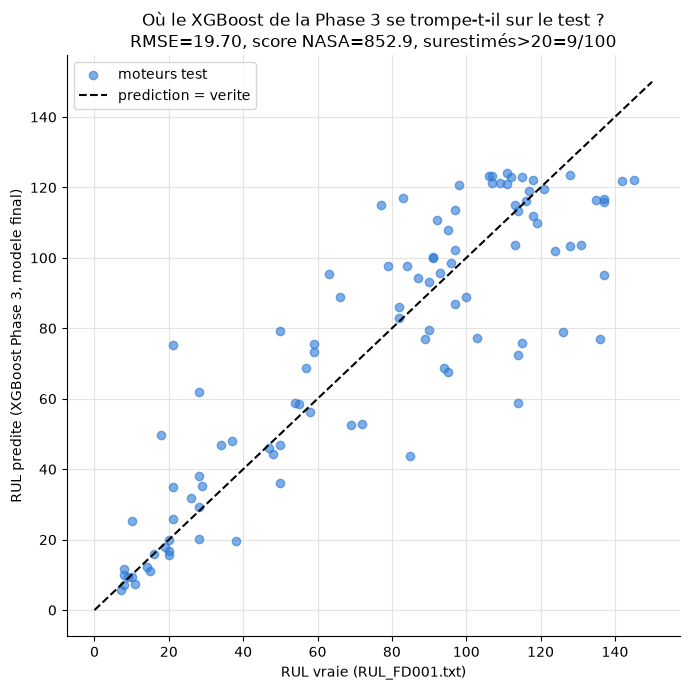

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(y_test_vraie, y_test_pred, alpha=0.6, color=COULEUR_1, label="moteurs test")
limite = max(y_test_vraie.max(), y_test_pred.max()) + 5
ax.plot([0, limite], [0, limite], linestyle="--", color="black", label="prediction = verite")

ax.set_xlabel("RUL vraie (RUL_FD001.txt)")
ax.set_ylabel("RUL predite (XGBoost Phase 3, modele final)")
ax.set_title(f"Où le XGBoost de la Phase 3 se trompe-t-il sur le test ?\n"
             f"RMSE={rmse_test:.2f}, score NASA={nasa_test:.1f}, surestimés>20={nb_surestimes_20}/100")
ax.legend()

plt.tight_layout()
plt.show()

### 1.6 Notre erreur est-elle grande ? Quatre références

*Section 13 du notebook 03, déplacée avec son code.* Une erreur n'est jamais « grande » toute seule : il lui faut une référence. On en utilise quatre :

1. **L'échelle de la cible** : la RUL d'entraînement va de 0 à 125 cycles (plafond de la Phase 2). On exprime le RMSE en pourcentage de cette plage.
2. **Un modèle « bête » (baseline)** : il prédit toujours la RUL moyenne des moteurs d'entraînement, sans regarder les capteurs. Si notre modèle ne fait pas nettement mieux, il n'apporte rien.
3. **Le R²** : il fait cette comparaison à la baseline en un seul chiffre. `R² = 1 - MSE_modèle / variance(y)` (la variance de `y` est exactement le MSE de la baseline qui prédit la moyenne). R² proche de 1 : bien meilleur que la baseline ; proche de 0 : pas mieux que prédire la moyenne.
4. **Le besoin du sujet** : l'erreur acceptable pour une décision de maintenance. Le cahier des charges ne fixe **aucun seuil chiffré** ; la seule référence chiffrée du projet à ce moment est le benchmark exploratoire (lu en 1.1, non recalculé).

Rien n'est réentraîné ici, sauf un modèle de contrôle du R² : on réutilise les RMSE mesurés en 1.3 et le modèle final de 1.4. Seul changement par rapport au notebook 03 : la figure n'est plus enregistrée dans `docs/figures/` (ce fichier, cité par `docs/03_modelisation.md`, ne doit pas être écrasé).

Cible train : min=0, max=125, moyenne=86.83, ecart-type=41.67
Pli 1 : baseline val= 41.72   modele val= 15.17   R2 train=0.928   R2 val=0.868
Pli 2 : baseline val= 41.56   modele val= 18.79   R2 train=0.936   R2 val=0.795
Pli 3 : baseline val= 41.89   modele val= 17.29   R2 train=0.930   R2 val=0.829
Pli 4 : baseline val= 41.72   modele val= 15.90   R2 train=0.930   R2 val=0.855
Pli 5 : baseline val= 41.56   modele val= 17.19   R2 train=0.931   R2 val=0.829



                                                       RMSE  % de 0-125      R2
Validation croisee : baseline (moyenne)               41.69       33.4 %    -   
Validation croisee : XGBoost, train                   10.94        8.8 %   0.931
Validation croisee : XGBoost, validation              16.87       13.5 %   0.835
Test officiel : baseline (moyenne)                    43.07       34.5 %    -   
Test officiel : XGBoost                               19.70       15.8 %   0.775
Test officiel : benchmark exploratoire RF (README)    18.97       15.2 %    -   

XGBoost fait 2.5 fois mieux que la baseline en validation croisee, 2.2 fois mieux sur le test officiel.


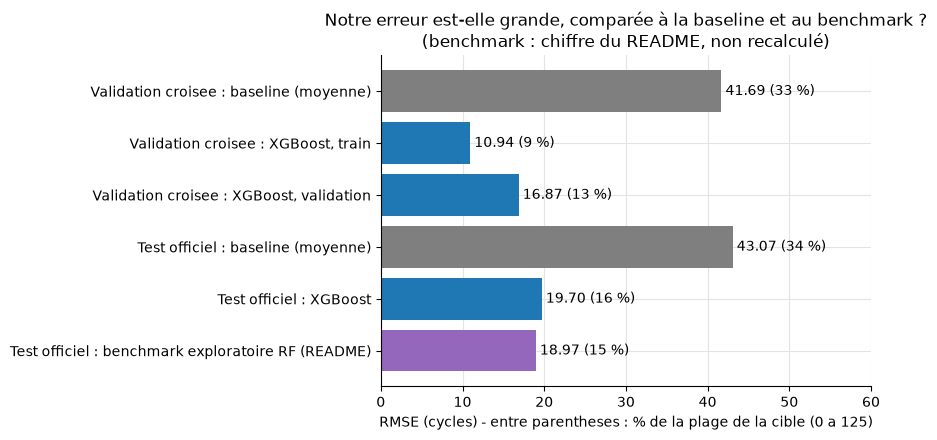

In [8]:
from sklearn.metrics import r2_score

# 1) Echelle de la cible (RUL plafonnee du train)
PLAGE_RUL = PLAFOND_RUL  # la RUL plafonnee va de 0 a 125 cycles : la plage fait donc 125
print(f"Cible train : min={y.min():.0f}, max={y.max():.0f}, moyenne={y.mean():.2f}, ecart-type={y.std(ddof=0):.2f}")

# 2) et 3) Baseline et R2, pli par pli, sur les memes plis que la section 1.3
rmse_baseline_par_fold = []  # RMSE du modele "bete" (predit toujours la moyenne du train du pli)
r2_train_par_fold = []       # R2 du modele XGBoost sur les moteurs appris
r2_val_par_fold = []         # R2 du modele XGBoost sur les moteurs jamais vus

for i, (idx_train, idx_val) in enumerate(plis):
    y_tr_pli = y.iloc[idx_train].values
    y_val_pli = y.iloc[idx_val].values

    # la baseline ne regarde aucun capteur : elle predit la moyenne de la RUL des moteurs d'entrainement du pli
    prediction_baseline = y_tr_pli.mean()
    rmse_baseline = np.sqrt(np.mean((y_val_pli - prediction_baseline) ** 2))
    rmse_baseline_par_fold.append(rmse_baseline)

    # R2 = 1 - MSE du modele / variance de y. On reutilise les RMSE de la section 1.3 (MSE = RMSE au carre).
    r2_train = 1 - rmse_train_par_fold[i] ** 2 / np.var(y_tr_pli)
    r2_val = 1 - rmse_par_fold[i] ** 2 / np.var(y_val_pli)
    r2_train_par_fold.append(r2_train)
    r2_val_par_fold.append(r2_val)

    print(f"Pli {i + 1} : baseline val={rmse_baseline:6.2f}   modele val={rmse_par_fold[i]:6.2f}   "
          f"R2 train={r2_train:.3f}   R2 val={r2_val:.3f}")

# meme verification que sklearn.metrics.r2_score, sur un pli, pour ne pas faire confiance a notre formule les yeux fermes
idx_train_0, idx_val_0 = plis[0]
modele_verif = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=N_JOBS_ARBRES)
modele_verif.fit(X.iloc[idx_train_0], y.iloc[idx_train_0])
r2_sklearn = r2_score(y.iloc[idx_val_0], modele_verif.predict(X.iloc[idx_val_0]))
assert abs(r2_sklearn - r2_val_par_fold[0]) < 0.01, "notre formule du R2 ne colle pas avec scikit-learn"

# meme chose sur le test officiel : la baseline predit la RUL moyenne de TOUT le train pour chacun des 100 moteurs
rmse_baseline_test = np.sqrt(np.mean((y_test_vraie - y.mean()) ** 2))
r2_test = r2_score(y_test_vraie, y_test_pred)
BENCHMARK_EXPLORATOIRE_TEST = benchmark_test_rmse  # lu dans le README en 1.1 (NON recalcule)

# tableau recapitulatif : chaque erreur avec ses references
lignes_tableau = [
    ("Validation croisee : baseline (moyenne)", np.mean(rmse_baseline_par_fold), None),
    ("Validation croisee : XGBoost, train", np.mean(rmse_train_par_fold), np.mean(r2_train_par_fold)),
    ("Validation croisee : XGBoost, validation", np.mean(rmse_par_fold), np.mean(r2_val_par_fold)),
    ("Test officiel : baseline (moyenne)", rmse_baseline_test, None),
    ("Test officiel : XGBoost", rmse_test, r2_test),
    ("Test officiel : benchmark exploratoire RF (README)", BENCHMARK_EXPLORATOIRE_TEST, None),
]
print(f"\n{'':52s} {'RMSE':>6s}  {'% de 0-125':>10s}  {'R2':>6s}")
for nom, rmse_ligne, r2_ligne in lignes_tableau:
    texte_r2 = "  -   "
    if r2_ligne is not None:
        texte_r2 = f"{r2_ligne:6.3f}"
    print(f"{nom:52s} {rmse_ligne:6.2f}  {100 * rmse_ligne / PLAGE_RUL:9.1f} %  {texte_r2}")

gain_val = np.mean(rmse_baseline_par_fold) / np.mean(rmse_par_fold)  # combien de fois mieux que la baseline
gain_test = rmse_baseline_test / rmse_test
print(f"\nXGBoost fait {gain_val:.1f} fois mieux que la baseline en validation croisee, {gain_test:.1f} fois mieux sur le test officiel.")

# visualisation : toutes les erreurs sur la meme echelle (0 a 125 cycles = la plage de la cible)
noms = []
valeurs = []
couleurs = []
for nom, rmse_ligne, r2_ligne in lignes_tableau:
    noms.append(nom)
    valeurs.append(rmse_ligne)
    if "baseline" in nom:
        couleurs.append("tab:grey")    # modele bete
    elif "benchmark" in nom:
        couleurs.append("tab:purple")  # reference a battre (non recalculee)
    else:
        couleurs.append("tab:blue")    # notre modele

fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(noms))
ax.barh(positions, valeurs, color=couleurs)
for position, valeur in zip(positions, valeurs):  # la valeur ecrite au bout de chaque barre
    ax.text(valeur + 0.5, position, f"{valeur:.2f} ({100 * valeur / PLAGE_RUL:.0f} %)", va="center")

ax.set_yticks(positions)
ax.set_yticklabels(noms)
ax.invert_yaxis()  # premiere ligne du tableau en haut
ax.set_xlim(0, 60)
ax.set_xlabel("RMSE (cycles) - entre parentheses : % de la plage de la cible (0 a 125)")
ax.set_title("Notre erreur est-elle grande, comparée à la baseline et au benchmark ?\n"
             "(benchmark : chiffre du README, non recalculé)")

plt.tight_layout()
plt.show()  # plus de savefig : docs/figures/03_echelle_erreur_baseline.png reste celui du notebook 03 (plan, 6.4)

### 1.7 Lecture de l'étape 1

1. **Échelle et baseline** : l'erreur de validation de XGBoost (16,87 cycles) représente 13,5 % de la plage de la cible ; il fait 2,5 fois mieux que « prédire la moyenne » en validation croisée, 2,2 fois mieux sur le test. Le modèle apprend donc bien quelque chose des capteurs.
2. **R²** : 0,835 en validation, 0,775 sur le test ; l'écart entre R² train (0,931) et validation mesure la même variance que le diagnostic biais / variance de `02_choix_du_modele`.
3. **Benchmark** : sur le test officiel, XGBoost (19,70) **ne bat pas** le benchmark exploratoire (18,97, non recalculé). L'écart n'est pas testé statistiquement (le benchmark n'a plus de prédictions moteur par moteur) ; le gain de cette étape est la **reproductibilité**, pas la précision.

Le document de Phase 3 (`docs/03_modelisation.md`) donne une validation croisée plus basse de 0,01 cycle, obtenue dans un autre environnement (voir `STATUS.md`, 2026-11-04) ; le test officiel est identique.

In [9]:
verifier("Etape 1 : RMSE CV XGBoost Phase 3", 16.87, rmse_cv_phase3)
verifier("Etape 1 : RMSE CV en % de la plage 0-125", 13.5, 100 * rmse_cv_phase3 / PLAGE_RUL, decimales=1)
verifier("Etape 1 : gain sur la baseline, validation croisee", 2.5, gain_val, decimales=1)
verifier("Etape 1 : gain sur la baseline, test", 2.2, gain_test, decimales=1)
verifier("Etape 1 : R2 validation", 0.835, np.mean(r2_val_par_fold), decimales=3)
verifier("Etape 1 : R2 test", 0.775, r2_test, decimales=3)
verifier("Etape 1 : R2 train", 0.931, np.mean(r2_train_par_fold), decimales=3)
verifier("Etape 1 : RMSE test XGBoost Phase 3", 19.70, rmse_test)
verifier("Etape 1 : RMSE test du benchmark (README)", 18.97, benchmark_test_rmse)

OK    Etape 1 : RMSE CV XGBoost Phase 3 : cite 16.87, calcule 16.87
OK    Etape 1 : RMSE CV en % de la plage 0-125 : cite 13.5, calcule 13.5
OK    Etape 1 : gain sur la baseline, validation croisee : cite 2.5, calcule 2.5
OK    Etape 1 : gain sur la baseline, test : cite 2.2, calcule 2.2
OK    Etape 1 : R2 validation : cite 0.835, calcule 0.835
OK    Etape 1 : R2 test : cite 0.775, calcule 0.775
OK    Etape 1 : R2 train : cite 0.931, calcule 0.931
OK    Etape 1 : RMSE test XGBoost Phase 3 : cite 19.7, calcule 19.7
OK    Etape 1 : RMSE test du benchmark (README) : cite 18.97, calcule 18.97


True

## Étape 2 : normalisation par régime de vol (FD002, FD004)

- **Ce qui change** : la mise à l'échelle des capteurs de FD002 et FD004. Ces deux sous-jeux mélangent **6 régimes de vol** (altitude, vitesse, poussée) ; on remplace le min-max global de FD001 par **un min-max par régime**, appris sur le train, appliqué avant le lissage. Le régime vient d'un K-Means sur les 3 réglages opérationnels (justification et figures dans `01_donnees`).
- **Pourquoi** : sur FD002, la valeur brute d'un capteur dépend d'abord du régime du cycle, et l'usure y est invisible ; sans correction, le lissage moyenne des cycles de régimes différents.
- **FD001 n'est pas touché** : un seul régime, préparation identique au bit près (contrôle dans `01_donnees`). L'escalier FD001 ne bouge donc pas à cette étape : on la mesure sur FD002 et FD004.
- **Notebook d'origine** : [01b_sous_jeux_fd002_fd004](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/01b_sous_jeux_fd002_fd004.ipynb), sections D.4 et F. Le notebook relisait les fichiers du script des arbres ; ici, le calcul est refait avec les fonctions du script (`valider_un_jeu`, `VARIANTES_ABLATION`), sans écrire aucun fichier.

### 2.1 Ce que la normalisation par régime change, mesuré en validation croisée

Trois variantes de préparation sur FD002 et FD004, **en validation croisée seulement** (mêmes 5 plis pour toutes les variantes d'un sous-jeu ; le test n'est jamais regardé), avec XGBoost Phase 3 :

| Variante | Normalisation | Capteurs retirés | Régime en feature |
|---|---|---|---|
| `globale` | min-max global (méthode FD001 telle quelle) | constants sur tout le train : aucun | non |
| `par_regime` | un min-max par régime (préparation retenue) | constants dans chaque régime | non |
| `par_regime_onehot` | un min-max par régime | idem | oui : 6 colonnes 0/1 (« one-hot »), une par régime |

**Règle de décision pour le one-hot, écrite avant de lancer les ablations** (docstring de `lancer_ablations` dans le script et constante `REGIME_EN_FEATURE_PAR_DEFAUT` de `src/sous_jeux.py`) : on ajoute le régime comme feature seulement si, pour XGBoost Phase 3, le RMSE CV moyen baisse **et** le test de Wilcoxon apparié sur le RMSE hors-pli par moteur (one-hot contre `par_regime`) donne p < 0,05. Sinon on garde le modèle le plus simple.

Colonnes : `diff_rmse_moteur_vs_par_regime` = moyenne, sur les moteurs, de (RMSE hors-pli de la variante − RMSE hors-pli de `par_regime`) : positif = la variante fait moins bien.

In [10]:
lignes_ablation = []  # une ligne par (sous-jeu, variante)

for sous_jeu in script_arbres.SOUS_JEUX_ABLATION:  # FD002 et FD004, les deux sous-jeux a 6 regimes
    plis_sous_jeu = None          # calcules sur la premiere variante, puis reutilises (memes lignes, memes moteurs)
    groupes_reference = None
    rmse_moteur_reference = None  # RMSE hors-pli par moteur de la variante "par_regime" (reference des tests)

    for nom_variante in script_arbres.VARIANTES_ABLATION:  # par_regime d'abord : c'est la reference
        normalisation, regime_en_feature = script_arbres.VARIANTES_ABLATION[nom_variante]
        contexte_variante = preparer_sous_jeu(sous_jeu, fenetre=5, plafond=PLAFOND_RUL,
                                              normalisation=normalisation, regime_en_feature=regime_en_feature)
        if plis_sous_jeu is None:
            plis_sous_jeu = calculer_plis(contexte_variante["X"], contexte_variante["y"], contexte_variante["groups"],
                                          n_splits=5, random_state=GRAINE)
            groupes_reference = contexte_variante["groups"].to_numpy()
        # garde-fou : memes moteurs, dans le meme ordre, pour toutes les variantes
        assert np.array_equal(contexte_variante["groups"].to_numpy(), groupes_reference)

        config_phase3 = script_arbres.configuration_modele("xgboost_phase3", n_jobs=N_JOBS_ARBRES)
        resultats_cv, par_moteur, duree_cv = script_arbres.valider_un_jeu(contexte_variante, config_phase3, plis_sous_jeu)

        ligne = {}
        ligne["sous_jeu"] = sous_jeu
        ligne["variante"] = nom_variante
        ligne["nb_features"] = len(contexte_variante["feature_cols"])
        ligne["rmse_cv_moyen"] = resultats_cv["rmse_moyen"]
        ligne["rmse_cv_ecart_type"] = resultats_cv["rmse_ecart_type"]
        ligne["nasa_cv_moyen"] = resultats_cv["nasa_moyen"]
        ligne["surestimes_oof"] = resultats_cv["surestimes_oof"]
        ligne["diff_rmse_moteur_vs_par_regime"] = np.nan
        ligne["p_t_vs_par_regime"] = np.nan
        ligne["p_wilcoxon_vs_par_regime"] = np.nan
        if nom_variante == "par_regime":
            rmse_moteur_reference = par_moteur["rmse"].to_numpy()
        else:
            comparaison = comparer_apparie(par_moteur["rmse"].to_numpy(), rmse_moteur_reference)
            ligne["diff_rmse_moteur_vs_par_regime"] = comparaison["difference_moyenne"]
            ligne["p_t_vs_par_regime"] = comparaison["p_valeur_t"]
            ligne["p_wilcoxon_vs_par_regime"] = comparaison["p_valeur_wilcoxon"]
        lignes_ablation.append(ligne)
        print(f"{sous_jeu} {nom_variante:18s} : RMSE CV {resultats_cv['rmse_moyen']:.2f} "
              f"+- {resultats_cv['rmse_ecart_type']:.2f} ({ligne['nb_features']} features, {duree_cv:.1f} s)")

ablations = pd.DataFrame(lignes_ablation)
ablations.set_index(["sous_jeu", "variante"]).round(4)

FD002 par_regime         : RMSE CV 16.41 +- 0.77 (52 features, 1.8 s)


FD002 globale            : RMSE CV 19.48 +- 1.53 (64 features, 2.3 s)


FD002 par_regime_onehot  : RMSE CV 16.43 +- 0.76 (58 features, 1.9 s)


FD004 par_regime         : RMSE CV 15.93 +- 1.73 (52 features, 2.0 s)


FD004 globale            : RMSE CV 19.40 +- 1.53 (64 features, 2.4 s)


FD004 par_regime_onehot  : RMSE CV 15.94 +- 1.74 (58 features, 2.1 s)


nb_features  rmse_cv_moyen  rmse_cv_ecart_type  nasa_cv_moyen  surestimes_oof  diff_rmse_moteur_vs_par_regime  p_t_vs_par_regime  p_wilcoxon_vs_par_regime
sous_jeu variante                                                                                                                                                                     
FD002    par_regime                  52        16.4135              0.7669     64743.0430            5852                             NaN                NaN                       NaN
         globale                     64        19.4809              1.5275     99569.6657            7716                          2.9329             0.0000                    0.0000
         par_regime_onehot           58        16.4260              0.7580     64886.2692            5853                          0.0122             0.0706                    0.0302
FD004    par_regime                  52        15.9332              1.7295    133989.1519            5868                             NaN                NaN                       NaN
         globale                     64        19.4038              1.5268    171062.7807            8893                          3.8818             0.0000                    0.0000
         par_regime_onehot           58        15.9352              1.7375    134400.7827            5865                          0.0009             0.8309                    0.5223

Application de la règle de décision, sous-jeu par sous-jeu (la cellule s'arrête sur une erreur si la décision diffère de la valeur codée dans `src/sous_jeux.py`) :

In [11]:
# application de la regle de decision (one-hot contre par_regime), sous-jeu par sous-jeu, pour XGBoost Phase 3
for sous_jeu in ["FD002", "FD004"]:
    masque_reference = (ablations["sous_jeu"] == sous_jeu) & (ablations["variante"] == "par_regime")
    masque_one_hot = (ablations["sous_jeu"] == sous_jeu) & (ablations["variante"] == "par_regime_onehot")
    reference = ablations[masque_reference].iloc[0]
    one_hot = ablations[masque_one_hot].iloc[0]
    rmse_baisse = one_hot["rmse_cv_moyen"] < reference["rmse_cv_moyen"]  # condition 1 : le RMSE CV moyen baisse
    significatif = one_hot["p_wilcoxon_vs_par_regime"] < 0.05  # condition 2 : Wilcoxon apparie par moteur
    decision = bool(rmse_baisse and significatif)  # les deux conditions doivent etre remplies
    print(f"{sous_jeu} XGBoost Phase 3 : RMSE CV {reference['rmse_cv_moyen']:.3f} -> {one_hot['rmse_cv_moyen']:.3f} "
          f"(baisse : {bool(rmse_baisse)}), p Wilcoxon = {one_hot['p_wilcoxon_vs_par_regime']:.3f} (< 0,05 : {bool(significatif)})")
    print(f"  -> {sous_jeu} : regime en feature = {decision} (valeur utilisee par src/sous_jeux.py : "
          f"{REGIME_EN_FEATURE_PAR_DEFAUT[sous_jeu]})")
    assert decision == REGIME_EN_FEATURE_PAR_DEFAUT[sous_jeu]

FD002 XGBoost Phase 3 : RMSE CV 16.413 -> 16.426 (baisse : False), p Wilcoxon = 0.030 (< 0,05 : True)
  -> FD002 : regime en feature = False (valeur utilisee par src/sous_jeux.py : False)
FD004 XGBoost Phase 3 : RMSE CV 15.933 -> 15.935 (baisse : False), p Wilcoxon = 0.522 (< 0,05 : False)
  -> FD004 : regime en feature = False (valeur utilisee par src/sous_jeux.py : False)


### 2.2 XGBoost Phase 3 sur les quatre sous-jeux (validation croisée et test officiel)

Avec la préparation retenue (normalisation par régime pour FD002 et FD004), XGBoost Phase 3 (réglages choisis sur FD001, non réoptimisés) est validé puis testé sur chaque sous-jeu. Rappels : **CV** = moyenne ± écart-type des 5 plis, contre la RUL plafonnée, sur tous les cycles ; **test** = dernier cycle observé de chaque moteur test, contre la RUL **brute** (et contre la RUL plafonnée à 125) ; **score NASA par moteur** = score NASA test / nombre de moteurs test, pour comparer des sous-jeux de tailles différentes.

In [12]:
lignes_resume = []                  # une ligne par sous-jeu
predictions_test_sous_jeux = {}     # sous-jeu -> (RUL vraie, RUL predite) des moteurs test, au dernier cycle

for sous_jeu in SOUS_JEUX:
    contexte_sous_jeu = preparer_sous_jeu(sous_jeu, fenetre=5, plafond=PLAFOND_RUL)  # preparation retenue
    plis_sous_jeu = calculer_plis(contexte_sous_jeu["X"], contexte_sous_jeu["y"], contexte_sous_jeu["groups"],
                                  n_splits=5, random_state=GRAINE)
    config_phase3 = script_arbres.configuration_modele("xgboost_phase3", n_jobs=N_JOBS_ARBRES)
    resultats_cv, _, _ = script_arbres.valider_un_jeu(contexte_sous_jeu, config_phase3, plis_sous_jeu)

    modele_sous_jeu = construire_fabrique_depuis_config(config_phase3)()  # modele neuf
    modele_sous_jeu.fit(contexte_sous_jeu["X"], contexte_sous_jeu["y"])  # tous les moteurs d'entrainement
    resultats_test_sous_jeu = evaluer_sur_test(modele_sous_jeu, contexte_sous_jeu["X_test_dernier"],
                                               contexte_sous_jeu["y_test_vraie"], plafond=PLAFOND_RUL,
                                               seuil_surestimation=SEUIL_SURESTIMATION, seuil_alerte=SEUIL_ALERTE)
    nb_moteurs_test = len(contexte_sous_jeu["y_test_vraie"])

    ligne = {}
    ligne["sous_jeu"] = sous_jeu
    ligne["nb_moteurs_test"] = nb_moteurs_test
    ligne["rmse_cv_moyen"] = resultats_cv["rmse_moyen"]
    ligne["rmse_cv_ecart_type"] = resultats_cv["rmse_ecart_type"]
    ligne["nasa_cv_moyen"] = resultats_cv["nasa_moyen"]
    ligne["surestimes_oof"] = resultats_cv["surestimes_oof"]
    ligne["rmse_test"] = resultats_test_sous_jeu["rmse"]
    ligne["rmse_test_rul_plafonnee"] = resultats_test_sous_jeu["rmse_contre_rul_plafonnee"]
    ligne["mae_test"] = resultats_test_sous_jeu["mae"]
    ligne["nasa_test"] = resultats_test_sous_jeu["score_nasa"]
    ligne["nasa_test_par_moteur"] = resultats_test_sous_jeu["score_nasa"] / nb_moteurs_test
    ligne["surestimes_test"] = resultats_test_sous_jeu["nb_surestimes"]
    ligne["part_surestimes_test"] = resultats_test_sous_jeu["nb_surestimes"] / nb_moteurs_test
    ligne["alertes_manquees_test"] = resultats_test_sous_jeu["alertes_manquees"]
    ligne["fausses_alertes_test"] = resultats_test_sous_jeu["fausses_alertes"]
    lignes_resume.append(ligne)
    predictions_test_sous_jeux[sous_jeu] = (np.asarray(contexte_sous_jeu["y_test_vraie"], dtype=float),
                                            resultats_test_sous_jeu["predictions"])

resume = pd.DataFrame(lignes_resume)
# FD001 : la preparation generalisee redonne exactement l'etape 1
assert abs(resume.loc[resume["sous_jeu"] == "FD001", "rmse_test"].iloc[0] - rmse_test) < 1e-9
resume.set_index("sous_jeu").round(2)

,nb_moteurs_test,rmse_cv_moyen,rmse_cv_ecart_type,nasa_cv_moyen,surestimes_oof,rmse_test,rmse_test_rul_plafonnee,mae_test,nasa_test,nasa_test_par_moteur,surestimes_test,part_surestimes_test,alertes_manquees_test,fausses_alertes_test
sous_jeu,,,,,,,,,,,,,,
FD001,100,16.87,1.25,29782.56,2384,19.70,18.53,14.36,852.89,8.53,9,0.09,7,1
FD002,259,16.41,0.77,64743.04,5852,27.23,15.46,18.84,9255.38,35.74,27,0.10,2,3
FD003,100,14.82,1.79,27135.47,2010,18.09,16.66,13.48,686.80,6.87,13,0.13,3,0
FD004,248,15.93,1.73,133989.15,5868,28.24,17.28,20.94,5519.03,22.25,31,0.12,7,3


**Pourquoi le RMSE test de FD002 et FD004 est si élevé** (section F.2 du 01b) : le modèle a appris une cible plafonnée à 125 et ne prédit jamais beaucoup plus. Un moteur test dont la vraie RUL est 190 coûte donc au moins 65 cycles d'erreur. Test de l'hypothèse : (1) la part de moteurs test au-dessus de 125 ; (2) le **RMSE plancher** dû au seul plafond (un modèle imaginaire qui prédirait exactement min(RUL vraie, 125)) ; (3) le RMSE séparé sous et au-dessus de 125.

In [13]:
lignes = []
for sous_jeu in SOUS_JEUX:
    rul_vraie = charger_rul_sous_jeu(sous_jeu).astype(float)
    vraie_contexte, predite = predictions_test_sous_jeux[sous_jeu]
    assert np.array_equal(vraie_contexte, rul_vraie)  # meme ordre de moteurs
    au_dessus = rul_vraie > PLAFOND_RUL
    # RMSE d'un modele qui predirait exactement min(RUL vraie, 125) : l'erreur qui reste vient du seul plafond
    plancher = float(np.sqrt(np.mean((rul_vraie - np.minimum(rul_vraie, PLAFOND_RUL)) ** 2)))
    ecarts = predite - rul_vraie  # positif = surestimation
    ligne = {}
    ligne["sous_jeu"] = sous_jeu
    ligne["nb_moteurs_test"] = len(rul_vraie)
    ligne["pct_rul_vraie_sup_125"] = 100 * float(np.mean(au_dessus))
    ligne["rul_vraie_max"] = int(rul_vraie.max())
    ligne["rmse_plancher_du_plafond"] = plancher
    ligne["rmse_test"] = float(np.sqrt(np.mean(ecarts ** 2)))
    ligne["rmse_rul_vraie_inf_125"] = float(np.sqrt(np.mean(ecarts[~au_dessus] ** 2)))
    ligne["rmse_rul_vraie_sup_125"] = float(np.sqrt(np.mean(ecarts[au_dessus] ** 2)))
    ligne["biais_rul_vraie_sup_125"] = float(np.mean(ecarts[au_dessus]))  # negatif = sous-estimation
    ligne["prediction_max"] = float(predite.max())
    lignes.append(ligne)
tableau_plafond = pd.DataFrame(lignes).set_index("sous_jeu")
tableau_plafond.round(2)

,nb_moteurs_test,pct_rul_vraie_sup_125,rul_vraie_max,rmse_plancher_du_plafond,rmse_test,rmse_rul_vraie_inf_125,rmse_rul_vraie_sup_125,biais_rul_vraie_sup_125,prediction_max
sous_jeu,,,,,,,,,
FD001,100,11.00,145,3.74,19.70,17.69,31.58,-27.97,124.14
FD002,259,22.01,194,18.32,27.23,16.00,49.62,-43.89,130.55
FD003,100,15.00,145,4.71,18.09,16.91,23.71,-19.81,124.97
FD004,248,27.02,195,19.53,28.24,18.53,44.99,-40.48,129.06


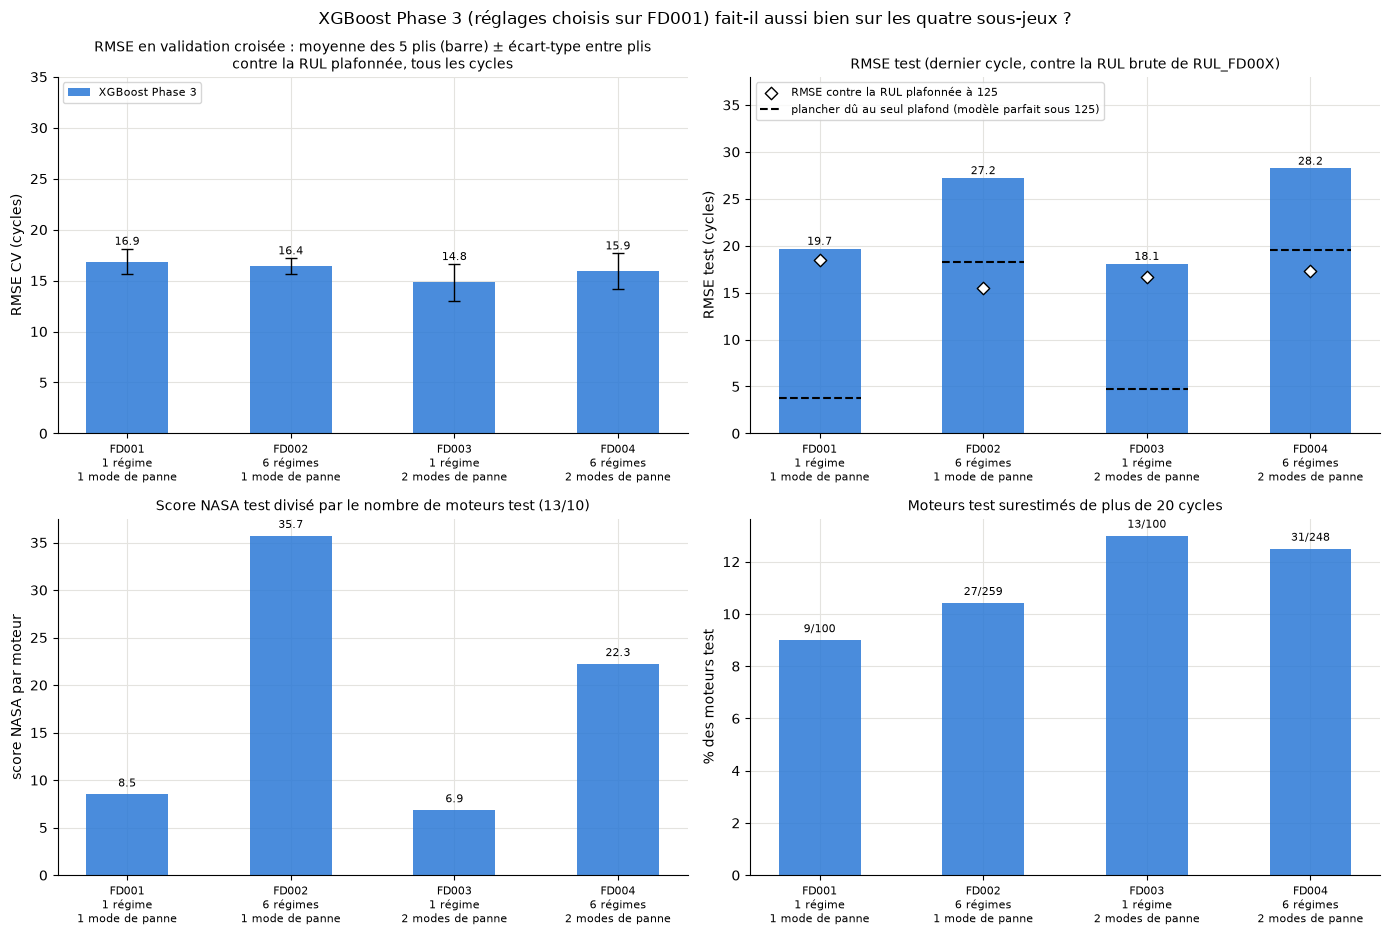

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
positions = np.arange(len(SOUS_JEUX))
largeur = 0.5


def ligne_resume(sous_jeu):
    """
    Renvoie la ligne du tableau `resume` (section 2.2) d'un sous-jeu.

    Parameters
    ----------
    sous_jeu : str
        Le sous-jeu (ex. "FD002").

    Returns
    -------
    pandas.Series
        La ligne correspondante.
    """
    return resume[resume["sous_jeu"] == sous_jeu].iloc[0]


# (1) RMSE CV moyen (moyenne des 5 plis) : une barre par sous-jeu
for position, sous_jeu in zip(positions, SOUS_JEUX):
    ligne = ligne_resume(sous_jeu)
    etiquette = None  # legende : une seule entree
    if position == 0:
        etiquette = "XGBoost Phase 3"
    axes[0, 0].bar(position, ligne["rmse_cv_moyen"], width=largeur, color=COULEUR_1, alpha=0.85, label=etiquette)
    # barre d'erreur : ecart-type du RMSE entre les 5 plis
    axes[0, 0].errorbar(position, ligne["rmse_cv_moyen"], yerr=ligne["rmse_cv_ecart_type"], color="black", capsize=4, linewidth=1)
    axes[0, 0].text(position, ligne["rmse_cv_moyen"] + ligne["rmse_cv_ecart_type"] + 0.4, f"{ligne['rmse_cv_moyen']:.1f}",
                    ha="center", fontsize=8)
axes[0, 0].set_title("RMSE en validation croisée : moyenne des 5 plis (barre) ± écart-type entre plis\n"
                     "contre la RUL plafonnée, tous les cycles", fontsize=10)
axes[0, 0].set_ylabel("RMSE CV (cycles)")
axes[0, 0].set_ylim(0, 35)
axes[0, 0].legend(fontsize=8, loc="upper left")

# (2) RMSE test : barre = contre la RUL brute ; losange = contre la RUL plafonnee ; tiret = plancher du plafond
for position, sous_jeu in zip(positions, SOUS_JEUX):
    ligne = ligne_resume(sous_jeu)
    axes[0, 1].bar(position, ligne["rmse_test"], width=largeur, color=COULEUR_1, alpha=0.85)
    axes[0, 1].scatter(position, ligne["rmse_test_rul_plafonnee"], marker="D", s=40, color="white", edgecolors="black", zorder=3)
    axes[0, 1].text(position, ligne["rmse_test"] + 0.4, f"{ligne['rmse_test']:.1f}", ha="center", fontsize=8)
    plancher = tableau_plafond.loc[sous_jeu, "rmse_plancher_du_plafond"]
    axes[0, 1].hlines(plancher, position - largeur / 2, position + largeur / 2, colors="black", linestyles="--", linewidth=1.5)
axes[0, 1].scatter([], [], marker="D", s=40, color="white", edgecolors="black", label="RMSE contre la RUL plafonnée à 125")
axes[0, 1].plot([], [], color="black", linestyle="--", label="plancher dû au seul plafond (modèle parfait sous 125)")
axes[0, 1].set_title("RMSE test (dernier cycle, contre la RUL brute de RUL_FD00X)", fontsize=10)
axes[0, 1].set_ylabel("RMSE test (cycles)")
axes[0, 1].set_ylim(0, 38)  # place pour la legende au-dessus des barres
axes[0, 1].legend(fontsize=8, loc="upper left")

# (3) score NASA test par moteur
for position, sous_jeu in zip(positions, SOUS_JEUX):
    ligne = ligne_resume(sous_jeu)
    axes[1, 0].bar(position, ligne["nasa_test_par_moteur"], width=largeur, color=COULEUR_1, alpha=0.85)
    axes[1, 0].text(position, ligne["nasa_test_par_moteur"] + 0.8, f"{ligne['nasa_test_par_moteur']:.1f}", ha="center", fontsize=8)
axes[1, 0].set_title("Score NASA test divisé par le nombre de moteurs test (13/10)", fontsize=10)
axes[1, 0].set_ylabel("score NASA par moteur")

# (4) part des moteurs test surestimes de plus de 20 cycles
for position, sous_jeu in zip(positions, SOUS_JEUX):
    ligne = ligne_resume(sous_jeu)
    pourcentage = 100 * ligne["part_surestimes_test"]
    axes[1, 1].bar(position, pourcentage, width=largeur, color=COULEUR_1, alpha=0.85)
    axes[1, 1].text(position, pourcentage + 0.3, f"{int(ligne['surestimes_test'])}/{int(ligne['nb_moteurs_test'])}",
                    ha="center", fontsize=8)
axes[1, 1].set_title("Moteurs test surestimés de plus de 20 cycles", fontsize=10)
axes[1, 1].set_ylabel("% des moteurs test")

for ax in axes.flat:  # memes etiquettes sous chaque panneau : sous-jeu, regimes, modes de panne
    ax.set_xticks(positions)
    etiquettes = []
    for sous_jeu in SOUS_JEUX:
        nb_regimes = DESCRIPTION_SOUS_JEUX[sous_jeu]["nb_regimes"]
        nb_pannes = len(DESCRIPTION_SOUS_JEUX[sous_jeu]["modes_de_panne"])
        texte_regimes = "1 régime"
        if nb_regimes > 1:
            texte_regimes = f"{nb_regimes} régimes"
        texte_pannes = "1 mode de panne"
        if nb_pannes > 1:
            texte_pannes = f"{nb_pannes} modes de panne"
        etiquettes.append(f"{sous_jeu}\n{texte_regimes}\n{texte_pannes}")
    ax.set_xticklabels(etiquettes, fontsize=8)

fig.suptitle("XGBoost Phase 3 (réglages choisis sur FD001) fait-il aussi bien sur les quatre sous-jeux ?")
plt.tight_layout()
plt.show()

### 2.3 Lecture de l'étape 2

- **La normalisation par régime est nécessaire.** Avec la méthode FD001 telle quelle (`globale`), le RMSE CV de XGBoost Phase 3 est de 19,48 sur FD002 et 19,40 sur FD004 ; avec la normalisation par régime, 16,41 et 15,93. Les tests appariés par moteur sont nets (tableau 2.1).
- **Le régime en one-hot n'apporte rien de mesurable** : la règle n'est remplie pour aucun des deux sous-jeux, on garde le modèle le plus simple.
- **Sous-jeu par sous-jeu** : en validation croisée, XGBoost Phase 3 se comporte sur FD002, FD003 et FD004 comme sur FD001. Sur le test, FD002 et FD004 sont nettement moins bons (RMSE brut 27,23 et 28,24), et presque tout l'écart vient du plafond : 22 % et 27 % de leurs moteurs test ont une RUL vraie au-dessus de 125, et un modèle parfait sous ce plafond aurait déjà un RMSE de 18,32 et 19,53 (3,74 sur FD001). Ce constat vient du test : il ne change aucun choix.

In [15]:
ablations_index = ablations.set_index(["sous_jeu", "variante"])
verifier("Etape 2 : RMSE CV FD002, normalisation globale", 19.48, ablations_index.loc[("FD002", "globale"), "rmse_cv_moyen"])
verifier("Etape 2 : RMSE CV FD004, normalisation globale", 19.40, ablations_index.loc[("FD004", "globale"), "rmse_cv_moyen"])
verifier("Etape 2 : RMSE CV FD002, normalisation par regime", 16.41, ablations_index.loc[("FD002", "par_regime"), "rmse_cv_moyen"])
verifier("Etape 2 : RMSE CV FD004, normalisation par regime", 15.93, ablations_index.loc[("FD004", "par_regime"), "rmse_cv_moyen"])
resume_index = resume.set_index("sous_jeu")
verifier("Etape 2 : RMSE test brut FD002", 27.23, resume_index.loc["FD002", "rmse_test"])
verifier("Etape 2 : RMSE test brut FD004", 28.24, resume_index.loc["FD004", "rmse_test"])
verifier("Etape 2 : % RUL vraie > 125, FD002", 22, tableau_plafond.loc["FD002", "pct_rul_vraie_sup_125"], decimales=0)
verifier("Etape 2 : % RUL vraie > 125, FD004", 27, tableau_plafond.loc["FD004", "pct_rul_vraie_sup_125"], decimales=0)
verifier("Etape 2 : plancher du plafond FD002", 18.32, tableau_plafond.loc["FD002", "rmse_plancher_du_plafond"])
verifier("Etape 2 : plancher du plafond FD004", 19.53, tableau_plafond.loc["FD004", "rmse_plancher_du_plafond"])
verifier("Etape 2 : plancher du plafond FD001", 3.74, tableau_plafond.loc["FD001", "rmse_plancher_du_plafond"])

# marche de l'escalier : FD002, avant (globale) et apres (par regime), en validation croisee seulement
ajouter_marche("2", "XGBoost Phase 3, FD002 : normalisation globale (avant)",
               ablations_index.loc[("FD002", "globale"), "rmse_cv_moyen"], "5 plis, graine 42 (FD002)", np.nan,
               "recalcule ici (pas de test pour la variante non retenue)")
ajouter_marche("2", "XGBoost Phase 3, FD002 : normalisation par regime (apres)",
               ablations_index.loc[("FD002", "par_regime"), "rmse_cv_moyen"], "5 plis, graine 42 (FD002)",
               resume_index.loc["FD002", "rmse_test"], "recalcule ici")

OK    Etape 2 : RMSE CV FD002, normalisation globale : cite 19.48, calcule 19.48
OK    Etape 2 : RMSE CV FD004, normalisation globale : cite 19.4, calcule 19.4
OK    Etape 2 : RMSE CV FD002, normalisation par regime : cite 16.41, calcule 16.41
OK    Etape 2 : RMSE CV FD004, normalisation par regime : cite 15.93, calcule 15.93
OK    Etape 2 : RMSE test brut FD002 : cite 27.23, calcule 27.23
OK    Etape 2 : RMSE test brut FD004 : cite 28.24, calcule 28.24
OK    Etape 2 : % RUL vraie > 125, FD002 : cite 22, calcule 22.0
OK    Etape 2 : % RUL vraie > 125, FD004 : cite 27, calcule 27.0
OK    Etape 2 : plancher du plafond FD002 : cite 18.32, calcule 18.32
OK    Etape 2 : plancher du plafond FD004 : cite 19.53, calcule 19.53
OK    Etape 2 : plancher du plafond FD001 : cite 3.74, calcule 3.74


## Étape 3 : arbres → LSTM, réglages fixés à l'avance

- **Ce qui change** : le type de modèle. Au lieu de résumer l'historique d'un moteur par des statistiques glissantes (features des arbres), un **LSTM** lit directement la séquence des 30 derniers cycles (15 capteurs lissés et `time_cycles` / 100). Réglages fixés **avant** tout résultat, jamais optimisés à ce stade : 2 couches de 64 unités, dropout 0,2, pas 1e-3, lots de 256, arrêt précoce (patience 10, 80 époques au plus) sur 20 % des moteurs d'entraînement de chaque pli.
- **Pourquoi** : le cahier des charges demande un modèle séquentiel, et le diagnostic de la Phase 3 montrait un plancher de validation des arbres que la complexité ne faisait pas baisser (`02_choix_du_modele`, biais / variance) : la piste était des entrées ou des modèles différents.
- **Notebook d'origine** : [03b_deep_learning_lstm_cnn](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/03b_deep_learning_lstm_cnn.ipynb), sections D (validation croisée, mêmes plis que les arbres) et F (test officiel). Les notions (fenêtre glissante, LSTM, arrêt précoce) sont expliquées dans `02_choix_du_modele`.

### 3.1 Le LSTM du 03b, recalculé

**Aucun fichier versionné ne contient le test de cette version** (les fichiers `docs/resultats/03b/` et `docs/resultats/04h/03b_*` sont ceux de la version suivante, avec `ecartinit_20`, étape 4). Le calcul tient en quelques minutes sur 4 cœurs (durée affichée sous la cellule à la première exécution) : on le refait ici, avec le code du 04h (`src/optimisation_reseaux.py`) et la configuration de référence du 03b **sans** l'écart à l'état initial — la seule différence entre les deux versions. Étapes : validation croisée sur les 5 plis de graine 42 (un pli par processus, 4 processus, 1 cœur chacun), nombre d'époques du modèle final = médiane des meilleures époques des 5 plis (règle du 03b, jamais choisie sur le test), modèle final sur les 100 moteurs, graine 42, test au dernier cycle.

Le résultat est mis en cache dans `sorties/evolution/lstm_03b_base_fd001.json` : avec `RELANCER_LSTM_03B = False`, une exécution suivante relit ce fichier (s'il existe) au lieu de réentraîner.

In [16]:
# src.optimisation_reseaux importe torch : apres xgboost (deja charge en tete du notebook), voir src/deep_learning.py
from concurrent.futures import ProcessPoolExecutor  # un pli de validation croisee par processus

from src import optimisation_reseaux as opt

RELANCER_LSTM_03B = False  # True : reentraine meme si le cache existe (environ 3 min mesurees sur 4 coeurs)
NB_PROCESSUS_LSTM = 4      # 4 processus, 1 coeur chacun (machine partagee)
CHEMIN_CACHE_LSTM_03B = os.path.join(DOSSIER_EVOLUTION, "lstm_03b_base_fd001.json")

# configuration du LSTM du 03b : celle de reference du 04h, SANS l'ecart a l'etat initial (version de base du 03b)
config_lstm_03b = opt.copie_config(opt.CONFIG_LSTM_REFERENCE)
config_lstm_03b["entrees"]["ecart_initial"] = None
print("Configuration :", config_lstm_03b)


def calculer_lstm_03b(config, nb_processus):
    """
    Validation croisee (5 plis, graine 42) puis modele final et test officiel FD001 d'un reseau.

    Reprend le protocole du notebook 03b avec les fonctions de src/optimisation_reseaux.py : un pli par
    processus (`executer_tache_pli`, 1 coeur par apprentissage), nombre d'epoques du modele final =
    mediane des meilleures epoques des 5 plis (arrondie, au moins 1 ; meme regle que
    `nb_epoques_depuis_validation` de scripts/entrainer_deep_learning.py), modele final sur tous les
    moteurs d'entrainement, prediction au dernier cycle de chaque moteur test.

    Parameters
    ----------
    config : dict
        La configuration du reseau (format de src/optimisation_reseaux.py).
    nb_processus : int
        Nombre de plis entraines en meme temps.

    Returns
    -------
    dict
        "rmse_par_pli", "rmse_cv_moyen", "meilleures_epoques", "nb_epoques_final", "oof" (liste, une
        prediction hors-pli par ligne du train), "predictions_test" (liste, une par moteur test),
        "metriques_test" (dict), "duree_cv_s", "duree_final_s".
    """
    # 1 coeur par processus enfant (variables lues au demarrage de chaque processus)
    for variable in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
        os.environ[variable] = "1"

    donnees = opt.preparer_fenetres(config["entrees"], sous_jeu="FD001")  # fenetres du train et du test
    taches = []
    for numero_pli in range(5):  # une tache par pli, plis de graine 42 (ceux des arbres)
        tache = {}
        tache["config"] = config
        tache["graine_plis"] = GRAINE
        tache["numero_pli"] = numero_pli
        tache["graine"] = GRAINE
        tache["sous_jeu"] = "FD001"
        taches.append(tache)

    debut = time.perf_counter()
    with ProcessPoolExecutor(max_workers=nb_processus) as executeur:
        futurs = []
        for tache in taches:
            futurs.append(executeur.submit(opt.executer_tache_pli, tache))
        sorties_plis = []
        for futur in futurs:  # dans l'ordre des plis
            sorties_plis.append(futur.result())
    duree_cv = time.perf_counter() - debut

    oof = np.full(len(donnees["y"]), np.nan)  # une prediction hors-pli par ligne du train
    rmse_plis = []
    meilleures_epoques = []
    for sortie in sorties_plis:
        oof[sortie["idx_val"]] = sortie["predictions"]
        rmse_plis.append(rmse(donnees["y"][sortie["idx_val"]], sortie["predictions"]))
        meilleures_epoques.append(int(sortie["meilleure_epoque"]))
    assert not np.any(np.isnan(oof)), "une ligne du train n'a pas ete predite hors-pli"

    # nombre d'epoques du modele final : mediane des meilleures epoques des plis (jamais choisie sur le test)
    mediane = float(np.median(meilleures_epoques))
    nb_epoques_final = int(round(mediane))
    if nb_epoques_final < 1:
        nb_epoques_final = 1

    debut = time.perf_counter()
    modele_reseau = opt.entrainer_modele_final(config, nb_epoques_final, graine=GRAINE, sous_jeu="FD001")
    predictions_test = opt.predictions_test_dernier_cycle(modele_reseau, config, sous_jeu="FD001")
    duree_final = time.perf_counter() - debut
    metriques_test = opt.evaluer_sur_test_dernier_cycle(predictions_test, donnees["y_test_vraie"])

    resultat = {}
    resultat["rmse_par_pli"] = rmse_plis
    resultat["rmse_cv_moyen"] = float(np.mean(rmse_plis))
    resultat["meilleures_epoques"] = meilleures_epoques
    resultat["nb_epoques_final"] = nb_epoques_final
    resultat["oof"] = oof.tolist()
    resultat["predictions_test"] = np.asarray(predictions_test, dtype=float).tolist()
    metriques_simples = {}  # valeurs numpy -> nombres Python (ecrivables en JSON)
    for cle in metriques_test:
        metriques_simples[cle] = float(metriques_test[cle])
    resultat["metriques_test"] = metriques_simples
    resultat["duree_cv_s"] = duree_cv
    resultat["duree_final_s"] = duree_final
    return resultat


if os.path.exists(CHEMIN_CACHE_LSTM_03B) and not RELANCER_LSTM_03B:
    with open(CHEMIN_CACHE_LSTM_03B, encoding="utf-8") as fichier:
        lstm_03b = json.load(fichier)
    print(f"Resultats relus dans {CHEMIN_CACHE_LSTM_03B} (calcules le {lstm_03b['date']}).")
else:
    lstm_03b = calculer_lstm_03b(config_lstm_03b, NB_PROCESSUS_LSTM)
    lstm_03b["date"] = time.strftime("%Y-%m-%d %H:%M")
    lstm_03b["configuration"] = config_lstm_03b
    with open(CHEMIN_CACHE_LSTM_03B, "w", encoding="utf-8") as fichier:
        json.dump(lstm_03b, fichier)
    print(f"Calcule en {lstm_03b['duree_cv_s'] / 60:.1f} min (validation croisee) + "
          f"{lstm_03b['duree_final_s'] / 60:.1f} min (modele final) ; cache ecrit : {CHEMIN_CACHE_LSTM_03B}")

print(f"LSTM du 03b : RMSE CV {lstm_03b['rmse_cv_moyen']:.2f} (plis : "
      f"{np.round(lstm_03b['rmse_par_pli'], 2).tolist()}), meilleures epoques {lstm_03b['meilleures_epoques']} "
      f"-> modele final {lstm_03b['nb_epoques_final']} epoques")
print(f"Test officiel : RMSE {lstm_03b['metriques_test']['rmse']:.2f}, score NASA {lstm_03b['metriques_test']['score_nasa']:.1f}, "
      f"surestimes > 20 : {int(lstm_03b['metriques_test']['nb_surestimes'])}/100, "
      f"alertes manquees : {int(lstm_03b['metriques_test']['alertes_manquees'])}")

Configuration : {'type': 'lstm', 'hyperparametres': {'taille_cachee': 64, 'nb_couches': 2, 'dropout': 0.2}, 'reglages': {'taux_apprentissage': 0.001, 'taille_lot': 256, 'max_epoques': 80, 'patience': 10, 'alpha': 1.0}, 'entrees': {'longueur': 30, 'ecart_initial': None, 'capteurs': True, 'pente': None}}
Resultats relus dans ../sorties/evolution/lstm_03b_base_fd001.json (calcules le 2026-11-07 15:45).
LSTM du 03b : RMSE CV 13.70 (plis : [12.15, 16.47, 14.57, 11.55, 13.74]), meilleures epoques [36, 22, 39, 44, 23] -> modele final 36 epoques
Test officiel : RMSE 13.86, score NASA 293.2, surestimes > 20 : 8/100, alertes manquees : 0


**Contrôle croisé avec les fichiers versionnés.** Le fichier `docs/resultats/03b/03b_candidats_fd001.json` (version suivante du 03b, exécution du 2026-11-04 : la même que `02_choix_du_modele` et `STATUS.md`, voir le README du dossier) enregistre, pour le LSTM, le **gain** de l'écart à l'état initial par rapport à cette version de base, et `03b_deep_learning.csv` le RMSE de validation de la version avec écart : leur somme redonne le RMSE de validation de la version de base, sur les mêmes plis. Les deux chiffres doivent coïncider avec le recalcul ci-dessus.

In [17]:
resultats_03b = pd.read_csv(os.path.join(DOSSIER_03B, "03b_deep_learning.csv"))  # version avec ecartinit_20 (etape 4)
with open(os.path.join(DOSSIER_03B, "03b_candidats_fd001.json"), encoding="utf-8") as fichier:
    candidats_03b = json.load(fichier)  # regle, decisions et gains des candidats des reseaux (05 F.4, F.5)

ligne_lstm_a = resultats_03b[(resultats_03b["sous_jeu"] == "FD001") & (resultats_03b["modele"] == "lstm")].iloc[0]
gain_lstm_a = candidats_03b["decisions"]["lstm"]["comparaisons"]["A"]["gain_rmse"]  # base - A
rmse_cv_lstm_base_fichiers = ligne_lstm_a["rmse_validation"] + gain_lstm_a  # RMSE CV de la base, deduit des fichiers

print(f"RMSE CV du LSTM de base, deduit des fichiers : {rmse_cv_lstm_base_fichiers:.4f}")
print(f"RMSE CV du LSTM de base, recalcule ici      : {lstm_03b['rmse_cv_moyen']:.4f}")
print(f"Ecart : {lstm_03b['rmse_cv_moyen'] - rmse_cv_lstm_base_fichiers:+.5f} cycle")

RMSE CV du LSTM de base, deduit des fichiers : 13.6980
RMSE CV du LSTM de base, recalcule ici      : 13.6980
Ecart : +0.00000 cycle


### 3.2 Le LSTM fait-il mieux que XGBoost ? Tests appariés, en validation et au test

Comme au 03b (D.4 et F.5) : en validation croisée, on compare le **RMSE hors-pli de chaque moteur d'entraînement** (100 moteurs, mêmes plis) ; au test, l'**erreur absolue de chaque moteur test**. Pour XGBoost Phase 3, les prédictions hors-pli sont recalculées avec `evaluer_en_validation_croisee` (mêmes plis, mêmes réglages qu'en 1.3).

In [18]:
# predictions hors-pli de XGBoost Phase 3 (memes plis et reglages qu'en 1.3)
fabrique_phase3 = construire_fabrique_depuis_config(config_avec_coeurs(CONFIG_PHASE3))
resultats_cv_phase3 = evaluer_en_validation_croisee(fabrique_phase3, X, y, groups, plis,
                                                    seuil_surestimation=SEUIL_SURESTIMATION, seuil_alerte=SEUIL_ALERTE)
assert abs(resultats_cv_phase3["rmse_moyen"] - rmse_cv_phase3) < 1e-9  # identique a la section 1.3

# les fenetres du LSTM sont alignees ligne a ligne sur le tableau des arbres (une fenetre par ligne du train)
donnees_lstm = opt.preparer_fenetres(config_lstm_03b["entrees"], sous_jeu="FD001")
assert np.array_equal(np.asarray(donnees_lstm["y"], dtype=float), y.to_numpy(dtype=float))
assert np.array_equal(np.asarray(donnees_lstm["groups"]), groups.to_numpy())
oof_lstm_03b = np.asarray(lstm_03b["oof"], dtype=float)

# (1) validation croisee : RMSE hors-pli par moteur d'entrainement
rmse_moteur_xgb = erreurs_par_moteur(y, resultats_cv_phase3["predictions_oof"], groups)["rmse"].to_numpy()
rmse_moteur_lstm = erreurs_par_moteur(y, oof_lstm_03b, groups)["rmse"].to_numpy()
comparaison_cv_lstm = comparer_apparie(rmse_moteur_lstm, rmse_moteur_xgb)

# (2) test : erreur absolue par moteur test (memes moteurs, meme ordre)
assert np.array_equal(np.asarray(donnees_lstm["y_test_vraie"], dtype=float), np.asarray(y_test_vraie, dtype=float))
predictions_test_lstm_03b = np.asarray(lstm_03b["predictions_test"], dtype=float)
erreur_abs_xgb_test = np.abs(y_test_pred - y_test_vraie)
erreur_abs_lstm_test = np.abs(predictions_test_lstm_03b - y_test_vraie)
comparaison_test_lstm = comparer_apparie(erreur_abs_lstm_test, erreur_abs_xgb_test)

lignes = []
for nom, comparaison, mieux in [("validation croisee (RMSE par moteur, 100 moteurs train)", comparaison_cv_lstm,
                                 int(np.sum(rmse_moteur_lstm < rmse_moteur_xgb))),
                                ("test officiel (erreur absolue par moteur, 100 moteurs test)", comparaison_test_lstm,
                                 int(np.sum(erreur_abs_lstm_test < erreur_abs_xgb_test)))]:
    ligne = {}
    ligne["comparaison LSTM - XGBoost Phase 3"] = nom
    ligne["difference_moyenne"] = comparaison["difference_moyenne"]  # negatif = le LSTM se trompe moins
    ligne["moteurs_ou_le_LSTM_est_meilleur"] = mieux
    ligne["p_valeur_t"] = comparaison["p_valeur_t"]
    ligne["p_valeur_wilcoxon"] = comparaison["p_valeur_wilcoxon"]
    lignes.append(ligne)
pd.DataFrame(lignes).set_index("comparaison LSTM - XGBoost Phase 3").round(4)

,difference_moyenne,moteurs_ou_le_LSTM_est_meilleur,p_valeur_t,p_valeur_wilcoxon
comparaison LSTM - XGBoost Phase 3,,,,
"validation croisee (RMSE par moteur, 100 moteurs train)",-2.5490,61,0.0000,0.0001
"test officiel (erreur absolue par moteur, 100 moteurs test)",-3.9945,60,0.0009,0.0054


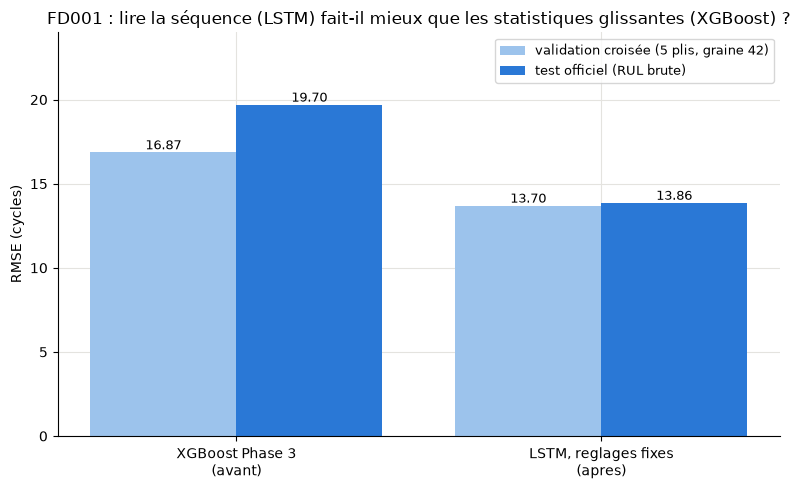

In [19]:
# --- Figure avant / apres : XGBoost Phase 3 contre le LSTM du 03b, validation et test cote a cote ---
noms_etape_3 = ["XGBoost Phase 3\n(avant)", "LSTM, reglages fixes\n(apres)"]
validation_etape_3 = [rmse_cv_phase3, lstm_03b["rmse_cv_moyen"]]
test_etape_3 = [rmse_test, lstm_03b["metriques_test"]["rmse"]]

positions = np.arange(len(noms_etape_3))
fig, ax = plt.subplots(figsize=(8, 5))
barres_val = ax.bar(positions - 0.2, validation_etape_3, width=0.4, color="#9cc3ec", label="validation croisée (5 plis, graine 42)")
barres_test = ax.bar(positions + 0.2, test_etape_3, width=0.4, color=COULEUR_1, label="test officiel (RUL brute)")
for barres in [barres_val, barres_test]:
    for barre in barres:
        ax.annotate(f"{barre.get_height():.2f}", (barre.get_x() + barre.get_width() / 2, barre.get_height()),
                    ha="center", va="bottom", fontsize=9)
ax.set_xticks(positions)
ax.set_xticklabels(noms_etape_3)
ax.set_ylabel("RMSE (cycles)")
ax.set_ylim(0, 24)
ax.legend(loc="upper right", fontsize=9)
ax.set_title("FD001 : lire la séquence (LSTM) fait-il mieux que les statistiques glissantes (XGBoost) ?")
plt.tight_layout()
plt.show()

ajouter_marche("3", "LSTM, reglages fixes a l'avance (16 entrees)", lstm_03b["rmse_cv_moyen"], "5 plis, graine 42",
               lstm_03b["metriques_test"]["rmse"], "recalcule ici (cache sorties/evolution/)")

### 3.3 Lecture de l'étape 3

- **Validation croisée** : le LSTM passe de 16,87 (XGBoost Phase 3) à 13,70 sur les mêmes plis.
- **Test officiel** : 19,70 → 13,86. Sur les 100 moteurs test, l'écart est significatif (tableau 3.2) : c'est le premier changement de l'escalier qui se voit nettement au test.
- **Limite** : un seul entraînement (graine 42) ; le 03b mesurait la robustesse à la graine sur 3 graines, qui n'est pas refaite ici.

In [20]:
verifier("Etape 3 : RMSE CV LSTM du 03b (recalcule)", 13.70, lstm_03b["rmse_cv_moyen"])
verifier("Etape 3 : RMSE CV LSTM du 03b (deduit des fichiers)", 13.70, rmse_cv_lstm_base_fichiers)
verifier("Etape 3 : RMSE test LSTM du 03b", 13.86, lstm_03b["metriques_test"]["rmse"])
verifier("Etape 3 : p Wilcoxon au test (significatif si < 0,05)", 1.0, float(comparaison_test_lstm["p_valeur_wilcoxon"] < 0.05), decimales=0)

OK    Etape 3 : RMSE CV LSTM du 03b (recalcule) : cite 13.7, calcule 13.7
OK    Etape 3 : RMSE CV LSTM du 03b (deduit des fichiers) : cite 13.7, calcule 13.7
OK    Etape 3 : RMSE test LSTM du 03b : cite 13.86, calcule 13.86
OK    Etape 3 : p Wilcoxon au test (significatif si < 0,05) : cite 1.0, calcule 1.0


True

## Étape 4 : l'écart à l'état initial (`ecartinit_20`), sur les 5 modèles qui apprennent

- **Ce qui change** : une famille de variables. Pour chaque capteur lissé x d'un moteur, `ecartinit_20(t) = x(t) − moyenne de x sur les 20 premiers cycles du moteur` (avant le cycle 20, la moyenne porte sur les cycles déjà vus : jamais un cycle futur). Pour les arbres, le jeu de **31 variables** (15 capteurs, `time_cycles`, 15 écarts) **remplace** les 46 de la Phase 3 ; pour les réseaux, les 15 écarts (mis à l'échelle entre 0 et 1) s'ajoutent aux 16 entrées.
- **Pourquoi** : deux moteurs neufs n'ont pas exactement les mêmes valeurs de capteurs ; ce qui annonce la panne, c'est de combien un moteur s'est éloigné de **son propre** état de départ. Idée de Matisse (04e), appliquée aux 5 modèles par Benjamin (05, section F).
- **Notebooks d'origine** : [04e_feature_engineering](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04e_feature_engineering.ipynb) (sections 8, test du jeu retenu), [05_comparaison_evaluation](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/05_comparaison_evaluation.ipynb) (sections B et D : la version « avant », à réglages de base ; F : la règle et le résultat). L'ablation complète (familles de variables, causalité) est dans `02_choix_du_modele`.

**Règle de décision**, écrite dans les scripts avant les expériences (texte enregistré dans `03b_candidats_fd001.json`, affiché ci-dessous) : une amélioration est retenue si, sur les mêmes 5 plis, (a) le RMSE moyen de validation baisse d'au moins 0,3 cycle **et** (b) le test de Wilcoxon apparié sur le RMSE par moteur donne p < 0,05 en faveur du candidat.

### 4.1 Avant : les modèles à arbres à réglages de base (46 variables), validation croisée

*Section B du notebook 05.* Quatre modèles à réglages par défaut, mêmes plis : la référence naïve (prédit toujours la moyenne), la Random Forest (200 arbres, profondeur non bornée), XGBoost Phase 3 et LightGBM (200 arbres, pas 0,05, 31 feuilles). Les colonnes : `rmse_cv_moyen` / `rmse_cv_ecart_type` (5 plis), `nasa_cv_moyen` (moyenne des scores NASA des plis, environ 4 000 lignes par pli), `surestimes_oof`, `alertes_manquees_oof`, `fausses_alertes_oof` (sur les 20 631 prédictions hors-pli), `biais_oof` (négatif = sous-estimation moyenne), temps d'entraînement des 5 plis.

In [21]:
import textwrap  # coupe les longs textes en lignes de largeur fixe pour l'affichage

print("Regle (scripts/entrainer_deep_learning.py et scripts/generer_predictions_arbres.py) :")
print(textwrap.fill(candidats_03b["regle"], width=110))


def resumer_cv(nom, resultats, nb_moteurs):
    """
    Resume les resultats d'une validation croisee en une ligne de tableau (un dictionnaire).

    Parameters
    ----------
    nom : str
        Le nom du modele (premiere colonne du tableau).
    resultats : dict
        Le dictionnaire renvoye par `evaluer_en_validation_croisee`.
    nb_moteurs : int
        Nombre de moteurs predits au total (100), pour le temps de prediction par moteur.

    Returns
    -------
    dict
        Les colonnes communes a tous les tableaux de validation croisee de ce notebook.
    """
    ligne = {}
    ligne["modele"] = nom
    ligne["rmse_cv_moyen"] = resultats["rmse_moyen"]
    ligne["rmse_cv_ecart_type"] = resultats["rmse_ecart_type"]
    ligne["mae_cv_moyen"] = resultats["mae_moyen"]
    ligne["nasa_cv_moyen"] = resultats["nasa_moyen"]
    ligne["surestimes_oof"] = resultats["surestimes_oof"]
    ligne["alertes_manquees_oof"] = resultats["alertes_manquees_oof"]
    ligne["fausses_alertes_oof"] = resultats["fausses_alertes_oof"]
    ligne["biais_oof"] = resultats["biais_oof"]
    ligne["temps_entrainement_5_plis_s"] = resultats["temps_entrainement_total"]
    # temps de prediction total des 5 plis (secondes) divise par le nombre de moteurs, converti en millisecondes
    ligne["prediction_ms_par_moteur"] = 1000.0 * resultats["temps_prediction_total"] / nb_moteurs
    return ligne


def resumer_test(nom, resultats_test):
    """
    Resume l'evaluation d'un modele sur le test officiel en une ligne de tableau (un dictionnaire).

    Parameters
    ----------
    nom : str
        Le nom du modele.
    resultats_test : dict
        Le dictionnaire renvoye par `evaluer_sur_test`.

    Returns
    -------
    dict
        RMSE (contre la RUL brute et contre la RUL plafonnee), MAE, score NASA, surestimes > 20,
        alertes manquees et fausses alertes, sur les 100 moteurs test.
    """
    ligne = {}
    ligne["modele"] = nom
    ligne["rmse_test"] = resultats_test["rmse"]
    ligne["rmse_test_rul_plafonnee"] = resultats_test["rmse_contre_rul_plafonnee"]
    ligne["mae_test"] = resultats_test["mae"]
    ligne["nasa_test"] = resultats_test["score_nasa"]
    ligne["surestimes_test"] = resultats_test["nb_surestimes"]
    ligne["alertes_manquees_test"] = resultats_test["alertes_manquees"]
    ligne["fausses_alertes_test"] = resultats_test["fausses_alertes"]
    return ligne


# les 4 modeles compares (section B du 05), avec au plus 4 coeurs (vitesse seulement)
CONFIG_XGB_PHASE3 = config_avec_coeurs(CONFIG_PHASE3)
CONFIG_RANDOM_FOREST = config_avec_coeurs(CONFIG_RANDOM_FOREST_BASE)  # tous les coeurs au 05 : memes predictions
CONFIGS_BASE = {}
CONFIGS_BASE["Reference naive"] = CONFIG_REFERENCE_NAIVE
CONFIGS_BASE["Random Forest"] = CONFIG_RANDOM_FOREST
CONFIGS_BASE["XGBoost Phase 3"] = CONFIG_XGB_PHASE3
CONFIGS_BASE["LightGBM"] = config_avec_coeurs(CONFIG_LIGHTGBM_BASE)
NB_MOTEURS_TRAIN = int(groups.nunique())

resultats_cv_base = {}  # nom du modele -> dictionnaire renvoye par evaluer_en_validation_croisee
for nom_modele in CONFIGS_BASE:  # un modele a la fois, toujours sur les memes plis
    fabrique = construire_fabrique_depuis_config(CONFIGS_BASE[nom_modele])
    debut = time.perf_counter()
    resultats_cv_base[nom_modele] = evaluer_en_validation_croisee(
        fabrique, X, y, groups, plis, seuil_surestimation=SEUIL_SURESTIMATION, seuil_alerte=SEUIL_ALERTE
    )
    print(f"{nom_modele:16s} : RMSE CV moyen = {resultats_cv_base[nom_modele]['rmse_moyen']:.2f} "
          f"({time.perf_counter() - debut:.1f} s)")

lignes = []  # une ligne de tableau par modele
for nom_modele in resultats_cv_base:
    lignes.append(resumer_cv(nom_modele, resultats_cv_base[nom_modele], NB_MOTEURS_TRAIN))
tableau_cv_base = pd.DataFrame(lignes).set_index("modele")
tableau_cv_base.round(2)

Regle (scripts/entrainer_deep_learning.py et scripts/generer_predictions_arbres.py) :
Pour chaque modele, une amelioration est retenue sur FD001 si, sur les memes 5 plis par moteur, (a) le RMSE
moyen de validation baisse d'au moins 0,3 cycle (seuil de Matisse, notebook 04d) ET (b) le test de Wilcoxon
apparie sur le RMSE par moteur (100 moteurs, prediction hors-pli) donne p < 0,05 en faveur du candidat. Sinon
on garde la version de base. Le score NASA et les surestimations de plus de 20 cycles sont rapportes a cote ;
si le candidat les degrade nettement, le dire. Les choix faits sur FD001 sont appliques tels quels a
FD002-FD004 (le dire comme limite).
Reference naive  : RMSE CV moyen = 41.69 (0.0 s)


Random Forest    : RMSE CV moyen = 16.96 (55.7 s)


XGBoost Phase 3  : RMSE CV moyen = 16.87 (1.8 s)


LightGBM         : RMSE CV moyen = 16.85 (3.6 s)


,rmse_cv_moyen,rmse_cv_ecart_type,mae_cv_moyen,nasa_cv_moyen,surestimes_oof,alertes_manquees_oof,fausses_alertes_oof,biais_oof,temps_entrainement_5_plis_s,prediction_ms_par_moteur
modele,,,,,,,,,,
Reference naive,41.69,0.12,36.98,1271461.74,6720,3100,0,-0.02,0.00,0.00
Random Forest,16.96,1.27,11.47,29772.64,2302,565,252,-0.28,55.59,1.32
XGBoost Phase 3,16.87,1.25,11.50,29782.56,2384,552,259,-0.16,1.77,0.12
LightGBM,16.85,1.30,11.37,30141.85,2316,568,243,-0.22,3.55,0.34


**Les écarts sont-ils significatifs ?** (05, B.2) Test apparié **moteur par moteur** (mêmes 100 moteurs) : test t sur la différence moyenne, Wilcoxon signé sur les rangs. Trois comparaisons contre XGBoost Phase 3, donc seuil de Bonferroni p < 0,05 / 3 ≈ 0,017 pour chacune. Différence moyenne négative = le modèle a un RMSE par moteur plus petit que XGBoost.

In [22]:
# RMSE hors-pli de chaque moteur, pour chaque modele (100 lignes, triees par numero de moteur)
erreurs_moteur_base = {}
for nom_modele in resultats_cv_base:
    erreurs_moteur_base[nom_modele] = erreurs_par_moteur(y, resultats_cv_base[nom_modele]["predictions_oof"], groups)

rmse_moteur_xgb_base = erreurs_moteur_base["XGBoost Phase 3"]["rmse"].to_numpy()  # reference des comparaisons
SEUIL_BONFERRONI = 0.05 / 3  # 3 comparaisons contre XGBoost Phase 3

lignes = []
for nom_modele in resultats_cv_base:
    if nom_modele == "XGBoost Phase 3":
        continue  # on ne compare pas XGBoost a lui-meme
    rmse_moteur_modele = erreurs_moteur_base[nom_modele]["rmse"].to_numpy()
    comparaison = comparer_apparie(rmse_moteur_modele, rmse_moteur_xgb_base)
    ligne = {}
    ligne["modele (vs XGBoost Phase 3)"] = nom_modele
    ligne["difference_moyenne_rmse_par_moteur"] = comparaison["difference_moyenne"]
    ligne["moteurs_ou_le_modele_est_meilleur"] = int(np.sum(rmse_moteur_modele < rmse_moteur_xgb_base))
    ligne["p_valeur_t"] = comparaison["p_valeur_t"]
    ligne["p_valeur_wilcoxon"] = comparaison["p_valeur_wilcoxon"]
    # significatif seulement si les DEUX tests passent sous le seuil de Bonferroni
    ligne["significatif_bonferroni"] = (comparaison["p_valeur_t"] < SEUIL_BONFERRONI) and (
        comparaison["p_valeur_wilcoxon"] < SEUIL_BONFERRONI)
    lignes.append(ligne)
tableau_tests_base = pd.DataFrame(lignes).set_index("modele (vs XGBoost Phase 3)")
tableau_tests_base.round(4)

,difference_moyenne_rmse_par_moteur,moteurs_ou_le_modele_est_meilleur,p_valeur_t,p_valeur_wilcoxon,significatif_bonferroni
modele (vs XGBoost Phase 3),,,,,
Reference naive,26.3202,0,0.0000,0.0000,True
Random Forest,0.0313,46,0.7830,0.5775,False
LightGBM,-0.0239,52,0.7867,0.8045,False


### 4.2 Avant : les mêmes modèles sur le test officiel (une seule fois)

*Section D du notebook 05.* Les trois ensembles d'arbres sont entraînés sur les 100 moteurs, puis évalués au dernier cycle de chaque moteur test, contre la RUL brute (et contre la RUL plafonnée à 125). Test apparié sur l'erreur absolue par moteur (D.1), et score NASA moteur par moteur (D.2) : le score est une somme d'exponentielles, une seule grosse surestimation peut en faire l'essentiel.

In [23]:
configs_finales_base = {}  # nom -> configuration des modeles evalues sur le test (ceux de la section 4.1)
configs_finales_base["XGBoost Phase 3"] = CONFIG_XGB_PHASE3
configs_finales_base["Random Forest"] = CONFIG_RANDOM_FOREST
configs_finales_base["LightGBM"] = CONFIGS_BASE["LightGBM"]

moteurs_test_ordre = contexte_test["moteurs_test"]  # numeros des moteurs test, meme ordre que y_test_vraie
resultats_test = {}  # nom -> dictionnaire renvoye par evaluer_sur_test
for nom_modele in configs_finales_base:
    modele_test = construire_fabrique_depuis_config(configs_finales_base[nom_modele])()  # modele neuf
    modele_test.fit(X, y)  # entraine sur les 100 moteurs d'entrainement
    resultats_test[nom_modele] = evaluer_sur_test(modele_test, X_test_dernier, y_test_vraie, plafond=PLAFOND_RUL,
                                                  seuil_surestimation=SEUIL_SURESTIMATION, seuil_alerte=SEUIL_ALERTE)

lignes = []
for nom_modele in resultats_test:
    lignes.append(resumer_test(nom_modele, resultats_test[nom_modele]))
tableau_test_base = pd.DataFrame(lignes).set_index("modele")
display(tableau_test_base.round(2))

# D.1 : test apparie sur l'erreur absolue de chaque moteur test, contre XGBoost Phase 3
erreurs_absolues_phase3 = np.abs(resultats_test["XGBoost Phase 3"]["predictions"] - y_test_vraie)
lignes = []
for nom_modele in resultats_test:
    if nom_modele == "XGBoost Phase 3":
        continue
    erreurs_absolues_modele = np.abs(resultats_test[nom_modele]["predictions"] - y_test_vraie)
    comparaison = comparer_apparie(erreurs_absolues_modele, erreurs_absolues_phase3)
    ligne = {}
    ligne["modele (vs XGBoost Phase 3)"] = nom_modele
    ligne["difference_moyenne_erreur_absolue"] = comparaison["difference_moyenne"]
    ligne["moteurs_ou_le_modele_est_meilleur"] = int(np.sum(erreurs_absolues_modele < erreurs_absolues_phase3))
    ligne["p_valeur_t"] = comparaison["p_valeur_t"]
    ligne["p_valeur_wilcoxon"] = comparaison["p_valeur_wilcoxon"]
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("modele (vs XGBoost Phase 3)").round(4))

# D.2 : penalite NASA de chaque moteur test, les 5 moteurs les plus penalises par la Phase 3
penalites_test = {}  # nom -> penalite NASA de chacun des 100 moteurs test
for nom_modele in resultats_test:
    tableau_moteurs_modele = script_arbres.metriques_par_moteur(y_test_vraie, resultats_test[nom_modele]["predictions"],
                                                                moteurs_test_ordre)
    penalites_test[nom_modele] = tableau_moteurs_modele["nasa"].to_numpy()
ordre = np.argsort(-penalites_test["XGBoost Phase 3"])  # positions triees du plus penalise au moins penalise
lignes = []
for position in ordre[:5]:
    ligne = {}
    ligne["unit_number"] = moteurs_test_ordre[position]
    ligne["rul_vraie"] = y_test_vraie[position]
    for nom_modele in resultats_test:
        ligne[nom_modele] = penalites_test[nom_modele][position]
    lignes.append(ligne)
print("Les 5 moteurs les plus penalises par la Phase 3 (penalite NASA de chaque modele) :")
display(pd.DataFrame(lignes).set_index("unit_number").round(1))
position_pire = ordre[0]
for nom_modele in resultats_test:
    total = float(np.sum(penalites_test[nom_modele]))  # le score NASA du test = somme des 100 penalites
    print(f"  {nom_modele:16s} : score NASA {total:7.1f} avec le moteur {moteurs_test_ordre[position_pire]}, "
          f"{total - penalites_test[nom_modele][position_pire]:7.1f} sans")

,rmse_test,rmse_test_rul_plafonnee,mae_test,nasa_test,surestimes_test,alertes_manquees_test,fausses_alertes_test
modele,,,,,,,
XGBoost Phase 3,19.70,18.53,14.36,852.89,9,7,1
Random Forest,19.52,18.34,14.34,786.67,11,7,1
LightGBM,20.45,19.31,14.97,902.72,11,7,1


,difference_moyenne_erreur_absolue,moteurs_ou_le_modele_est_meilleur,p_valeur_t,p_valeur_wilcoxon
modele (vs XGBoost Phase 3),,,,
Random Forest,-0.0161,50,0.9687,0.7648
LightGBM,0.6124,42,0.0830,0.1374


Les 5 moteurs les plus penalises par la Phase 3 (penalite NASA de chaque modele) :


,rul_vraie,XGBoost Phase 3,Random Forest,LightGBM
unit_number,,,,
37,21,223.6,176.5,132.3
89,136,93.2,84.9,140.0
45,114,69.2,61.5,70.5
67,77,44.3,40.8,43.3
74,126,36.2,34.7,27.7


  XGBoost Phase 3  : score NASA   852.9 avec le moteur 37,   629.3 sans
  Random Forest    : score NASA   786.7 avec le moteur 37,   610.2 sans
  LightGBM         : score NASA   902.7 avec le moteur 37,   770.5 sans


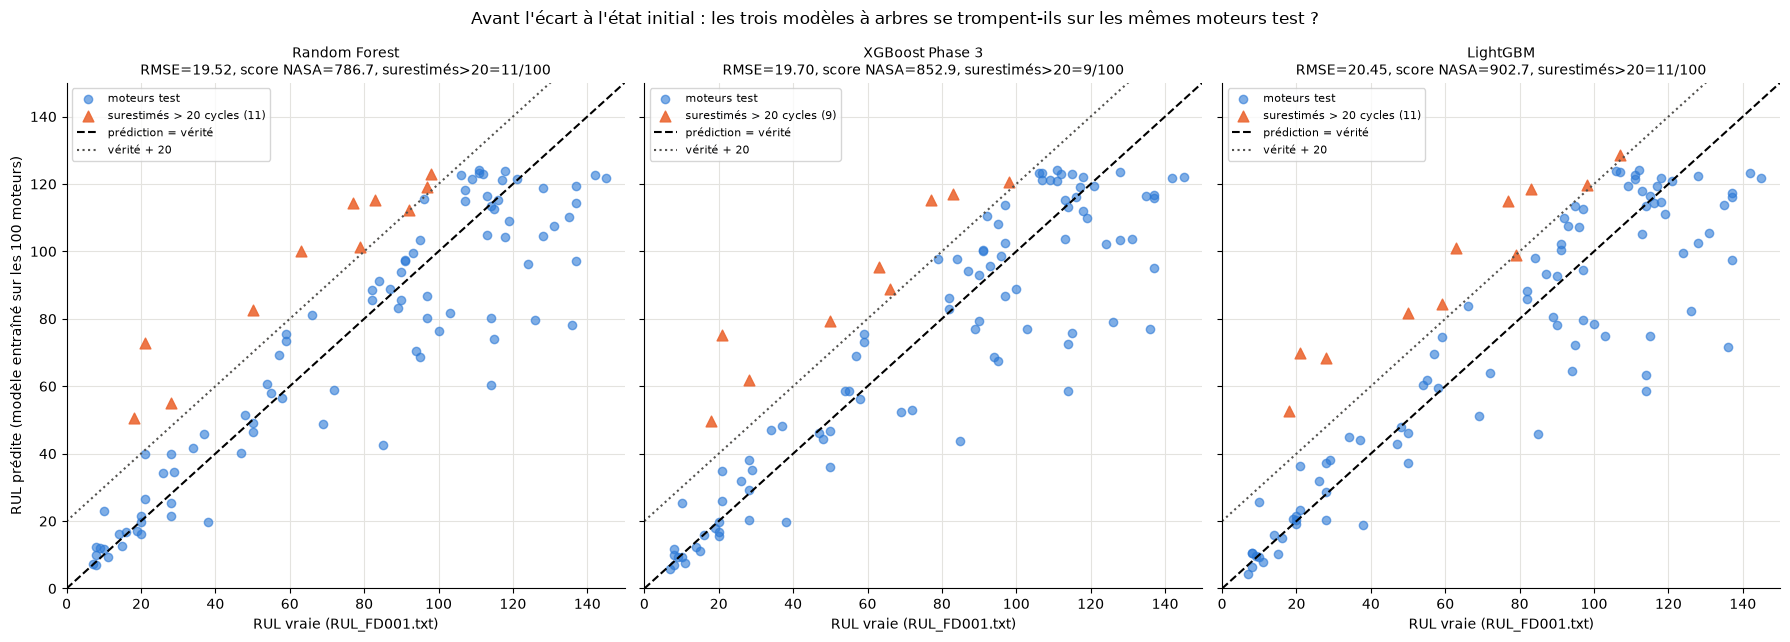

In [24]:
noms_figure_test = ["Random Forest", "XGBoost Phase 3", "LightGBM"]
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), sharex=True, sharey=True)  # memes axes pour comparer les panneaux

# bord des axes : la plus grande RUL (vraie ou predite) des trois modeles, plus 5 cycles de marge
limite = y_test_vraie.max()
for nom_modele in noms_figure_test:
    limite = max(limite, resultats_test[nom_modele]["predictions"].max())
limite = limite + 5

for ax, nom_modele in zip(axes, noms_figure_test):  # un panneau par modele
    predictions = resultats_test[nom_modele]["predictions"]
    ecarts = predictions - y_test_vraie
    surestime = ecarts > SEUIL_SURESTIMATION  # Vrai pour les moteurs surestimes de plus de 20 cycles
    ax.scatter(y_test_vraie[~surestime], predictions[~surestime], alpha=0.6, color=COULEUR_1, label="moteurs test")
    ax.scatter(y_test_vraie[surestime], predictions[surestime], alpha=0.9, color=COULEUR_2, marker="^", s=60,
               label=f"surestimés > {SEUIL_SURESTIMATION} cycles ({int(surestime.sum())})")
    ax.plot([0, limite], [0, limite], linestyle="--", color="black", label="prédiction = vérité")
    ax.plot([0, limite], [SEUIL_SURESTIMATION, limite + SEUIL_SURESTIMATION], linestyle=":", color=COULEUR_TEXTE,
            label=f"vérité + {SEUIL_SURESTIMATION}")
    resultats = resultats_test[nom_modele]
    ax.set_title(f"{nom_modele}\nRMSE={resultats['rmse']:.2f}, score NASA={resultats['score_nasa']:.1f}, "
                 f"surestimés>20={resultats['nb_surestimes']}/100", fontsize=10)
    ax.set_xlabel("RUL vraie (RUL_FD001.txt)")
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("RUL prédite (modèle entraîné sur les 100 moteurs)")
fig.suptitle("Avant l'écart à l'état initial : les trois modèles à arbres se trompent-ils sur les mêmes moteurs test ?")
plt.tight_layout()
plt.show()

**Lecture de l'« avant »** (conclusions B.4 et D.4 du 05) : en validation, la référence naïve est loin derrière (RMSE CV 41,69), et les trois ensembles d'arbres sont à égalité statistique (Random Forest 16,96, XGBoost Phase 3 16,87, LightGBM 16,85 ; tests appariés non significatifs). Sur le test, ils restent proches (RMSE 19,52, 19,70, 20,45), sans différence significative avec 100 moteurs ; un seul moteur (le 37) pèse plus du quart du score NASA de la Phase 3.

In [25]:
verifier("Etape 4 avant : RMSE CV reference naive", 41.69, resultats_cv_base["Reference naive"]["rmse_moyen"])
verifier("Etape 4 avant : RMSE CV Random Forest", 16.96, resultats_cv_base["Random Forest"]["rmse_moyen"])
verifier("Etape 4 avant : RMSE CV XGBoost Phase 3", 16.87, resultats_cv_base["XGBoost Phase 3"]["rmse_moyen"])
verifier("Etape 4 avant : score NASA CV XGBoost Phase 3", 29782.6, resultats_cv_base["XGBoost Phase 3"]["nasa_moyen"], decimales=1)
verifier("Etape 4 avant : RMSE CV LightGBM", 16.85, resultats_cv_base["LightGBM"]["rmse_moyen"])
verifier("Etape 4 avant : aucun test apparie significatif (Bonferroni)", 0, int(tableau_tests_base["significatif_bonferroni"].iloc[1:].sum()), decimales=0)
verifier("Etape 4 avant : RMSE test Random Forest", 19.52, resultats_test["Random Forest"]["rmse"])
verifier("Etape 4 avant : RMSE test XGBoost Phase 3", 19.70, resultats_test["XGBoost Phase 3"]["rmse"])
verifier("Etape 4 avant : RMSE test LightGBM", 20.45, resultats_test["LightGBM"]["rmse"])
verifier("Etape 4 avant : moteur le plus penalise (Phase 3)", 37, moteurs_test_ordre[position_pire], decimales=0)
part_moteur_pire = penalites_test["XGBoost Phase 3"][position_pire] / np.sum(penalites_test["XGBoost Phase 3"])
verifier("Etape 4 avant : ce moteur pese plus du quart du score NASA", 1, float(part_moteur_pire > 0.25), decimales=0)

OK    Etape 4 avant : RMSE CV reference naive : cite 41.69, calcule 41.69
OK    Etape 4 avant : RMSE CV Random Forest : cite 16.96, calcule 16.96
OK    Etape 4 avant : RMSE CV XGBoost Phase 3 : cite 16.87, calcule 16.87
OK    Etape 4 avant : score NASA CV XGBoost Phase 3 : cite 29782.6, calcule 29782.6
OK    Etape 4 avant : RMSE CV LightGBM : cite 16.85, calcule 16.85
OK    Etape 4 avant : aucun test apparie significatif (Bonferroni) : cite 0, calcule 0.0
OK    Etape 4 avant : RMSE test Random Forest : cite 19.52, calcule 19.52
OK    Etape 4 avant : RMSE test XGBoost Phase 3 : cite 19.7, calcule 19.7
OK    Etape 4 avant : RMSE test LightGBM : cite 20.45, calcule 20.45
OK    Etape 4 avant : moteur le plus penalise (Phase 3) : cite 37, calcule 37.0
OK    Etape 4 avant : ce moteur pese plus du quart du score NASA : cite 1, calcule 1.0


True

### 4.3 Après : les modèles à arbres avec les 31 variables (mêmes réglages de base, mêmes plis)

Seule la liste de variables change. La règle est appliquée par la fonction du script des arbres (`appliquer_regle_de_decision`), sur les prédictions hors-pli : baisse du RMSE CV, Wilcoxon bilatéral sur le RMSE par moteur, et indicateurs de prudence (score NASA de validation, lignes surestimées de plus de 20 cycles, alertes manquées) rapportés à côté. La référence naïve n'utilise pas les variables : aucun test n'est possible, elle garde la base.

In [26]:
contexte_train_31 = preparer_train(fenetre=5, plafond=PLAFOND_RUL, ecart_initial=20)  # 31 features (04e)
contexte_test_31 = preparer_test(contexte_train_31)
X31 = contexte_train_31["X"]
assert X31.shape == (20631, 31)
assert np.array_equal(contexte_train_31["groups"].to_numpy(), groups.to_numpy())  # memes lignes : memes plis

CLES_ARBRES = {"Reference naive": "reference_naive", "Random Forest": "random_forest",
               "XGBoost Phase 3": "xgboost_phase3", "LightGBM": "lightgbm"}  # nom affiche -> cle du script
resultats_cv_31 = {}  # nom -> validation croisee avec les 31 variables (reglages de base)
decisions_31 = {}     # nom -> resultat de la regle de decision
for nom_modele in CONFIGS_BASE:
    par_moteur_base = script_arbres.metriques_par_moteur(y, resultats_cv_base[nom_modele]["predictions_oof"], groups)
    resultats_cv_31[nom_modele], par_moteur_31, _ = script_arbres.valider_un_jeu(contexte_train_31, CONFIGS_BASE[nom_modele], plis)
    decisions_31[nom_modele] = script_arbres.appliquer_regle_de_decision(resultats_cv_base[nom_modele], resultats_cv_31[nom_modele],
                                                                          par_moteur_base, par_moteur_31)

lignes = []
for nom_modele in decisions_31:
    decision = decisions_31[nom_modele]
    ligne = {}
    ligne["modele"] = nom_modele
    ligne["rmse_cv_base_46"] = f"{decision['rmse_cv_base']:.2f} ± {decision['rmse_cv_ecart_type_base']:.2f}"
    ligne["rmse_cv_candidat_31"] = f"{decision['rmse_cv_candidat']:.2f} ± {decision['rmse_cv_ecart_type_candidat']:.2f}"
    ligne["baisse"] = round(decision["baisse_rmse_cv"], 2)
    ligne["(a) baisse >= 0,3"] = decision["condition_a_baisse_rmse"]
    ligne["p_wilcoxon"] = decision["p_wilcoxon_bilaterale"]
    ligne["moteurs_meilleurs"] = decision["nb_moteurs_candidat_meilleur"]
    ligne["(b) p < 0,05 en faveur"] = decision["condition_b_wilcoxon"]
    ligne["surestimes_oof base -> candidat"] = f"{decision['surestimes_oof_base']} -> {decision['surestimes_oof_candidat']}"
    ligne["alertes_manquees_oof base -> candidat"] = (
        f"{decision['alertes_manquees_oof_base']} -> {decision['alertes_manquees_oof_candidat']}")
    ligne["decision"] = decision["jeu_selon_regle"]
    lignes.append(ligne)
pd.DataFrame(lignes).set_index("modele")

,rmse_cv_base_46,rmse_cv_candidat_31,baisse,"(a) baisse >= 0,3",p_wilcoxon,moteurs_meilleurs,"(b) p < 0,05 en faveur",surestimes_oof base -> candidat,alertes_manquees_oof base -> candidat,decision
modele,,,,,,,,,,
Reference naive,41.69 ± 0.12,41.69 ± 0.12,0.00,False,NaN,0,False,6720 -> 6720,3100 -> 3100,base
Random Forest,16.96 ± 1.27,10.19 ± 0.69,6.78,True,7.331433e-14,84,True,2302 -> 876,565 -> 321,ecart_initial_20
XGBoost Phase 3,16.87 ± 1.25,9.36 ± 0.33,7.51,True,9.868085e-16,87,True,2384 -> 754,552 -> 254,ecart_initial_20
LightGBM,16.85 ± 1.30,9.35 ± 0.48,7.50,True,4.286371e-15,85,True,2316 -> 758,568 -> 258,ecart_initial_20


### 4.4 Après : les réseaux avec l'écart à l'état initial (lu dans les fichiers versionnés du 03b)

Pour les réseaux, la comparaison « base » contre « A » (= base + les 15 écarts) a été faite par `scripts/entrainer_deep_learning.py` ; on la **relit** dans `docs/resultats/03b/` : RMSE de validation de la version retenue (`03b_deep_learning.csv`) et gain par rapport à la base (`03b_candidats_fd001.json`). Le RMSE de la base s'en déduit (A + gain) ; pour le LSTM, il est aussi recalculé à l'étape 3.

La même cellule relit l'**idée 2 du 05** (fenêtre de 50 cycles au lieu de 30, tirée des articles DAST et STAGNN), non retenue : candidats B (fenêtre 50) et AB (fenêtre 50 + écart), avec la même règle.

In [27]:
lignes = []
rmse_cv_reseaux = {}  # reseau -> (RMSE CV base, RMSE CV avec ecart, ecart-type avec ecart)
for reseau, nom_reseau in [("lstm", "LSTM"), ("cnn1d", "CNN 1D")]:
    ligne_a = resultats_03b[(resultats_03b["sous_jeu"] == "FD001") & (resultats_03b["modele"] == reseau)].iloc[0]
    decision_reseau = candidats_03b["decisions"][reseau]
    comparaison_a = decision_reseau["comparaisons"]["A"]
    rmse_base_deduit = ligne_a["rmse_validation"] + comparaison_a["gain_rmse"]  # base = A + gain
    rmse_cv_reseaux[reseau] = (rmse_base_deduit, ligne_a["rmse_validation"], ligne_a["rmse_validation_ecart_type"])
    for code_candidat in ["A", "B", "AB"]:
        if code_candidat not in decision_reseau["comparaisons"]:
            continue  # AB n'est evalue que si A et B passent chacun la regle
        comparaison = decision_reseau["comparaisons"][code_candidat]
        ligne = {}
        ligne["reseau"] = nom_reseau
        ligne["candidat"] = code_candidat
        ligne["entrees"] = str(candidats_03b["configurations"][code_candidat])
        ligne["gain_rmse_cv"] = comparaison["gain_rmse"]
        ligne["p_wilcoxon"] = comparaison["p_wilcoxon"]
        ligne["moteurs_ameliores"] = comparaison["nb_moteurs_ameliores"]
        ligne["(a)"] = comparaison["critere_a"]
        ligne["(b)"] = comparaison["critere_b"]
        ligne["retenu"] = comparaison["retenu"]
        lignes.append(ligne)
    print(f"{nom_reseau:7s} : RMSE CV base {rmse_base_deduit:.2f} (deduit) -> avec ecartinit_20 {ligne_a['rmse_validation']:.2f} ; "
          f"version retenue = {decision_reseau['configuration_retenue']} (fenetre {decision_reseau['longueur_fenetre']} cycles)")
pd.DataFrame(lignes).set_index(["reseau", "candidat"]).round(4)

LSTM    : RMSE CV base 13.70 (deduit) -> avec ecartinit_20 8.94 ; version retenue = A (fenetre 30 cycles)
CNN 1D  : RMSE CV base 16.96 (deduit) -> avec ecartinit_20 10.05 ; version retenue = A (fenetre 30 cycles)


entrees  gain_rmse_cv  p_wilcoxon  moteurs_ameliores    (a)    (b)  retenu
reseau candidat                                                                                                            
LSTM   A           {'longueur': 30, 'ecart_initial': 20}        4.7559      0.0000                 83   True   True    True
       B         {'longueur': 50, 'ecart_initial': None}        2.3769      0.0000                 77   True   True    True
       AB          {'longueur': 50, 'ecart_initial': 20}       -0.3734      0.0629                 41  False  False   False
CNN 1D A           {'longueur': 30, 'ecart_initial': 20}        6.9171      0.0000                 85   True   True    True
       B         {'longueur': 50, 'ecart_initial': None}        0.8900      0.4093                 54   True  False   False

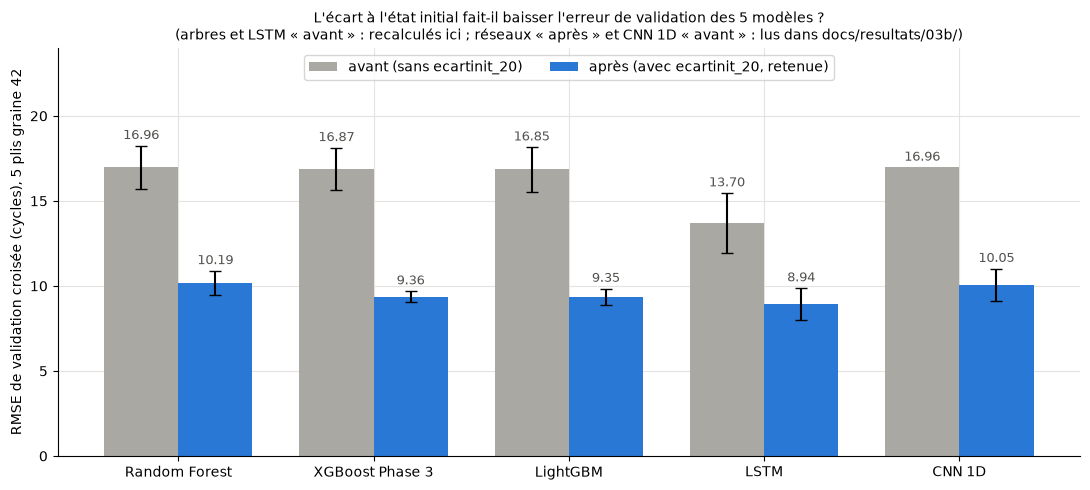

In [28]:
# --- Figure avant / apres (05, F.6) : RMSE de validation des 5 modeles, sans puis avec ecartinit_20 ---
noms_figure = []
rmse_avant = []
ecart_avant = []   # ecart-type entre plis (NaN s'il n'est pas enregistre)
rmse_apres = []
ecart_apres = []
for nom_modele in ["Random Forest", "XGBoost Phase 3", "LightGBM"]:  # arbres : recalcules en 4.1 et 4.3
    noms_figure.append(nom_modele)
    rmse_avant.append(resultats_cv_base[nom_modele]["rmse_moyen"])
    ecart_avant.append(resultats_cv_base[nom_modele]["rmse_ecart_type"])
    rmse_apres.append(resultats_cv_31[nom_modele]["rmse_moyen"])
    ecart_apres.append(resultats_cv_31[nom_modele]["rmse_ecart_type"])
# LSTM : base recalculee a l'etape 3, version avec ecart lue dans 03b_deep_learning.csv
noms_figure.append("LSTM")
rmse_avant.append(lstm_03b["rmse_cv_moyen"])
ecart_avant.append(float(np.std(lstm_03b["rmse_par_pli"])))
rmse_apres.append(rmse_cv_reseaux["lstm"][1])
ecart_apres.append(rmse_cv_reseaux["lstm"][2])
# CNN 1D : base deduite des fichiers (ecart-type non enregistre), version avec ecart lue
noms_figure.append("CNN 1D")
rmse_avant.append(rmse_cv_reseaux["cnn1d"][0])
ecart_avant.append(np.nan)
rmse_apres.append(rmse_cv_reseaux["cnn1d"][1])
ecart_apres.append(rmse_cv_reseaux["cnn1d"][2])

positions_f6 = np.arange(len(noms_figure))
largeur = 0.38
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(positions_f6 - largeur / 2, rmse_avant, width=largeur, color=COULEUR_GRIS, label="avant (sans ecartinit_20)")
ax.bar(positions_f6 + largeur / 2, rmse_apres, width=largeur, color=COULEUR_1, label="après (avec ecartinit_20, retenue)")
for position in range(len(noms_figure)):  # barres d'erreur seulement quand l'ecart-type est connu
    if not np.isnan(ecart_avant[position]):
        ax.errorbar(position - largeur / 2, rmse_avant[position], yerr=ecart_avant[position], color="black", capsize=4)
    ax.errorbar(position + largeur / 2, rmse_apres[position], yerr=ecart_apres[position], color="black", capsize=4)
    hauteur_avant = rmse_avant[position] + 0.4  # etiquette au-dessus de la barre d'erreur quand elle existe
    if not np.isnan(ecart_avant[position]):
        hauteur_avant = hauteur_avant + ecart_avant[position]
    hauteur_apres = rmse_apres[position] + ecart_apres[position] + 0.4
    ax.text(position - largeur / 2, hauteur_avant, f"{rmse_avant[position]:.2f}", ha="center", fontsize=9, color=COULEUR_TEXTE)
    ax.text(position + largeur / 2, hauteur_apres, f"{rmse_apres[position]:.2f}", ha="center", fontsize=9, color=COULEUR_TEXTE)
ax.set_xticks(positions_f6)
ax.set_xticklabels(noms_figure)
ax.set_ylabel("RMSE de validation croisée (cycles), 5 plis graine 42")
ax.set_ylim(0, 24)
ax.set_title("L'écart à l'état initial fait-il baisser l'erreur de validation des 5 modèles ?\n"
             "(arbres et LSTM « avant » : recalculés ici ; réseaux « après » et CNN 1D « avant » : lus dans docs/resultats/03b/)",
             fontsize=10)
ax.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

### 4.5 Après : le test officiel FD001 (une seule fois par version retenue)

Arbres : entraînés sur les 100 moteurs avec les 31 variables (réglages de base), évalués au dernier cycle. Réseaux : lus dans `03b_deep_learning.csv` (graine 42). Pour XGBoost, comme au 04e (section 8), on compare aussi le jeu retenu à la Phase 3 **moteur par moteur** sur le test (Wilcoxon apparié sur l'erreur absolue) : les chiffres de la Phase 3 étaient déjà publiés, ce n'est pas une nouvelle lecture du test pour un choix.

In [29]:
resultats_test_31 = {}  # nom -> test officiel avec les 31 variables, reglages de base
for nom_modele in ["Random Forest", "XGBoost Phase 3", "LightGBM"]:
    modele_31 = construire_fabrique_depuis_config(CONFIGS_BASE[nom_modele])()
    modele_31.fit(X31, y)
    resultats_test_31[nom_modele] = evaluer_sur_test(modele_31, contexte_test_31["X_test_dernier"], y_test_vraie,
                                                     plafond=PLAFOND_RUL, seuil_surestimation=SEUIL_SURESTIMATION,
                                                     seuil_alerte=SEUIL_ALERTE)

lignes = []
for nom_modele in resultats_test_31:
    ligne = resumer_test(nom_modele + " (31 variables)", resultats_test_31[nom_modele])
    ligne["rmse_test_avant_46"] = resultats_test[nom_modele]["rmse"]
    lignes.append(ligne)
for reseau, nom_reseau in [("lstm", "LSTM"), ("cnn1d", "CNN 1D")]:  # lus dans le fichier versionne
    ligne_a = resultats_03b[(resultats_03b["sous_jeu"] == "FD001") & (resultats_03b["modele"] == reseau)].iloc[0]
    ligne = {}
    ligne["modele"] = nom_reseau + " (avec ecartinit_20, fichier 03b_deep_learning.csv)"
    ligne["rmse_test"] = ligne_a["rmse_test"]
    ligne["rmse_test_rul_plafonnee"] = ligne_a["rmse_test_rul_plafonnee"]
    ligne["mae_test"] = ligne_a["mae_test"]
    ligne["nasa_test"] = ligne_a["nasa_test"]
    ligne["surestimes_test"] = ligne_a["surestimes_test"]
    ligne["alertes_manquees_test"] = ligne_a["alertes_manquees_test"]
    ligne["fausses_alertes_test"] = ligne_a["fausses_alertes_test"]
    ligne["rmse_test_avant_46"] = np.nan
    lignes.append(ligne)
ligne_lstm = lignes[3]
ligne_lstm["rmse_test_avant_46"] = lstm_03b["metriques_test"]["rmse"]  # le LSTM "avant" : etape 3
display(pd.DataFrame(lignes).set_index("modele").round(2))

# 04e, section 8 : XGBoost, jeu retenu contre Phase 3, moteur par moteur sur le test
erreur_abs_ref46 = np.abs(resultats_test["XGBoost Phase 3"]["predictions"] - y_test_vraie)
erreur_abs_final = np.abs(resultats_test_31["XGBoost Phase 3"]["predictions"] - y_test_vraie)
p_wilcoxon_04e = stats.wilcoxon(erreur_abs_ref46 - erreur_abs_final).pvalue
moteurs_mieux_04e = int(np.sum(erreur_abs_final < erreur_abs_ref46))
print(f"XGBoost, erreur absolue moteur par moteur sur le test : les 31 variables font mieux sur {moteurs_mieux_04e}/100 moteurs, "
      f"Wilcoxon apparie p = {p_wilcoxon_04e:.4f}")

ajouter_marche("4a", "XGBoost, 31 variables (avec ecartinit_20)", resultats_cv_31["XGBoost Phase 3"]["rmse_moyen"],
               "5 plis, graine 42", resultats_test_31["XGBoost Phase 3"]["rmse"], "recalcule ici")
ligne_lstm_a = resultats_03b[(resultats_03b["sous_jeu"] == "FD001") & (resultats_03b["modele"] == "lstm")].iloc[0]
ajouter_marche("4b", "LSTM, 31 entrees (avec ecartinit_20)", ligne_lstm_a["rmse_validation"], "5 plis, graine 42",
               ligne_lstm_a["rmse_test"], "lu : docs/resultats/03b/03b_deep_learning.csv")

,rmse_test,rmse_test_rul_plafonnee,mae_test,nasa_test,surestimes_test,alertes_manquees_test,fausses_alertes_test,rmse_test_avant_46
modele,,,,,,,,
Random Forest (31 variables),14.27,13.03,10.23,301.89,3,4,1,19.52
XGBoost Phase 3 (31 variables),13.10,11.88,9.58,237.00,2,3,0,19.70
LightGBM (31 variables),13.40,12.12,9.53,283.61,3,3,0,20.45
"LSTM (avec ecartinit_20, fichier 03b_deep_learning.csv)",12.29,11.37,8.33,228.67,5,1,1,13.86
"CNN 1D (avec ecartinit_20, fichier 03b_deep_learning.csv)",12.74,12.38,9.21,346.40,11,0,1,NaN


XGBoost, erreur absolue moteur par moteur sur le test : les 31 variables font mieux sur 60/100 moteurs, Wilcoxon apparie p = 0.0004


### 4.6 Arbres et réseaux sur le test officiel FD001 (03b, F.6)

*Notebook 03b, section F.6, déplacée avec sa cellule* (figure retirée par une première version du plan, gardée par la règle « aucun graphe supprimé » du 2026-11-07). « Avant » pour les arbres : XGBoost Phase 3 (46 variables, section 4.2) ; réseaux : la version retenue du 03b (avec l'écart à l'état initial, graine 42), prédictions au dernier cycle relues dans `docs/resultats/03b/03b_predictions_test_fd001.csv`.

**Comment lire** (03b, F.6) : diagonale = prédiction parfaite ; au-dessus = surestimation (dangereux) ; les moteurs surestimés de plus de 20 cycles sont en triangles orange. La ligne horizontale pointillée rappelle le plafond de 125 : aucun modèle n'a appris à prédire au-delà, d'où l'erreur sur les moteurs de RUL vraie > 125.

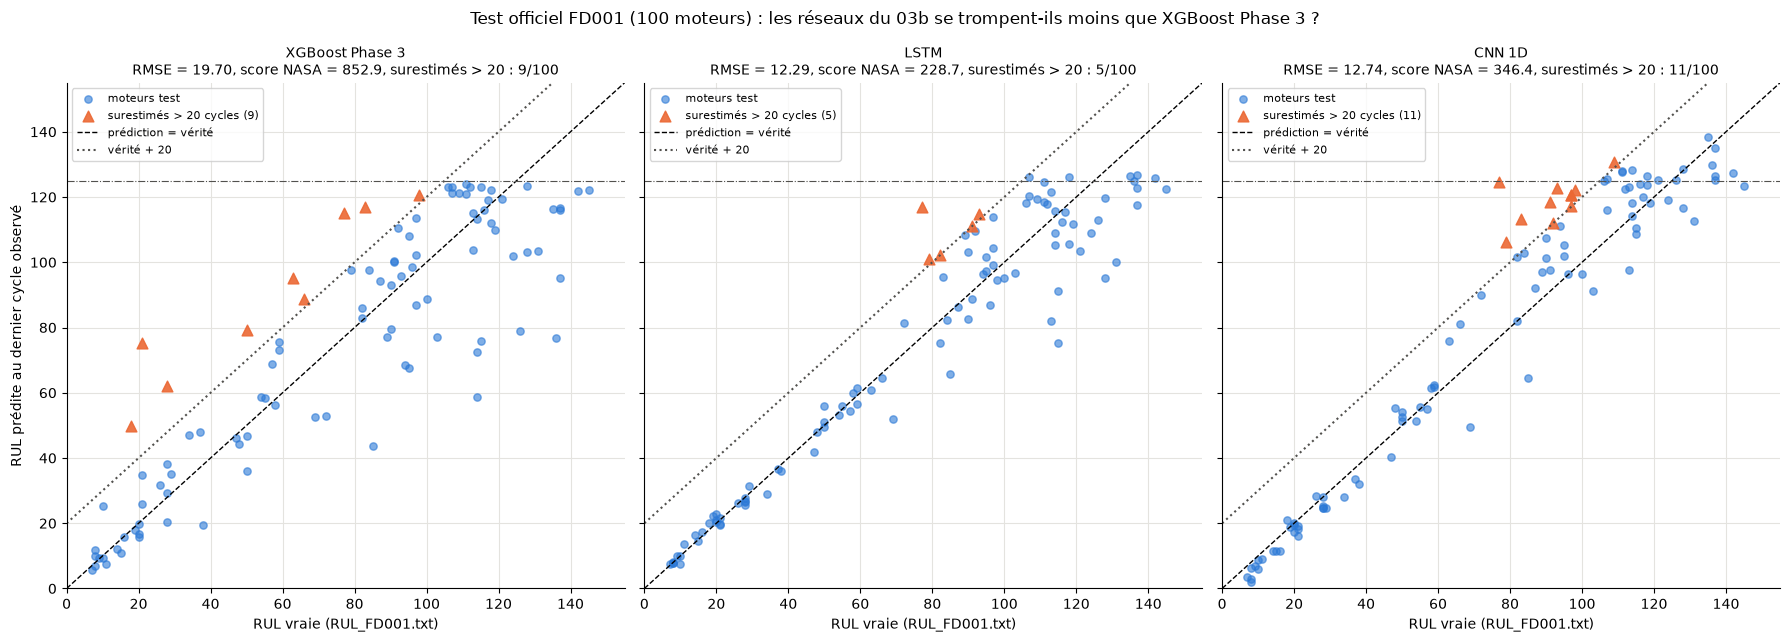

OK    Etape 4, figure 03b F.6 : RMSE test LSTM graine 42 (fichier) : cite 12.29, calcule 12.29
OK    Etape 4, figure 03b F.6 : RMSE test CNN 1D graine 42 (fichier) : cite 12.74, calcule 12.74


True

In [30]:
# --- Prédictions des réseaux du 03b au dernier cycle (relues), alignées sur les moteurs test (03b, F.1 et F.6) ---
predictions_dernier_cycle = pd.read_csv(os.path.join(DOSSIER_03B, "03b_predictions_test_fd001.csv"))
# alignement : memes moteurs, dans le meme ordre que y_test_vraie ; meme RUL vraie
assert np.array_equal(predictions_dernier_cycle["unit_number"].to_numpy(), moteurs_test_ordre)
assert np.array_equal(predictions_dernier_cycle["rul_vraie"].to_numpy(dtype=float), np.asarray(y_test_vraie, dtype=float))

predictions_figure = {}
predictions_figure["XGBoost Phase 3"] = resultats_test["XGBoost Phase 3"]["predictions"]  # section 4.2
predictions_figure["LSTM"] = predictions_dernier_cycle["lstm_graine42"].to_numpy()
predictions_figure["CNN 1D"] = predictions_dernier_cycle["cnn1d_graine42"].to_numpy()

limite = float(np.max(y_test_vraie)) + 10
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), sharex=True, sharey=True)
for ax, nom_modele in zip(axes, ["XGBoost Phase 3", "LSTM", "CNN 1D"]):
    predictions = predictions_figure[nom_modele]
    surestime = (predictions - y_test_vraie) > SEUIL_SURESTIMATION
    ax.scatter(y_test_vraie[~surestime], predictions[~surestime], color=COULEUR_1, alpha=0.6, s=28, label="moteurs test")
    ax.scatter(y_test_vraie[surestime], predictions[surestime], color=COULEUR_2, marker="^", s=60, alpha=0.9,
               label=f"surestimés > {SEUIL_SURESTIMATION} cycles ({int(surestime.sum())})")
    ax.plot([0, limite], [0, limite], linestyle="--", color="black", linewidth=1, label="prédiction = vérité")
    ax.plot([0, limite], [SEUIL_SURESTIMATION, limite + SEUIL_SURESTIMATION], linestyle=":", color=COULEUR_TEXTE,
            label=f"vérité + {SEUIL_SURESTIMATION}")
    ax.axhline(PLAFOND_RUL, color=COULEUR_TEXTE, linestyle="-.", linewidth=0.8)
    ax.set_title(f"{nom_modele}\nRMSE = {rmse(y_test_vraie, predictions):.2f}, score NASA = {score_nasa(y_test_vraie, predictions):.1f}, "
                 f"surestimés > 20 : {int(surestime.sum())}/100", fontsize=10)
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.legend(fontsize=8, loc="upper left")
for ax in axes:
    ax.set_xlabel("RUL vraie (RUL_FD001.txt)")
axes[0].set_ylabel("RUL prédite au dernier cycle observé")
fig.suptitle("Test officiel FD001 (100 moteurs) : les réseaux du 03b se trompent-ils moins que XGBoost Phase 3 ?")
plt.tight_layout()
plt.show()

# contrôle : les chiffres de la figure sont ceux des fichiers (03b, F.3) et de la section 4.2
verifier("Etape 4, figure 03b F.6 : RMSE test LSTM graine 42 (fichier)", 12.29, rmse(y_test_vraie, predictions_figure["LSTM"]))
verifier("Etape 4, figure 03b F.6 : RMSE test CNN 1D graine 42 (fichier)", 12.74, rmse(y_test_vraie, predictions_figure["CNN 1D"]))

### 4.7 Les versions retenues sur FD002, FD003 et FD004 (05, F.7 ; 03b, G.5)

*Notebook 05, section F.7, et notebook 03b, section G.5, déplacées avec leurs cellules.* Le choix fait sur FD001 (l'écart à l'état initial, réglages de base) est appliqué tel quel aux trois autres sous-jeux (c'est une limite : il n'est pas refait par sous-jeu). Chaque modèle retenu est entraîné sur tous les moteurs d'entraînement du sous-jeu, puis évalué **une seule fois** sur le dernier cycle observé de chaque moteur test. Ce sont des modèles « avant Optuna » (étape 5 et 6) : la v2 présente les modèles finaux dans `resultats/FD00X.ipynb`.

**D'où viennent les chiffres** : arbres, `sorties/resultats/05_arbres_resume.csv` (écrit par `scripts/generer_predictions_arbres.py`, réglages de base, versions de base et retenue) ; réseaux, `docs/resultats/03b/03b_deep_learning.csv` et `03b_cv_fd00X.csv` (exécution du 03b du 2026-11-04).

**Comment lire** (05, F.7) :
- `rmse_cv` : validation croisée 5 plis (mêmes plis que les arbres pour les réseaux aussi) ; `base` = version de base, `retenu` = version retenue ;
- `test_brute` : RMSE contre la vraie RUL de `RUL_FD00X.txt` ; `test_plafonnee` : RMSE contre cette RUL plafonnée à 125, ce que le modèle pouvait apprendre ;
- pour les arbres, la colonne `base` du test est le modèle final publié avant cette étude, recalculé à l'identique ; pour les réseaux, le test de la version de base n'est plus dans les fichiers (« - ») ;
- `surestimes_test` = moteurs surestimés de plus de 20 cycles ; `alertes_manquees_test` = vraie RUL ≤ 30 mais prédiction > 30.

In [31]:
# --- 05, F.7 : test officiel des versions retenues, FD001 à FD004 (arbres : fichier du script ; réseaux : 03b) ---
CHEMIN_RESUME_ARBRES = os.path.join("..", "sorties", "resultats", "05_arbres_resume.csv")
if not os.path.exists(CHEMIN_RESUME_ARBRES):
    raise FileNotFoundError(f"{CHEMIN_RESUME_ARBRES} absent : lancer, depuis la racine du depot, "
                            "python scripts/preparer_demo.py (ou python scripts/generer_predictions_arbres.py)")
resume_arbres = pd.read_csv(CHEMIN_RESUME_ARBRES)  # arbres : base et retenu
resultats_reseaux = resultats_03b  # reseaux : retenu (docs/resultats/03b/03b_deep_learning.csv, relu a l'etape 3)
candidats_reseaux = pd.read_csv(os.path.join(DOSSIER_03B, "03b_candidats_fd001.csv"))  # base des reseaux (FD001)
cv_reseaux_sous_jeux = {}  # sous-jeu -> validation croisee 5 plis des reseaux retenus
for sous_jeu in SOUS_JEUX:
    cv_reseaux_sous_jeux[sous_jeu] = pd.read_csv(os.path.join(DOSSIER_03B, f"03b_cv_{sous_jeu.lower()}.csv")).set_index("modele")

# les 6 modeles retenus au 05 : cle des fichiers -> nom affiche dans les tableaux
MODELES_RETENUS_05 = {}
MODELES_RETENUS_05["reference_naive"] = "Reference naive"
MODELES_RETENUS_05["random_forest"] = "Random Forest"
MODELES_RETENUS_05["lightgbm"] = "LightGBM"
MODELES_RETENUS_05["xgboost_phase3"] = "XGBoost"
MODELES_RETENUS_05["lstm"] = "LSTM"
MODELES_RETENUS_05["cnn1d"] = "CNN 1D"
CLES_ARBRES_05 = ["reference_naive", "random_forest", "xgboost_phase3", "lightgbm"]  # produits par le script des arbres
CLES_RESEAUX_05 = ["lstm", "cnn1d"]  # produits par le script des reseaux

lignes = []
for sous_jeu in SOUS_JEUX:
    for cle in CLES_ARBRES_05:
        lignes_modele = resume_arbres[(resume_arbres["sous_jeu"] == sous_jeu) & (resume_arbres["modele"] == cle)]
        base = lignes_modele[lignes_modele["jeu_features"] == "base"].iloc[0]  # 46 variables (ou equivalent par sous-jeu)
        retenu = lignes_modele[lignes_modele["retenu"]].iloc[0]  # la version choisie par la regle sur FD001
        ligne = {}
        ligne["sous_jeu"] = sous_jeu
        ligne["modele"] = MODELES_RETENUS_05[cle]
        ligne["version_retenue"] = retenu["jeu_features"]
        ligne["moteurs_test"] = int(retenu["nb_moteurs_test"])
        ligne["rmse_cv_base"] = base["rmse_cv_moyen"]
        ligne["rmse_cv_retenu"] = retenu["rmse_cv_moyen"]
        ligne["test_brute_base"] = base["rmse_test"]
        ligne["test_brute_retenu"] = retenu["rmse_test"]
        ligne["test_plafonnee_base"] = base["rmse_test_rul_plafonnee"]
        ligne["test_plafonnee_retenu"] = retenu["rmse_test_rul_plafonnee"]
        ligne["nasa_test_retenu"] = retenu["nasa_test"]
        ligne["surestimes_test"] = int(retenu["surestimes_test"])
        ligne["alertes_manquees_test"] = int(retenu["alertes_manquees_test"])
        lignes.append(ligne)
    for cle in CLES_RESEAUX_05:
        retenu = resultats_reseaux[(resultats_reseaux["sous_jeu"] == sous_jeu) & (resultats_reseaux["modele"] == cle)].iloc[0]
        ligne = {}
        ligne["sous_jeu"] = sous_jeu
        ligne["modele"] = MODELES_RETENUS_05[cle]
        ligne["version_retenue"] = candidats_03b["decisions"][cle]["configuration_retenue"]
        ligne["moteurs_test"] = int(retenu["nb_moteurs_test"])
        if sous_jeu == "FD001":  # la version de base des reseaux n'a ete evaluee en validation croisee que sur FD001
            ligne_base = candidats_reseaux[(candidats_reseaux["type_modele"] == cle) & (candidats_reseaux["candidat"] == "base")].iloc[0]
            ligne["rmse_cv_base"] = ligne_base["rmse_cv_moyen"]
        else:
            ligne["rmse_cv_base"] = np.nan
        ligne["rmse_cv_retenu"] = cv_reseaux_sous_jeux[sous_jeu].loc[cle, "rmse_cv_moyen"]
        ligne["test_brute_base"] = np.nan  # test de la version de base des reseaux : plus dans les fichiers
        ligne["test_brute_retenu"] = retenu["rmse_test"]
        ligne["test_plafonnee_base"] = np.nan
        ligne["test_plafonnee_retenu"] = retenu["rmse_test_rul_plafonnee"]
        ligne["nasa_test_retenu"] = retenu["nasa_test"]
        ligne["surestimes_test"] = int(retenu["surestimes_test"])
        ligne["alertes_manquees_test"] = int(retenu["alertes_manquees_test"])
        lignes.append(ligne)
tableau_test_sous_jeux = pd.DataFrame(lignes).set_index(["sous_jeu", "modele"])

# controle : FD001, les arbres du fichier sont ceux recalcules ici (sections 4.2 et 4.5)
verifier("Etape 4, 05 F.7 : test XGBoost base FD001 (fichier du script)", 19.70,
         tableau_test_sous_jeux.loc[("FD001", "XGBoost"), "test_brute_base"])
verifier("Etape 4, 05 F.7 : test XGBoost retenu FD001 (fichier du script)", 13.10,
         tableau_test_sous_jeux.loc[("FD001", "XGBoost"), "test_brute_retenu"])
tableau_test_sous_jeux.round(2).fillna("-")  # "-" : valeur absente des fichiers

OK    Etape 4, 05 F.7 : test XGBoost base FD001 (fichier du script) : cite 19.7, calcule 19.7
OK    Etape 4, 05 F.7 : test XGBoost retenu FD001 (fichier du script) : cite 13.1, calcule 13.1


version_retenue  moteurs_test rmse_cv_base  rmse_cv_retenu test_brute_base  test_brute_retenu test_plafonnee_base  test_plafonnee_retenu  nasa_test_retenu  surestimes_test  \
sous_jeu modele                                                                                                                                                                                          
FD001    Reference naive              base           100        41.69           41.69           43.07              43.07               41.94                  41.94          33629.23               41   
         Random Forest    ecart_initial_20           100        16.96           10.19           19.52              14.27               18.34                  13.03            301.89                3   
         XGBoost          ecart_initial_20           100        16.87            9.36            19.7              13.10               18.53                  11.88            237.00                2   
         LightGBM         ecart_initial_20           100        16.85            9.35           20.45              13.40               19.31                  12.12            283.61                3   
         LSTM                            A           100         13.7            8.94               -              12.29                   -                  11.37            228.67                5   
         CNN 1D                          A           100        16.96           10.05               -              12.74                   -                  12.38            346.40               11   
FD002    Reference naive              base           259        41.67           41.67           54.08              54.08               44.93                  44.93         153229.26              106   
         Random Forest    ecart_initial_20           259        16.68           11.67           27.49              24.11               15.51                  11.70           4573.11               13   
         XGBoost          ecart_initial_20           259        16.41           11.11           27.23              23.90               15.46                  11.47           4876.46               14   
         LightGBM         ecart_initial_20           259        16.46           11.01            27.3              23.77               15.47                  11.45           4573.84               15   
         LSTM                            A           259            -           10.55               -              22.57                   -                  11.05           3505.11               18   
         CNN 1D                          A           259            -           10.94               -              23.80                   -                  11.08           4386.59               12   
FD003    Reference naive              base           100        40.76           40.76           45.07              45.07                43.7                  43.70          57949.64               49   
         Random Forest    ecart_initial_20           100         15.3            9.42           18.35              12.72               16.77                  10.83            255.74                4   
         XGBoost          ecart_initial_20           100        14.82            9.21           18.09              12.24               16.66                  10.52            257.10                6   
         LightGBM         ecart_initial_20           100        15.13            8.95            18.2              12.17               16.71                  10.53            237.48                6   
         LSTM                            A           100            -            9.13               -              13.40                   -                  11.93            313.54               10   
         CNN 1D                          A           100            -            8.77               -              17.00                   -                  14.71            382.30        

**Figure par sous-jeu** (03b, G.5) : XGBoost Phase 3 (46 variables, recalculé à l'étape 2, section 2.2) contre les réseaux retenus du 03b (avec l'écart à l'état initial), sur les quatre sous-jeux. Quatre panneaux : RMSE de validation croisée (mêmes plis, moyenne des 5 plis), RMSE test contre la RUL brute (protocole officiel), RMSE test contre la RUL plafonnée (ce que les modèles pouvaient apprendre), score NASA par moteur test.

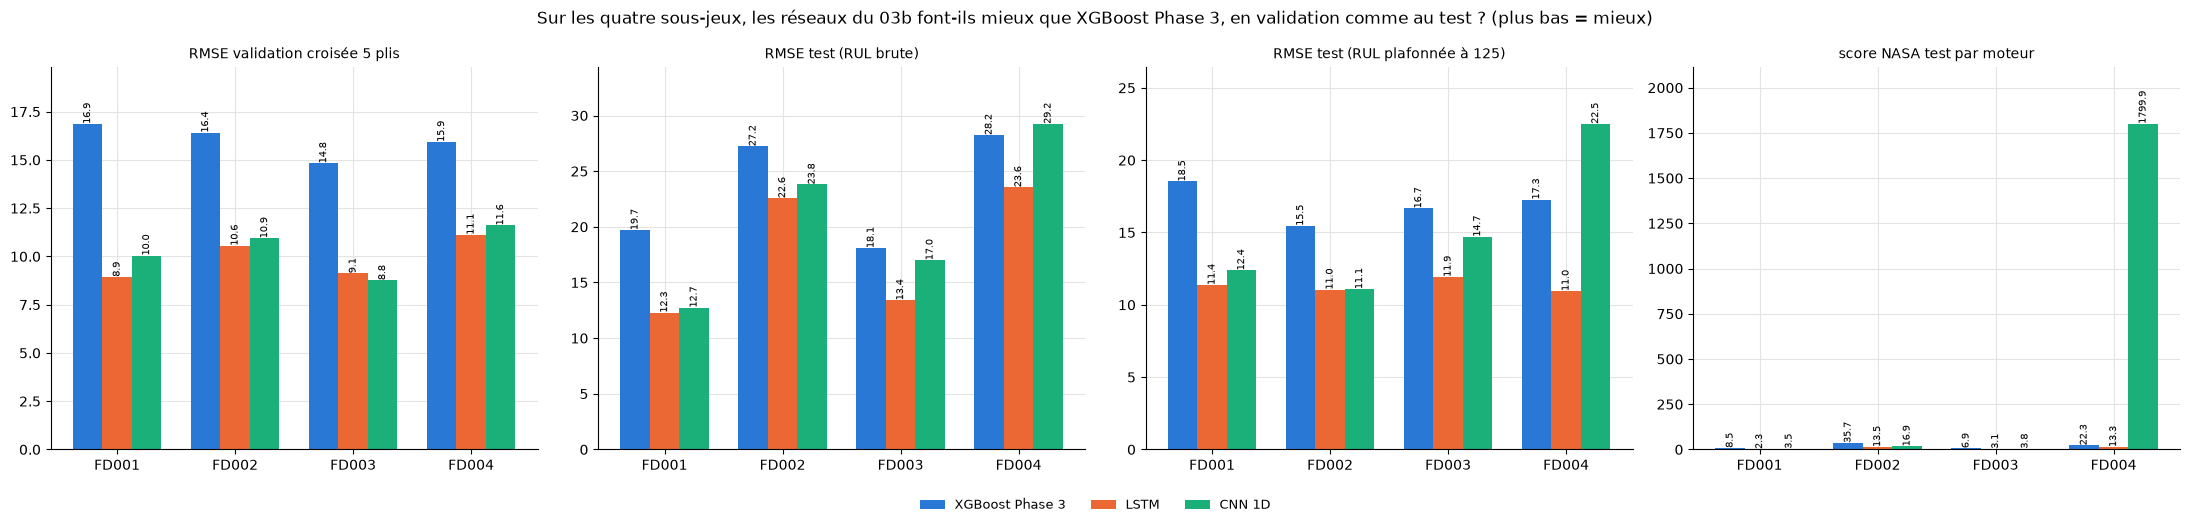

FD001 : plus petit RMSE test (RUL brute) = LSTM (12.29)
FD002 : plus petit RMSE test (RUL brute) = LSTM (22.57)
FD003 : plus petit RMSE test (RUL brute) = LSTM (13.40)
FD004 : plus petit RMSE test (RUL brute) = LSTM (23.55)


In [32]:
# --- 03b, G.5 : les quatre sous-jeux, XGBoost Phase 3 contre les réseaux du 03b ---
# tableau du test (03b, G.1) et de la validation (03b, G.3) : XGBoost Phase 3 de l'etape 2, reseaux relus
lignes_test = []
lignes_cv = []
for sous_jeu in SOUS_JEUX:
    ligne_xgb = resume[resume["sous_jeu"] == sous_jeu].iloc[0]  # etape 2, section 2.2 (recalcule ici)
    lignes_test.append({"sous_jeu": sous_jeu, "modele": "XGBoost Phase 3", "rmse_test": ligne_xgb["rmse_test"],
                        "rmse_test_rul_plafonnee": ligne_xgb["rmse_test_rul_plafonnee"],
                        "nasa_test_par_moteur": ligne_xgb["nasa_test_par_moteur"]})
    lignes_cv.append({"sous_jeu": sous_jeu, "modele": "XGBoost Phase 3", "rmse_cv_moyen": ligne_xgb["rmse_cv_moyen"]})
    for reseau, nom_reseau in [("lstm", "LSTM"), ("cnn1d", "CNN 1D")]:
        ligne_reseau = resultats_03b[(resultats_03b["sous_jeu"] == sous_jeu) & (resultats_03b["modele"] == reseau)].iloc[0]
        lignes_test.append({"sous_jeu": sous_jeu, "modele": nom_reseau, "rmse_test": ligne_reseau["rmse_test"],
                            "rmse_test_rul_plafonnee": ligne_reseau["rmse_test_rul_plafonnee"],
                            "nasa_test_par_moteur": ligne_reseau["nasa_test"] / ligne_reseau["nb_moteurs_test"]})
        lignes_cv.append({"sous_jeu": sous_jeu, "modele": nom_reseau,
                          "rmse_cv_moyen": cv_reseaux_sous_jeux[sous_jeu].loc[reseau, "rmse_cv_moyen"]})
tableau_sous_jeux = pd.DataFrame(lignes_test).set_index(["sous_jeu", "modele"])
tableau_cv_sous_jeux = pd.DataFrame(lignes_cv).set_index(["sous_jeu", "modele"])

sous_jeux_figure = ["FD001", "FD002", "FD003", "FD004"]
modeles_figure = ["XGBoost Phase 3", "LSTM", "CNN 1D"]
couleurs_modeles_figure = [COULEUR_1, COULEUR_2, COULEUR_3]
largeur_barre = 0.25
tableau_figure = tableau_sous_jeux.join(tableau_cv_sous_jeux[["rmse_cv_moyen"]], how="left")
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))
panneaux = [("rmse_cv_moyen", "RMSE validation croisée 5 plis"), ("rmse_test", "RMSE test (RUL brute)"),
            ("rmse_test_rul_plafonnee", "RMSE test (RUL plafonnée à 125)"), ("nasa_test_par_moteur", "score NASA test par moteur")]
for ax, (colonne, titre) in zip(axes, panneaux):
    for position_modele in range(len(modeles_figure)):
        nom_modele = modeles_figure[position_modele]
        for position_sous_jeu in range(len(sous_jeux_figure)):
            cle = (sous_jeux_figure[position_sous_jeu], nom_modele)
            if cle not in tableau_figure.index:
                continue
            valeur = tableau_figure.loc[cle, colonne]
            if pd.isna(valeur):
                continue
            x = position_sous_jeu + (position_modele - 1) * largeur_barre  # 3 barres centrees sur le sous-jeu
            etiquette = None
            if position_sous_jeu == 0:
                etiquette = nom_modele
            ax.bar(x, valeur, width=largeur_barre, color=couleurs_modeles_figure[position_modele], label=etiquette)
            ax.text(x, valeur, f"{valeur:.1f}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_xticks(np.arange(len(sous_jeux_figure)))
    ax.set_xticklabels(sous_jeux_figure)
    ax.set_title(titre, fontsize=10)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)  # un peu de place au-dessus des barres pour les valeurs
# une seule legende pour les quatre panneaux, sous les graphiques (elle ne cache aucune barre)
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="lower center", ncol=3, fontsize=9, frameon=False)
fig.suptitle("Sur les quatre sous-jeux, les réseaux du 03b font-ils mieux que XGBoost Phase 3, en validation comme au test ? (plus bas = mieux)")
plt.tight_layout(rect=(0, 0.06, 1, 1))  # on laisse une bande en bas pour la legende
plt.show()

# ce qu'on lit : le meilleur RMSE test (RUL brute) de chaque sous-jeu, construit a partir du tableau
for sous_jeu in sous_jeux_figure:
    meilleur_modele = modeles_figure[0]
    for nom_modele in modeles_figure:
        if tableau_figure.loc[(sous_jeu, nom_modele), "rmse_test"] < tableau_figure.loc[(sous_jeu, meilleur_modele), "rmse_test"]:
            meilleur_modele = nom_modele
    print(f"{sous_jeu} : plus petit RMSE test (RUL brute) = {meilleur_modele} "
          f"({tableau_figure.loc[(sous_jeu, meilleur_modele), 'rmse_test']:.2f})")

### 4.8 Lecture de l'étape 4

- **Idée retenue pour les 5 modèles qui apprennent.** RMSE de validation FD001 : Random Forest 16,96 → 10,19 ; XGBoost 16,87 → 9,36 ; LightGBM 16,85 → 9,35 ; LSTM 13,70 → 8,94. Les deux conditions de la règle passent pour chacun. La référence naïve garde la base.
- **La prudence ne se dégrade pas** : moins de lignes surestimées de plus de 20 cycles et moins d'alertes manquées hors-pli (tableau 4.3).
- **Test officiel FD001** : XGBoost 19,70 → 13,10 ; LightGBM 20,45 → 13,40 ; Random Forest 19,52 → 14,27 ; LSTM 13,86 → 12,29.
- **Fenêtre de 50 cycles (idée 2) non retenue** : pour le LSTM, la combinaison fenêtre 50 + écart ne bat pas l'écart seul ; pour le CNN 1D, la fenêtre de 50 n'est pas significative (tableau 4.4).
- **CNN 1D** : validation 16,96 → 10,05, test 12,74, comme `STATUS.md` (entrée du 2026-11-05) et `02_choix_du_modele`. Ces chiffres viennent de l'exécution du 03b du 2026-11-04 (`docs/resultats/03b/`). Un réentraînement du 03b, le 2026-11-05 (`docs/resultats/04h/03b_*`, relu par le 04h), donne pour le même CNN 1D 16,83 → 10,15 et 13,09 au test (cellule ci-dessous) : les réseaux ne sont pas reproductibles au bit près d'une exécution à l'autre. Le LSTM, lui, redonne les mêmes chiffres dans les deux exécutions. Quelle exécution fait foi pour la v2 reste à confirmer par l'équipe.
- **FD002 à FD004** (section 4.7) : la même version retenue, appliquée telle quelle, sans nouveau choix par sous-jeu.

In [33]:
verifier("Etape 4 apres : RMSE CV Random Forest 31 variables", 10.19, resultats_cv_31["Random Forest"]["rmse_moyen"])
verifier("Etape 4 apres : RMSE CV XGBoost 31 variables", 9.36, resultats_cv_31["XGBoost Phase 3"]["rmse_moyen"])
verifier("Etape 4 apres : RMSE CV LightGBM 31 variables", 9.35, resultats_cv_31["LightGBM"]["rmse_moyen"])
verifier("Etape 4 apres : RMSE CV LSTM avec ecart (fichier)", 8.94, rmse_cv_reseaux["lstm"][1])
nb_retenus = 0
for nom_modele in ["Random Forest", "XGBoost Phase 3", "LightGBM"]:
    if decisions_31[nom_modele]["jeu_selon_regle"] == "ecart_initial_20":
        nb_retenus = nb_retenus + 1
verifier("Etape 4 apres : arbres pour lesquels la regle retient l'ecart", 3, nb_retenus, decimales=0)
verifier("Etape 4 apres : la reference naive garde la base", 1, float(decisions_31["Reference naive"]["jeu_selon_regle"] == "base"), decimales=0)
verifier("Etape 4 apres : RMSE test XGBoost 31 variables", 13.10, resultats_test_31["XGBoost Phase 3"]["rmse"])
verifier("Etape 4 apres : RMSE test LightGBM 31 variables", 13.40, resultats_test_31["LightGBM"]["rmse"])
verifier("Etape 4 apres : RMSE test Random Forest 31 variables", 14.27, resultats_test_31["Random Forest"]["rmse"])
verifier("Etape 4 apres : RMSE test LSTM avec ecart (fichier)", 12.29, ligne_lstm_a["rmse_test"])
verifier("Etape 4 : LSTM fenetre 50 + ecart (AB) non retenu", 0, float(candidats_03b["decisions"]["lstm"]["comparaisons"]["AB"]["retenu"]), decimales=0)
verifier("Etape 4 : CNN 1D fenetre 50 (B) non retenu", 0, float(candidats_03b["decisions"]["cnn1d"]["comparaisons"]["B"]["retenu"]), decimales=0)
# chiffres de STATUS.md (2026-11-05) pour le CNN 1D, lus dans l'execution du 03b du 2026-11-04 (docs/resultats/03b/)
verifier("Etape 4 : CNN 1D, RMSE CV avec ecart (STATUS 2026-11-05)", 10.05, rmse_cv_reseaux["cnn1d"][1])
verifier("Etape 4 : CNN 1D, RMSE CV de base (STATUS 2026-11-05)", 16.96, rmse_cv_reseaux["cnn1d"][0])
ligne_cnn_a = resultats_03b[(resultats_03b["sous_jeu"] == "FD001") & (resultats_03b["modele"] == "cnn1d")].iloc[0]
verifier("Etape 4 : CNN 1D, RMSE test avec ecart (STATUS 2026-11-05)", 12.74, ligne_cnn_a["rmse_test"])

# l'autre execution du 03b (reentrainement du 2026-11-05, relu par le 04h) : affichee, pas utilisee ici
resultats_03b_reentraine = pd.read_csv(os.path.join(DOSSIER_04H, "03b_deep_learning.csv"))
with open(os.path.join(DOSSIER_04H, "03b_candidats_fd001.json"), encoding="utf-8") as fichier:
    candidats_03b_reentraine = json.load(fichier)
for reseau, nom_reseau in [("lstm", "LSTM"), ("cnn1d", "CNN 1D")]:
    ligne_reentraine = resultats_03b_reentraine[(resultats_03b_reentraine["sous_jeu"] == "FD001")
                                                & (resultats_03b_reentraine["modele"] == reseau)].iloc[0]
    gain_reentraine = candidats_03b_reentraine["decisions"][reseau]["comparaisons"]["A"]["gain_rmse"]
    print(f"{nom_reseau:7s}, reentrainement du 2026-11-05 (docs/resultats/04h/) : RMSE CV base "
          f"{ligne_reentraine['rmse_validation'] + gain_reentraine:.2f} -> avec ecart {ligne_reentraine['rmse_validation']:.2f}, "
          f"test {ligne_reentraine['rmse_test']:.2f} ; execution du 2026-11-04 (docs/resultats/03b/) : "
          f"{rmse_cv_reseaux[reseau][0]:.2f} -> {rmse_cv_reseaux[reseau][1]:.2f}, test "
          f"{resultats_03b[(resultats_03b['sous_jeu'] == 'FD001') & (resultats_03b['modele'] == reseau)].iloc[0]['rmse_test']:.2f}")

OK    Etape 4 apres : RMSE CV Random Forest 31 variables : cite 10.19, calcule 10.19
OK    Etape 4 apres : RMSE CV XGBoost 31 variables : cite 9.36, calcule 9.36
OK    Etape 4 apres : RMSE CV LightGBM 31 variables : cite 9.35, calcule 9.35
OK    Etape 4 apres : RMSE CV LSTM avec ecart (fichier) : cite 8.94, calcule 8.94
OK    Etape 4 apres : arbres pour lesquels la regle retient l'ecart : cite 3, calcule 3.0
OK    Etape 4 apres : la reference naive garde la base : cite 1, calcule 1.0
OK    Etape 4 apres : RMSE test XGBoost 31 variables : cite 13.1, calcule 13.1
OK    Etape 4 apres : RMSE test LightGBM 31 variables : cite 13.4, calcule 13.4
OK    Etape 4 apres : RMSE test Random Forest 31 variables : cite 14.27, calcule 14.27
OK    Etape 4 apres : RMSE test LSTM avec ecart (fichier) : cite 12.29, calcule 12.29
OK    Etape 4 : LSTM fenetre 50 + ecart (AB) non retenu : cite 0, calcule 0.0
OK    Etape 4 : CNN 1D fenetre 50 (B) non retenu : cite 0, calcule 0.0
OK    Etape 4 : CNN 1D, RMSE C

## Étape 5 : Optuna sur les arbres

- **Ce qui change** : la façon de choisir les hyperparamètres des arbres. **Avant** : réglages de la Phase 3 fixés à la main (200 arbres, profondeur 5, pas 0,05), seulement diagnostiqués par des courbes de validation. **Après** : réglages cherchés par Optuna sur les 31 variables (04f pour XGBoost, 04g pour LightGBM et Random Forest), confirmés sur des découpages neufs ; ce sont les `CONFIG_*_FINAL` de `src/config_modele.py`, utilisés par la démo.
- **Pourquoi** : le protocole (règle 11 d'`AGENTS.md`) exige une optimisation des hyperparamètres ; à la main, on n'explore qu'un ou deux réglages à la fois.
- **Notebooks d'origine** : [03_modelisation](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/03_modelisation.ipynb) (section 12 : courbes de validation), [04d_hyperparametres](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04d_hyperparametres.ipynb) (méthode, 46 variables), [04f_modele_final](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04f_modele_final.ipynb) (31 variables), [04g_comparaison_modeles](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04g_comparaison_modeles.ipynb). La recherche Optuna elle-même (règle, historique, importance des réglages, confirmation) est dans `02_choix_du_modele`.

### 5.1 Avant : le réglage à la main, diagnostiqué par des courbes de validation (46 variables)

*Section 12 du notebook 03, déplacée avec son code (sans enregistrer les figures dans `docs/figures/`).* On refait la validation croisée sur les **mêmes 5 plis** en ne changeant qu'un seul réglage : la profondeur maximale des arbres, de 1 (arbres très simples) à 10 (arbres très complexes). Tout le reste est identique (`n_estimators=200`, `learning_rate=0.05`, 46 features).

Lecture attendue : quand la complexité augmente, le RMSE train baisse toujours. Le RMSE validation baisse d'abord (on réduit le biais), puis stagne ou remonte (la variance prend le dessus). Le bon réglage est là où la validation est la plus basse ; l'écart entre les deux courbes mesure la variance.

max_depth= 1 : RMSE train= 16.71   RMSE val= 17.54 (ecart-type entre plis 1.13)   ecart=+0.83


max_depth= 2 : RMSE train= 15.17   RMSE val= 16.62 (ecart-type entre plis 1.24)   ecart=+1.45


max_depth= 3 : RMSE train= 14.13   RMSE val= 16.55 (ecart-type entre plis 1.22)   ecart=+2.42


max_depth= 4 : RMSE train= 12.69   RMSE val= 16.60 (ecart-type entre plis 1.30)   ecart=+3.91


max_depth= 5 : RMSE train= 10.94   RMSE val= 16.87 (ecart-type entre plis 1.25)   ecart=+5.93


max_depth= 6 : RMSE train=  8.82   RMSE val= 17.05 (ecart-type entre plis 1.31)   ecart=+8.23


max_depth= 7 : RMSE train=  6.79   RMSE val= 17.14 (ecart-type entre plis 1.28)   ecart=+10.34


max_depth= 8 : RMSE train=  4.76   RMSE val= 17.25 (ecart-type entre plis 1.24)   ecart=+12.48


max_depth=10 : RMSE train=  1.84   RMSE val= 17.32 (ecart-type entre plis 1.16)   ecart=+15.48

Plus bas RMSE val : max_depth=3 (16.55), contre 16.87 au reglage actuel (max_depth=5)


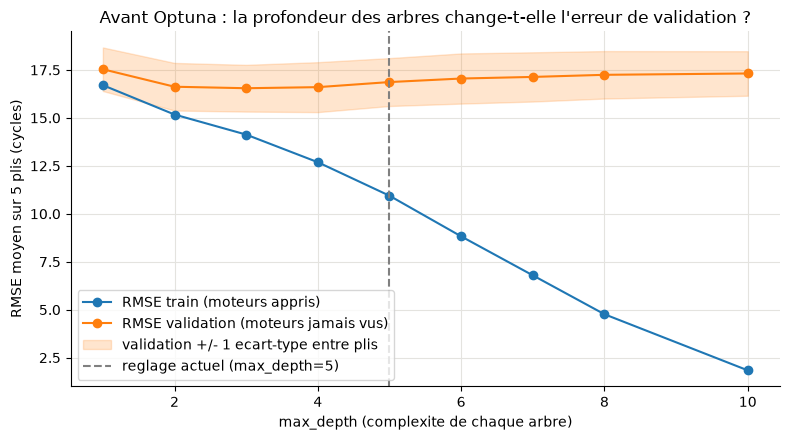

In [34]:
# 2) Courbe de validation sur max_depth : un seul reglage change, tout le reste est fixe
profondeurs = [1, 2, 3, 4, 5, 6, 7, 8, 10]  # 5 = reglage de la Phase 3
train_moy_par_profondeur = []  # RMSE train moyen sur les 5 plis, pour chaque profondeur
val_moy_par_profondeur = []    # RMSE validation moyen
val_std_par_profondeur = []    # ecart-type de la validation entre plis (= le bruit de la mesure)

for profondeur in profondeurs:  # une profondeur a la fois
    rmse_train_plis = []
    rmse_val_plis = []

    for idx_train, idx_val in plis:  # les 5 memes plis qu'en section 1.3
        modele = XGBRegressor(n_estimators=200, max_depth=profondeur, learning_rate=0.05, random_state=42, n_jobs=N_JOBS_ARBRES)
        modele.fit(X.iloc[idx_train], y.iloc[idx_train])

        pred_train = modele.predict(X.iloc[idx_train])  # erreur sur les moteurs appris
        pred_val = modele.predict(X.iloc[idx_val])      # erreur sur les moteurs jamais vus
        rmse_train_plis.append(np.sqrt(np.mean((y.iloc[idx_train].values - pred_train) ** 2)))
        rmse_val_plis.append(np.sqrt(np.mean((y.iloc[idx_val].values - pred_val) ** 2)))

    train_moy_par_profondeur.append(np.mean(rmse_train_plis))
    val_moy_par_profondeur.append(np.mean(rmse_val_plis))
    val_std_par_profondeur.append(np.std(rmse_val_plis))
    print(f"max_depth={profondeur:2d} : RMSE train={np.mean(rmse_train_plis):6.2f}   RMSE val={np.mean(rmse_val_plis):6.2f} "
          f"(ecart-type entre plis {np.std(rmse_val_plis):.2f})   ecart={np.mean(rmse_val_plis) - np.mean(rmse_train_plis):+.2f}")

# sanity check : le reglage actuel (max_depth=5) doit redonner les chiffres de la section 1.3 (memes plis, memes reglages)
indice_actuel = profondeurs.index(5)
assert abs(val_moy_par_profondeur[indice_actuel] - np.mean(rmse_par_fold)) < 0.05, "max_depth=5 ne redonne pas la section 1.3"

# meilleure profondeur en validation
indice_meilleur = int(np.argmin(val_moy_par_profondeur))
print(f"\nPlus bas RMSE val : max_depth={profondeurs[indice_meilleur]} ({val_moy_par_profondeur[indice_meilleur]:.2f}), "
      f"contre {val_moy_par_profondeur[indice_actuel]:.2f} au reglage actuel (max_depth=5)")

# visualisation : deux courbes + une bande d'incertitude (+/- 1 ecart-type entre plis) autour de la validation
val_bas = np.array(val_moy_par_profondeur) - np.array(val_std_par_profondeur)
val_haut = np.array(val_moy_par_profondeur) + np.array(val_std_par_profondeur)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(profondeurs, train_moy_par_profondeur, marker="o", label="RMSE train (moteurs appris)")
ax.plot(profondeurs, val_moy_par_profondeur, marker="o", label="RMSE validation (moteurs jamais vus)")
ax.fill_between(profondeurs, val_bas, val_haut, alpha=0.2, color="tab:orange", label="validation +/- 1 ecart-type entre plis")
ax.axvline(5, linestyle="--", color="grey", label="reglage actuel (max_depth=5)")

ax.set_xlabel("max_depth (complexite de chaque arbre)")
ax.set_ylabel("RMSE moyen sur 5 plis (cycles)")
ax.set_title("Avant Optuna : la profondeur des arbres change-t-elle l'erreur de validation ?")
ax.legend()

plt.tight_layout()
plt.show()  # plus de savefig : docs/figures/03_biais_variance_courbe_max_depth.png reste celui du notebook 03

XGBoost construit ses arbres l'un après l'autre, chacun corrigeant les erreurs des précédents. Avec `eval_set`, il mesure le RMSE train et validation **après chaque arbre ajouté** : un seul entraînement de 1000 arbres par pli donne donc toute la courbe de 1 à 1000 arbres. Réglages fixes : `max_depth=5`, `learning_rate=0.05`.

Apres 200 arbres : RMSE val moyen=16.87 (section 1.3 : 16.87)
  50 arbres : RMSE train= 14.26   RMSE val= 16.98   ecart=+2.72
 100 arbres : RMSE train= 12.59   RMSE val= 16.73   ecart=+4.14
 200 arbres : RMSE train= 10.94   RMSE val= 16.87   ecart=+5.93
 400 arbres : RMSE train=  8.83   RMSE val= 17.05   ecart=+8.22
 700 arbres : RMSE train=  6.79   RMSE val= 17.15   ecart=+10.36
1000 arbres : RMSE train=  5.42   RMSE val= 17.24   ecart=+11.82

Plus bas RMSE val : 90 arbres (16.72)


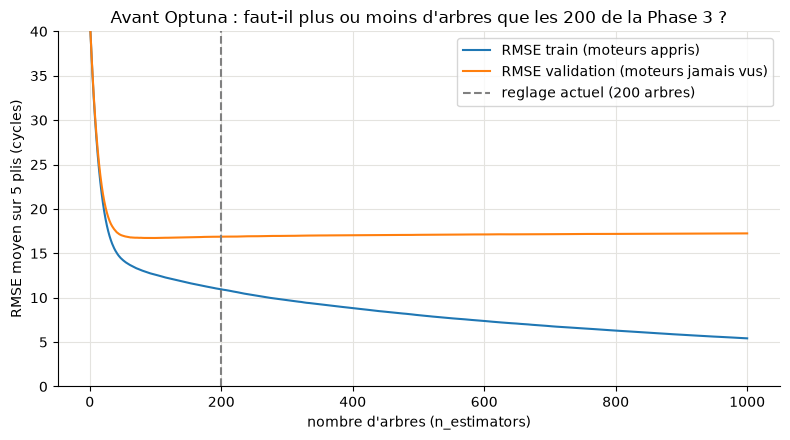

In [35]:
# 3) Courbe de validation sur n_estimators, en un seul entrainement de 1000 arbres par pli
NB_ARBRES_MAX = 1000
courbes_train = []  # une courbe (1000 valeurs de RMSE) par pli, cote train
courbes_val = []    # idem, cote validation

for idx_train, idx_val in plis:  # les 5 memes plis
    X_tr_pli, y_tr_pli = X.iloc[idx_train], y.iloc[idx_train]
    X_val_pli, y_val_pli = X.iloc[idx_val], y.iloc[idx_val]

    # eval_metric="rmse" : XGBoost calcule le RMSE sur chaque jeu de eval_set apres chaque arbre ajoute
    modele = XGBRegressor(n_estimators=NB_ARBRES_MAX, max_depth=5, learning_rate=0.05,
                          random_state=42, eval_metric="rmse", n_jobs=N_JOBS_ARBRES)
    modele.fit(X_tr_pli, y_tr_pli, eval_set=[(X_tr_pli, y_tr_pli), (X_val_pli, y_val_pli)], verbose=False)

    historique = modele.evals_result()  # validation_0 = 1er jeu de eval_set (train), validation_1 = 2e (val)
    courbes_train.append(historique["validation_0"]["rmse"])
    courbes_val.append(historique["validation_1"]["rmse"])

# moyenne des 5 plis, arbre par arbre (np.mean sur l'axe 0 = moyenne "verticale" des 5 courbes)
courbe_train_moy = np.mean(np.array(courbes_train), axis=0)
courbe_val_moy = np.mean(np.array(courbes_val), axis=0)

# sanity check : apres 200 arbres (reglage actuel), on doit retrouver le RMSE val de la section 1.3
print(f"Apres 200 arbres : RMSE val moyen={courbe_val_moy[199]:.2f} (section 1.3 : {np.mean(rmse_par_fold):.2f})")
assert abs(courbe_val_moy[199] - np.mean(rmse_par_fold)) < 0.05, "la courbe ne redonne pas la section 1.3"

for nb_arbres in [50, 100, 200, 400, 700, 1000]:  # quelques points representatifs de la courbe
    ecart = courbe_val_moy[nb_arbres - 1] - courbe_train_moy[nb_arbres - 1]
    print(f"{nb_arbres:4d} arbres : RMSE train={courbe_train_moy[nb_arbres - 1]:6.2f}   RMSE val={courbe_val_moy[nb_arbres - 1]:6.2f}   ecart={ecart:+.2f}")

nb_arbres_meilleur = int(np.argmin(courbe_val_moy)) + 1  # +1 car l'indice 0 correspond au 1er arbre
print(f"\nPlus bas RMSE val : {nb_arbres_meilleur} arbres ({courbe_val_moy[nb_arbres_meilleur - 1]:.2f})")

fig, ax = plt.subplots(figsize=(8, 4.5))
nombre_arbres = np.arange(1, NB_ARBRES_MAX + 1)  # 1, 2, ..., 1000 pour l'axe horizontal
ax.plot(nombre_arbres, courbe_train_moy, label="RMSE train (moteurs appris)")
ax.plot(nombre_arbres, courbe_val_moy, label="RMSE validation (moteurs jamais vus)")
ax.axvline(200, linestyle="--", color="grey", label="reglage actuel (200 arbres)")

ax.set_xlabel("nombre d'arbres (n_estimators)")
ax.set_ylabel("RMSE moyen sur 5 plis (cycles)")
ax.set_ylim(0, 40)  # on coupe le debut de courbe (RMSE tres eleve avec 1-2 arbres) pour lire la zone utile
ax.set_title("Avant Optuna : faut-il plus ou moins d'arbres que les 200 de la Phase 3 ?")
ax.legend()

plt.tight_layout()
plt.show()  # plus de savefig : docs/figures/03_biais_variance_courbe_n_estimators.png reste celui du notebook 03

**Lecture** (section 12 du 03) : quand on augmente la complexité, l'erreur train continue de baisser alors que l'erreur de validation remonte légèrement : le modèle de la Phase 3 est du côté « variance ». Mais le meilleur réglage à la main (`max_depth=3`, ou une centaine d'arbres) ne gagne que quelques dixièmes de cycle, moins que le bruit d'un pli à l'autre (écart-type d'environ 1,2). D'où la piste notée pour la Phase 4 : chercher plusieurs réglages **ensemble**, avec une règle de décision, ce que fait Optuna.

In [36]:
verifier("Etape 5 avant : meilleure profondeur a la main", 3, profondeurs[indice_meilleur], decimales=0)
gain_profondeur = val_moy_par_profondeur[indice_actuel] - val_moy_par_profondeur[indice_meilleur]
verifier("Etape 5 avant : gain de la meilleure profondeur < 0,5 cycle", 1, float(gain_profondeur < 0.5), decimales=0)
gain_arbres = courbe_val_moy[199] - courbe_val_moy[nb_arbres_meilleur - 1]
verifier("Etape 5 avant : gain du meilleur nombre d'arbres < 0,5 cycle", 1, float(gain_arbres < 0.5), decimales=0)
verifier("Etape 5 avant : ecart-type de la validation entre plis (max_depth=5)", 1.2, val_std_par_profondeur[indice_actuel], decimales=1)

OK    Etape 5 avant : meilleure profondeur a la main : cite 3, calcule 3.0
OK    Etape 5 avant : gain de la meilleure profondeur < 0,5 cycle : cite 1, calcule 1.0
OK    Etape 5 avant : gain du meilleur nombre d'arbres < 0,5 cycle : cite 1, calcule 1.0
OK    Etape 5 avant : ecart-type de la validation entre plis (max_depth=5) : cite 1.2, calcule 1.2


True

### 5.2 La recherche automatique : RMSE et score NASA de chaque essai (04d, 46 variables)

*Notebook 04d, déplacé avec son code.* Trois méthodes de recherche, **même budget** : 60 essais chacune (1 essai = 1 jeu d'hyperparamètres = 5 entraînements, un par pli), sur les mêmes plis par moteur que la Phase 3. La grille ne couvre que les 3 réglages de la Phase 3 (5 × 3 × 4 = 60 combinaisons) ; la recherche aléatoire et Optuna explorent 7 réglages dans les mêmes bornes. La question de la figure : quand un essai baisse le RMSE, baisse-t-il aussi le score NASA (l'équilibre demandé par le cahier des charges) ?

Écarts avec le 04d : XGBoost limité à 4 cœurs (avec `subsample` < 1, les arbres et donc les chiffres de la recherche aléatoire et d'Optuna peuvent légèrement différer de ceux du 04d) ; cache dans `sorties/evolution/cache_04d/` ; aucune figure écrite dans `docs/figures/`. Les deux autres figures du 04d (historique des recherches, importance des réglages) et la confirmation sur plis neufs sont dans `02_choix_du_modele`. Durée : de l'ordre de 10 à 20 minutes à la première exécution, puis relu dans le cache (`RELANCER_RECHERCHES_04D = False`).

In [37]:
import pickle  # cache des recherches (longues)

import optuna
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

RELANCER_RECHERCHES_04D = False  # True : relance les trois recherches meme si le cache existe
REGLAGES_ACTUELS = {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.05}  # Phase 3, jamais cherches
N_ESSAIS = 60  # budget identique pour les trois methodes (60 jeux d'hyperparametres, x5 plis)


def evaluer_reglage(params, plis_a_utiliser):
    """
    Evalue un jeu d'hyperparametres XGBoost par validation croisee sur les plis donnes (46 variables).

    Parameters
    ----------
    params : dict
        Hyperparametres passes a XGBRegressor (random_state=42 et n_jobs=4 sont ajoutes ici).
    plis_a_utiliser : list de (idx_train, idx_val)
        Les plis par moteur a utiliser (jamais un decoupage aleatoire ligne par ligne).

    Returns
    -------
    dict
        Listes par pli : "rmse", "nasa_moyen" (score NASA moyen par prediction),
        "surestimes_20" (% de lignes surestimees de plus de 20 cycles).
    """
    rmse_plis = []
    nasa_plis = []
    surest_plis = []

    for idx_train, idx_val in plis_a_utiliser:  # un pli a la fois
        modele = XGBRegressor(random_state=GRAINE, n_jobs=N_JOBS_ARBRES, **params)  # modele neuf a chaque pli
        modele.fit(X.iloc[idx_train], y.iloc[idx_train])
        y_val = y.iloc[idx_val].values
        y_pred = modele.predict(X.iloc[idx_val])

        rmse_plis.append(np.sqrt(mean_squared_error(y_val, y_pred)))
        nasa_plis.append(score_nasa(y_val, y_pred) / len(y_val))  # moyenne par prediction
        surest_plis.append(100.0 * np.sum(y_pred - y_val > 20) / len(y_val))  # en %

    return {"rmse": rmse_plis, "nasa_moyen": nasa_plis, "surestimes_20": surest_plis}


ref = evaluer_reglage(REGLAGES_ACTUELS, plis)
print(f"Reglages actuels : RMSE val = {np.mean(ref['rmse']):.2f} (ecart-type entre plis {np.std(ref['rmse']):.2f}), "
      f"score NASA moyen/prediction = {np.mean(ref['nasa_moyen']):.2f}, surestimes > 20 cycles = {np.mean(ref['surestimes_20']):.1f} %")
# sanity check : on doit retrouver le RMSE de validation de la section 1.3
assert abs(np.mean(ref["rmse"]) - rmse_cv_phase3) < 1e-6, "ne redonne pas la section 1.3"

# --- Grille (GridSearchCV) : 3 hyperparametres, 5 x 3 x 4 = 60 combinaisons ---
grille = {
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.02, 0.05, 0.1],
    "n_estimators": [100, 200, 300, 400],
}
nb_combinaisons = 1
for nom_hp in grille:  # produit du nombre de valeurs de chaque hyperparametre
    nb_combinaisons = nb_combinaisons * len(grille[nom_hp])
assert nb_combinaisons == N_ESSAIS, f"la grille a {nb_combinaisons} combinaisons, pas {N_ESSAIS}"

# --- Distributions (RandomizedSearchCV) : memes bornes que celles utilisees par Optuna plus bas ---
# randint(a, b) tire dans [a, b-1] ; uniform(loc, scale) tire dans [loc, loc+scale] ; loguniform(a, b) dans [a, b]
distributions = {
    "max_depth": randint(2, 9),               # 2 a 8
    "learning_rate": loguniform(0.01, 0.3),
    "n_estimators": randint(50, 601),         # 50 a 600
    "subsample": uniform(0.5, 0.5),           # 0.5 a 1.0
    "colsample_bytree": uniform(0.3, 0.7),    # 0.3 a 1.0
    "min_child_weight": loguniform(1, 30),
    "reg_lambda": loguniform(0.1, 30),
}


def surestimes_20_pourcent(y_true, y_pred):
    """
    Pourcentage de lignes dont la RUL est surestimee de plus de 20 cycles.

    Parameters
    ----------
    y_true : array-like
        Les vraies RUL.
    y_pred : array-like
        Les RUL predites.

    Returns
    -------
    float
        Pourcentage entre 0 et 100.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return 100.0 * np.sum(y_pred - y_true > 20) / len(y_true)


def nasa_moyen(y_true, y_pred):
    """
    Score NASA moyen par prediction (somme divisee par le nombre de lignes).

    Parameters
    ----------
    y_true : array-like
        Les vraies RUL.
    y_pred : array-like
        Les RUL predites.

    Returns
    -------
    float
        Penalite moyenne par prediction.
    """
    return score_nasa(y_true, y_pred) / len(y_true)


def rmse_scorer(y_true, y_pred):
    """
    RMSE pour le scorer de scikit-learn (fonction nommee plutot qu'une lambda, comme le reste du projet).

    Parameters
    ----------
    y_true : array-like
        Les vraies RUL.
    y_pred : array-like
        Les RUL predites.

    Returns
    -------
    float
        Le RMSE.
    """
    return np.sqrt(mean_squared_error(y_true, y_pred))


# scikit-learn MAXIMISE un score : pour une erreur, greater_is_better=False renvoie l'oppose (valeurs negatives)
scoring = {
    "rmse": make_scorer(rmse_scorer, greater_is_better=False),
    "nasa_moyen": make_scorer(nasa_moyen, greater_is_better=False),
    "surestimes_20": make_scorer(surestimes_20_pourcent, greater_is_better=False),
}
print(f"Grille : {nb_combinaisons} combinaisons. Random search et Optuna : {N_ESSAIS} essais sur {len(distributions)} hyperparametres.")

Reglages actuels : RMSE val = 16.87 (ecart-type entre plis 1.25), score NASA moyen/prediction = 7.25, surestimes > 20 cycles = 11.6 %
Grille : 60 combinaisons. Random search et Optuna : 60 essais sur 7 hyperparametres.


In [38]:
DOSSIER_CACHE = os.path.join(DOSSIER_EVOLUTION, "cache_04d")  # resultats des recherches (longues)
os.makedirs(DOSSIER_CACHE, exist_ok=True)


def charger_ou_calculer(nom, fonction):
    """
    Renvoie le resultat mis en cache s'il existe (et si RELANCER_RECHERCHES_04D est faux), sinon le calcule.

    Parameters
    ----------
    nom : str
        Nom du fichier de cache (sans extension).
    fonction : callable
        Fonction sans argument qui calcule le resultat (une recherche, longue).

    Returns
    -------
    object
        Le resultat (ici : un tableau pandas des essais et la duree en secondes).
    """
    chemin = os.path.join(DOSSIER_CACHE, nom + ".pkl")
    if os.path.exists(chemin) and not RELANCER_RECHERCHES_04D:  # deja calcule lors d'une execution precedente
        with open(chemin, "rb") as f:
            return pickle.load(f)
    resultat = fonction()  # calcul long
    with open(chemin, "wb") as f:
        pickle.dump(resultat, f)
    return resultat


def resultats_sklearn_vers_tableau(recherche, nom_methode):
    """
    Transforme recherche.cv_results_ (GridSearchCV ou RandomizedSearchCV) en tableau, une ligne par essai.

    Parameters
    ----------
    recherche : GridSearchCV ou RandomizedSearchCV
        Une recherche deja entrainee (multi-metriques, scoring negatif).
    nom_methode : str
        Nom ecrit dans la colonne "methode".

    Returns
    -------
    pandas.DataFrame
        Colonnes : methode, essai, params, rmse, rmse_std, nasa_moyen, surestimes_20.
    """
    res = recherche.cv_results_
    lignes = []
    for i in range(len(res["params"])):  # un essai a la fois
        lignes.append({
            "methode": nom_methode,
            "essai": i + 1,
            "params": res["params"][i],
            "rmse": -res["mean_test_rmse"][i],  # on remet le signe : le scorer renvoyait l'oppose
            "rmse_std": res["std_test_rmse"][i],
            "nasa_moyen": -res["mean_test_nasa_moyen"][i],
            "surestimes_20": -res["mean_test_surestimes_20"][i],
        })
    return pd.DataFrame(lignes)


def lancer_grid():
    """
    Lance GridSearchCV sur la grille (60 combinaisons x 5 plis par moteur passes en cv=).

    Returns
    -------
    (pandas.DataFrame, float)
        Le tableau des essais et la duree totale en secondes.
    """
    debut_grid = time.time()
    recherche = GridSearchCV(
        XGBRegressor(random_state=GRAINE, n_jobs=N_JOBS_ARBRES),
        param_grid=grille,
        cv=plis,              # LES plis par moteur (liste de (idx_train, idx_val)), jamais cv=5
        scoring=scoring,
        refit=False,          # on ne reentraine pas : seul le classement des essais nous interesse
        n_jobs=1,             # XGBoost parallelise deja en interne
    )
    recherche.fit(X, y)
    return resultats_sklearn_vers_tableau(recherche, "Grid"), time.time() - debut_grid


def lancer_random():
    """
    Lance RandomizedSearchCV : 60 tirages au hasard dans les distributions, memes plis par moteur.

    Returns
    -------
    (pandas.DataFrame, float)
        Le tableau des essais et la duree totale en secondes.
    """
    debut_random = time.time()
    recherche = RandomizedSearchCV(
        XGBRegressor(random_state=GRAINE, n_jobs=N_JOBS_ARBRES),
        param_distributions=distributions,
        n_iter=N_ESSAIS,       # meme budget que la grille
        cv=plis,               # memes plis par moteur
        scoring=scoring,
        refit=False,
        random_state=GRAINE,   # tirages reproductibles
        n_jobs=1,
    )
    recherche.fit(X, y)
    return resultats_sklearn_vers_tableau(recherche, "Random"), time.time() - debut_random


optuna.logging.set_verbosity(optuna.logging.WARNING)  # pas un message par essai


def objectif(essai):
    """
    Fonction objectif d'Optuna : propose des hyperparametres, renvoie le RMSE moyen de validation.

    Le score NASA moyen et le % de surestimations sont gardes en attributs de l'essai (pas optimises).

    Parameters
    ----------
    essai : optuna.trial.Trial
        L'essai en cours ; c'est lui qui propose les valeurs via suggest_*.

    Returns
    -------
    float
        RMSE moyen sur les 5 plis par moteur (a minimiser).
    """
    params = {
        "max_depth": essai.suggest_int("max_depth", 2, 8),
        "learning_rate": essai.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": essai.suggest_int("n_estimators", 50, 600),
        "subsample": essai.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": essai.suggest_float("colsample_bytree", 0.3, 1.0),
        "min_child_weight": essai.suggest_float("min_child_weight", 1, 30, log=True),
        "reg_lambda": essai.suggest_float("reg_lambda", 0.1, 30, log=True),
    }
    resultat = evaluer_reglage(params, plis)  # memes plis par moteur, meme fonction que pour la reference
    essai.set_user_attr("rmse_std", float(np.std(resultat["rmse"])))
    essai.set_user_attr("nasa_moyen", float(np.mean(resultat["nasa_moyen"])))
    essai.set_user_attr("surestimes_20", float(np.mean(resultat["surestimes_20"])))
    return float(np.mean(resultat["rmse"]))


def lancer_optuna():
    """
    Lance l'etude Optuna (TPE, graine 42, 60 essais).

    Returns
    -------
    (pandas.DataFrame, float)
        Le tableau des essais et la duree totale en secondes.
    """
    debut_optuna = time.time()
    etude = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=GRAINE))
    etude.optimize(objectif, n_trials=N_ESSAIS)

    lignes = []
    for t in etude.trials:  # un essai a la fois, dans l'ordre
        lignes.append({
            "methode": "Optuna",
            "essai": t.number + 1,
            "params": dict(t.params),
            "rmse": t.value,
            "rmse_std": t.user_attrs["rmse_std"],
            "nasa_moyen": t.user_attrs["nasa_moyen"],
            "surestimes_20": t.user_attrs["surestimes_20"],
        })
    return pd.DataFrame(lignes), time.time() - debut_optuna


essais_grid, duree_grid = charger_ou_calculer("grid", lancer_grid)
print(f"GridSearchCV       : {len(essais_grid)} essais en {duree_grid / 60:.1f} min")
essais_random, duree_random = charger_ou_calculer("random", lancer_random)
print(f"RandomizedSearchCV : {len(essais_random)} essais en {duree_random / 60:.1f} min")
essais_optuna, duree_optuna = charger_ou_calculer("optuna", lancer_optuna)
print(f"Optuna             : {len(essais_optuna)} essais en {duree_optuna / 60:.1f} min")

GridSearchCV       : 60 essais en 2.4 min
RandomizedSearchCV : 60 essais en 3.8 min
Optuna             : 60 essais en 2.7 min


Grid    : meilleur RMSE de validation 16.522 (gain +0.345 sur les plis de recherche, donc optimiste)
Random  : meilleur RMSE de validation 16.529 (gain +0.339 sur les plis de recherche, donc optimiste)
Optuna  : meilleur RMSE de validation 16.495 (gain +0.372 sur les plis de recherche, donc optimiste)


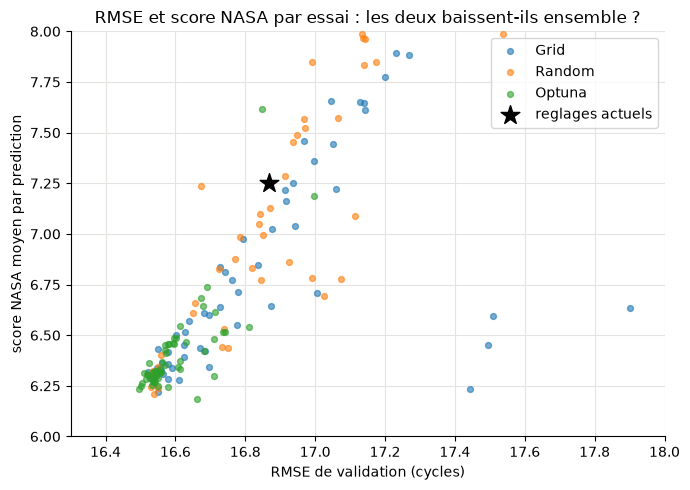

Correlation RMSE / score NASA moyen sur les 180 essais : 0.85


In [39]:
tous_les_essais = pd.concat([essais_grid, essais_random, essais_optuna], ignore_index=True)  # 180 essais
ref_rmse = float(np.mean(ref["rmse"]))
ref_nasa = float(np.mean(ref["nasa_moyen"]))

# une ligne par methode (la comparaison complete des methodes et le choix du candidat sont dans 02_choix_du_modele)
for methode in ["Grid", "Random", "Optuna"]:
    sous_tableau = tous_les_essais[tous_les_essais["methode"] == methode]
    meilleur = sous_tableau.sort_values("rmse").iloc[0]  # essai au RMSE le plus bas
    print(f"{methode:7s} : meilleur RMSE de validation {meilleur['rmse']:.3f} (gain {ref_rmse - meilleur['rmse']:+.3f} "
          f"sur les plis de recherche, donc optimiste)")

COULEURS_METHODES = {"Grid": "tab:blue", "Random": "tab:orange", "Optuna": "tab:green"}

# --- Figure 3 du 04d : RMSE contre score NASA moyen, un point par essai ---
fig, ax = plt.subplots(figsize=(7, 5))
for methode in ["Grid", "Random", "Optuna"]:
    sous_tableau = tous_les_essais[tous_les_essais["methode"] == methode]
    ax.scatter(sous_tableau["rmse"], sous_tableau["nasa_moyen"], s=18, alpha=0.6, label=methode, color=COULEURS_METHODES[methode])
ax.scatter([ref_rmse], [ref_nasa], marker="*", s=200, color="black", label="reglages actuels", zorder=5)
ax.set_xlim(16.3, 18.0)
ax.set_ylim(6.0, 8.0)
ax.set_xlabel("RMSE de validation (cycles)")
ax.set_ylabel("score NASA moyen par prediction")
ax.set_title("RMSE et score NASA par essai : les deux baissent-ils ensemble ?")
ax.legend()
plt.tight_layout()
plt.show()  # plus de savefig : docs/figures/04d_rmse_vs_score_nasa.png reste celui du notebook 04d

correlation_rmse_nasa = np.corrcoef(tous_les_essais["rmse"], tous_les_essais["nasa_moyen"])[0, 1]
print(f"Correlation RMSE / score NASA moyen sur les {len(tous_les_essais)} essais : {correlation_rmse_nasa:.2f}")

**Lecture** : sur les 46 variables, aucune méthode ne gagne plus de quelques dixièmes de cycle sur les plis de recherche, et RMSE et score NASA baissent ensemble (corrélation positive) : optimiser le RMSE ne dégrade pas la prudence. Le 04d a conclu de **ne pas changer** les réglages de la Phase 3 (gain non confirmé sur des plis neufs, `02_choix_du_modele`). Ce qui a changé ensuite, ce sont les variables (étape 4) : la recherche a été refaite sur les 31 variables (04f, 04g), et c'est elle qui donne les réglages finaux.

In [40]:
verifier("Etape 5 : RMSE et score NASA correles positivement (r > 0)", 1, float(correlation_rmse_nasa > 0), decimales=0)
meilleur_gain_46 = ref_rmse - tous_les_essais["rmse"].min()
verifier("Etape 5 : meilleur gain sur 46 variables < 0,5 cycle (plis de recherche)", 1, float(meilleur_gain_46 < 0.5), decimales=0)

OK    Etape 5 : RMSE et score NASA correles positivement (r > 0) : cite 1, calcule 1.0
OK    Etape 5 : meilleur gain sur 46 variables < 0,5 cycle (plis de recherche) : cite 1, calcule 1.0


True

### 5.3 Après : les réglages finaux sur les 31 variables (04f), contre la Phase 3

*Notebook 04f, cellules « évaluation finale » et « figures », déplacées.* Deux modèles, chacun avec ses variables et ses réglages : **46 variables, réglages de la Phase 3** contre **31 variables, réglages finaux** (`CONFIG_XGBOOST_FINAL`, recopiés du 04f dans `src/config_modele.py` : la recherche Optuna n'est pas relancée ici, elle est dans `02_choix_du_modele`). Pour chacun : métriques de régression du 04a (prédictions hors-pli des mêmes 5 plis, puis test), et lecture « alerte » pour N = 15, 30 et 50 cycles avec un seuil choisi sur la validation (rappel minimal 0,99).

Écarts avec le 04f : les variables viennent de `src/features.py` (`preparer_train`) au lieu d'être recodées, les métriques de `metriques_regression` (`src/evaluation.py`) ; le XGBoost final tourne sur **1 cœur**, comme le script de la démo. **Écart connu, selon la machine** : `src/config_modele.py` et `STATUS.md` publient 12,73 au test pour ce modèle sur 1 cœur (machine de Matisse) ; sur la machine qui a généré cette version du notebook (Mac arm64, xgboost 3.4.1), on obtient 12,78 avec 1 cœur comme avec 4 cœurs. Avec `subsample` < 1, le résultat de XGBoost peut donc dépendre de l'environnement (machine ou version des bibliothèques, non départagés : `requirements.txt` ne fixe pas les versions), pas seulement du nombre de cœurs. Le contrôle de 5.4 accepte l'une ou l'autre valeur et dit laquelle est obtenue ; le chiffre publié n'est pas retouché. On affiche le chiffre recalculé ; le chiffre publié n'est pas retouché. La fonction `choisir_seuil` du 04f est gardée telle quelle : à précision égale, elle préfère le seuil le plus sévère, alors que `choisir_seuil_alerte` de `src/` préfère le plus grand rappel ; ce n'est donc pas le même code.

In [41]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_curve, precision_score, roc_auc_score

RAPPEL_MIN = 0.99
HORIZONS = [15, 30, 50]
REGLAGES_PHASE3 = {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.05, "random_state": GRAINE,
                   "n_jobs": N_JOBS_ARBRES}  # 4 coeurs : memes arbres (subsample = 1)
REGLAGES_FINAUX = copy.deepcopy(CONFIG_XGBOOST_FINAL["hyperparametres"])  # Optuna du 04f, sans relancer la recherche
REGLAGES_FINAUX["n_jobs"] = 1  # 1 coeur IMPOSE : avec subsample < 1, le nombre de coeurs change les arbres


def choisir_seuil(y_vrai, score, rappel_min):
    """
    Parmi les seuils qui atteignent le rappel minimal, celui qui maximise la precision
    (a precision egale, le plus severe). Alerte si score >= seuil.

    Parameters
    ----------
    y_vrai : array-like de 0/1
        Etiquettes vraies de la validation (jamais du test).
    score : array-like
        Score continu : plus il est haut, plus le moteur est urgent.
    rappel_min : float
        Rappel minimal exige.

    Returns
    -------
    float
        Le seuil retenu.
    """
    precisions, rappels, seuils = precision_recall_curve(y_vrai, score)
    meilleur_seuil = None
    meilleure_precision = -1.0
    for i in range(len(seuils)):  # un candidat de seuil a la fois
        if rappels[i] >= rappel_min:
            if precisions[i] > meilleure_precision or (precisions[i] == meilleure_precision and seuils[i] > meilleur_seuil):
                meilleure_precision = precisions[i]
                meilleur_seuil = seuils[i]
    return meilleur_seuil


def metriques_04a(y_true, y_pred):
    """
    Metriques de regression gardees au notebook 04a, calculees par `metriques_regression` (src/evaluation.py).

    Parameters
    ----------
    y_true : array-like
        Les vraies RUL.
    y_pred : array-like
        Les RUL predites.

    Returns
    -------
    dict
        RMSE, MAE, R2, MedAE, MaxErr, Biais, NASA_moy (score NASA moyen par prediction) et Sur20_%
        (% de predictions surestimees de plus de 20 cycles) : les colonnes du tableau du 04f.
    """
    toutes = metriques_regression(y_true, y_pred, seuil_surestimation=SEUIL_SURESTIMATION)
    resultat = {}
    resultat["RMSE"] = toutes["rmse"]
    resultat["MAE"] = toutes["mae"]
    resultat["R2"] = toutes["r2"]
    resultat["MedAE"] = toutes["erreur_absolue_mediane"]
    resultat["MaxErr"] = toutes["erreur_max"]
    resultat["Biais"] = toutes["biais"]
    resultat["NASA_moy"] = toutes["nasa_moyen"]
    resultat["Sur20_%"] = toutes["surestimes_pct"]
    return resultat


y_test = np.asarray(y_test_vraie, dtype=float)  # vraie RUL du test (RUL_FD001.txt), nom du 04f
modeles = {
    "46 features (Phase 3)": (X, X_test_dernier, REGLAGES_PHASE3),
    "31 features (final)": (X31, contexte_test_31["X_test_dernier"], REGLAGES_FINAUX),
}
regression = []
alertes = []
predictions_04f = {}  # nom -> (predictions hors-pli, predictions test)

for nom, (feat_train, feat_test, params) in modeles.items():
    pred_val = np.zeros(len(y))  # predictions hors-pli sur la validation
    for idx_train, idx_val in plis:
        modele = XGBRegressor(**params)
        modele.fit(feat_train.iloc[idx_train], y.iloc[idx_train])
        pred_val[idx_val] = modele.predict(feat_train.iloc[idx_val])
    modele = XGBRegressor(**params)
    modele.fit(feat_train, y)  # entraine sur les 100 moteurs du train
    pred_test = np.clip(modele.predict(feat_test), 0, None)  # RUL negative sans sens physique
    predictions_04f[nom] = (pred_val, pred_test)

    ligne_val = {"modele": nom, "jeu": "validation"}
    ligne_val.update(metriques_04a(y.values, pred_val))
    regression.append(ligne_val)
    ligne_test = {"modele": nom, "jeu": "test (100 moteurs)"}
    ligne_test.update(metriques_04a(y_test, pred_test))
    regression.append(ligne_test)

    for n in HORIZONS:
        seuil_cycles = -choisir_seuil((y.values <= n).astype(int), -pred_val, RAPPEL_MIN)  # alerte si RUL predite <= seuil
        etiquettes_val = (y.values <= n).astype(int)
        alerte_val = (pred_val <= seuil_cycles).astype(int)
        tn_v, fp_v, fn_v, tp_v = confusion_matrix(etiquettes_val, alerte_val, labels=[0, 1]).ravel()
        etiquettes_test = (y_test <= n).astype(int)
        alerte_test = (pred_test <= seuil_cycles).astype(int)
        tn, fp, fn, tp = confusion_matrix(etiquettes_test, alerte_test, labels=[0, 1]).ravel()
        alertes.append({
            "modele": nom, "N": n, "alerte si RUL predite <=": round(float(seuil_cycles), 1),
            "AUC (val)": roc_auc_score(etiquettes_val, -pred_val), "precision (val)": tp_v / (tp_v + fp_v),
            "fausses alertes (val)": int(fp_v),
            "en danger (test)": int(etiquettes_test.sum()), "detectes": int(tp), "rates": int(fn), "fausses alertes (test)": int(fp),
            "accuracy (test)": accuracy_score(etiquettes_test, alerte_test),
            "precision (test)": precision_score(etiquettes_test, alerte_test, zero_division=0),
            "F1 (test)": f1_score(etiquettes_test, alerte_test, zero_division=0),
        })

print("RECAP 1 - erreur de prediction (metriques du notebook 04a)")
display(pd.DataFrame(regression).round(3))
textes_nasa = []
for ligne in regression:
    if ligne["jeu"].startswith("test"):
        textes_nasa.append(f"{ligne['modele']} = {ligne['NASA_moy'] * 100:.1f}")
print("Score NASA en somme sur le test (comparable aux articles) : " + ", ".join(textes_nasa))
print("\nRECAP 2 - alerte (rappel minimal 0,99, seuil choisi sur la validation)")
display(pd.DataFrame(alertes).round(3))

RECAP 1 - erreur de prediction (metriques du notebook 04a)


,modele,jeu,RMSE,MAE,R2,MedAE,MaxErr,Biais,NASA_moy,Sur20_%
0,46 features (Phase 3),validation,16.935,11.521,0.835,6.560,72.837,-0.164,7.218,11.555
1,46 features (Phase 3),test (100 moteurs),19.700,14.359,0.775,11.079,59.084,-0.901,8.529,9.000
2,31 features (final),validation,9.140,6.123,0.952,3.720,53.310,-0.176,1.452,3.378
3,31 features (final),test (100 moteurs),12.780,9.370,0.905,6.654,38.590,-1.409,2.325,2.000


Score NASA en somme sur le test (comparable aux articles) : 46 features (Phase 3) = 852.9, 31 features (final) = 232.5

RECAP 2 - alerte (rappel minimal 0,99, seuil choisi sur la validation)


,modele,N,alerte si RUL predite <=,AUC (val),precision (val),fausses alertes (val),en danger (test),detectes,rates,fausses alertes (test),accuracy (test),precision (test),F1 (test)
0,46 features (Phase 3),15,28.3,0.995,0.600,1055,10,10,0,8,0.92,0.556,0.714
1,46 features (Phase 3),30,65.0,0.988,0.523,2794,25,24,1,14,0.85,0.632,0.762
2,46 features (Phase 3),50,93.8,0.976,0.545,4220,33,33,0,25,0.75,0.569,0.725
3,31 features (final),15,20.2,0.998,0.776,457,10,10,0,4,0.96,0.714,0.833
4,31 features (final),30,37.1,0.998,0.837,599,25,25,0,2,0.98,0.926,0.962
5,31 features (final),50,60.8,0.997,0.849,901,33,33,0,6,0.94,0.846,0.917


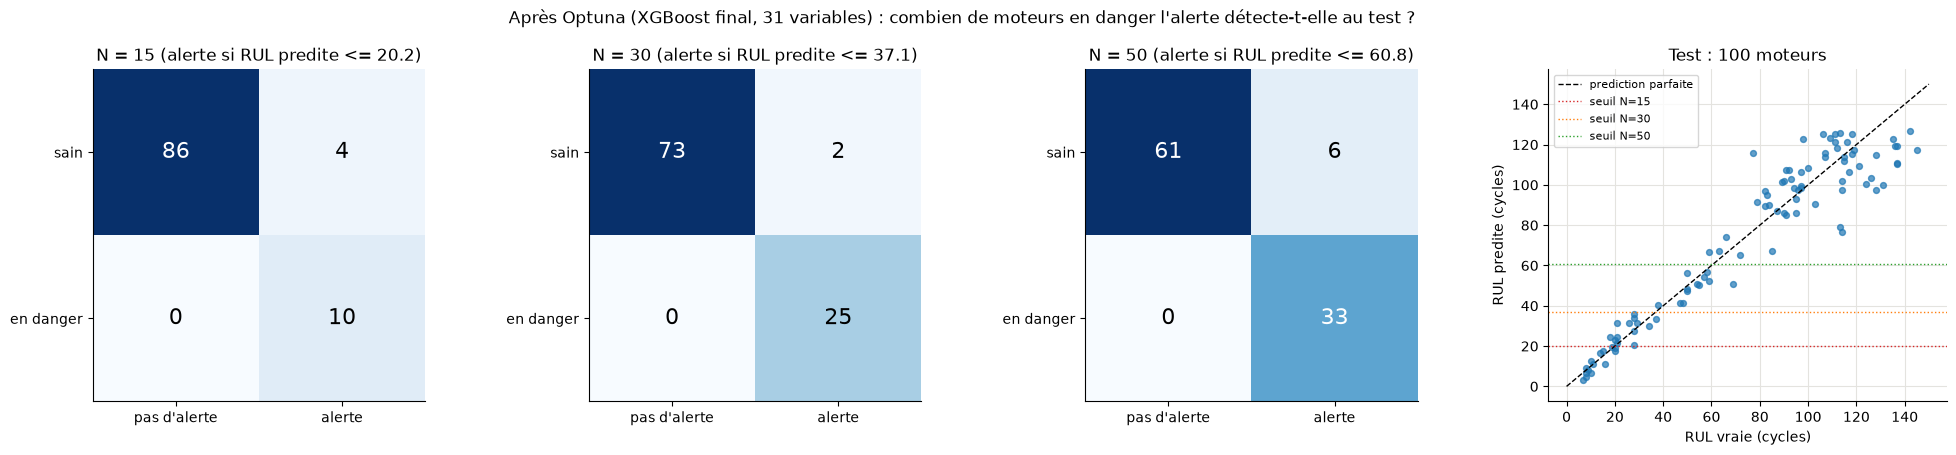

In [42]:
# --- Figure du 04f : modele final (31 features), test lu une seule fois (predictions de la cellule precedente) ---
pred_val, pred_test = predictions_04f["31 features (final)"]
seuils = {}  # N -> seuil d'alerte en cycles de RUL predite, choisi sur la validation
for n in HORIZONS:
    seuils[n] = -choisir_seuil((y.values <= n).astype(int), -pred_val, RAPPEL_MIN)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, n in zip(axes[:3], HORIZONS):
    vrai = (y_test <= n).astype(int)
    alerte = (pred_test <= seuils[n]).astype(int)
    matrice = confusion_matrix(vrai, alerte, labels=[0, 1])
    ax.imshow(matrice, cmap="Blues")
    ax.grid(False)  # pas de quadrillage sur une matrice de confusion (il couperait les cases)
    for i in range(2):
        for j in range(2):
            couleur_texte = "black"
            if matrice[i, j] > matrice.max() / 2:
                couleur_texte = "white"
            ax.text(j, i, matrice[i, j], ha="center", va="center", fontsize=16, color=couleur_texte)
    ax.set_xticks([0, 1], ["pas d'alerte", "alerte"])
    ax.set_yticks([0, 1], ["sain", "en danger"])
    ax.set_title(f"N = {n} (alerte si RUL predite <= {seuils[n]:.1f})")

ax = axes[3]
ax.scatter(y_test, pred_test, s=18, alpha=0.7)
ax.plot([0, 150], [0, 150], "k--", linewidth=1, label="prediction parfaite")
for n, couleur in zip(HORIZONS, ["tab:red", "tab:orange", "tab:green"]):
    ax.axhline(seuils[n], color=couleur, linewidth=1, linestyle=":", label=f"seuil N={n}")
ax.set_xlabel("RUL vraie (cycles)")
ax.set_ylabel("RUL predite (cycles)")
ax.set_title("Test : 100 moteurs")
ax.legend(fontsize=8)
fig.suptitle("Après Optuna (XGBoost final, 31 variables) : combien de moteurs en danger l'alerte détecte-t-elle au test ?")
plt.tight_layout()
plt.show()

**Les trois modèles à arbres finaux.** Leur validation croisée n'avait pas été enregistrée avec ces réglages : elle est recalculée ici (fonction `valider_un_jeu` du script des arbres, mêmes 5 plis), avec la configuration que la démo utilise (`configuration_version_retenue` du script : réglages finaux, XGBoost sur 1 cœur). Attention : la recherche Optuna a été faite **sur ces mêmes plis** (graine 42) ; leur validation est donc un peu optimiste (la confirmation sur plis neufs est dans `02_choix_du_modele`). « Avant » = mêmes 31 variables, réglages de base (section 4.3).

In [43]:
resultats_cv_finaux = {}    # nom -> validation croisee, reglages finaux
resultats_test_finaux = {}  # nom -> test officiel, reglages finaux
modeles_finaux_arbres = {}  # nom -> modele final entraine sur les 100 moteurs (reutilise par la figure du 04g, 5.3 bis)
for nom_modele in ["Random Forest", "XGBoost Phase 3", "LightGBM"]:
    cle = CLES_ARBRES[nom_modele]
    config_finale = script_arbres.configuration_version_retenue(cle, "ecart_initial_20", n_jobs=N_JOBS_ARBRES)
    if config_finale["famille"] == "random_forest":
        config_finale["hyperparametres"]["n_jobs"] = N_JOBS_ARBRES  # tous les coeurs dans src/ : memes arbres avec 4
    resultats_cv_finaux[nom_modele], _, _ = script_arbres.valider_un_jeu(contexte_train_31, config_finale, plis)
    modele_final_arbre = construire_fabrique_depuis_config(config_finale)()
    modele_final_arbre.fit(X31, y)
    modeles_finaux_arbres[nom_modele] = modele_final_arbre
    resultats_test_finaux[nom_modele] = evaluer_sur_test(modele_final_arbre, contexte_test_31["X_test_dernier"], y_test_vraie,
                                                         plafond=PLAFOND_RUL, seuil_surestimation=SEUIL_SURESTIMATION,
                                                         seuil_alerte=SEUIL_ALERTE)

NOMS_ARBRES_FINAUX = {"Random Forest": "Random Forest", "XGBoost Phase 3": "XGBoost", "LightGBM": "LightGBM"}
lignes = []
for nom_modele in resultats_cv_finaux:
    ligne = {}
    ligne["modele (31 variables)"] = NOMS_ARBRES_FINAUX[nom_modele]
    ligne["rmse_cv_avant"] = resultats_cv_31[nom_modele]["rmse_moyen"]
    ligne["rmse_cv_apres"] = resultats_cv_finaux[nom_modele]["rmse_moyen"]
    ligne["rmse_test_avant"] = resultats_test_31[nom_modele]["rmse"]
    ligne["rmse_test_apres"] = resultats_test_finaux[nom_modele]["rmse"]
    ligne["nasa_test_avant"] = resultats_test_31[nom_modele]["score_nasa"]
    ligne["nasa_test_apres"] = resultats_test_finaux[nom_modele]["score_nasa"]
    ligne["surestimes_test_apres"] = resultats_test_finaux[nom_modele]["nb_surestimes"]
    lignes.append(ligne)
tableau_finaux = pd.DataFrame(lignes).set_index("modele (31 variables)")
display(tableau_finaux.round(2))

# meme modele que la cellule du 04f (memes reglages, 1 coeur) : memes predictions test
assert np.allclose(resultats_test_finaux["XGBoost Phase 3"]["predictions"], predictions_04f["31 features (final)"][1])

ajouter_marche("5", "XGBoost final (31 variables, reglages Optuna)", resultats_cv_finaux["XGBoost Phase 3"]["rmse_moyen"],
               "5 plis, graine 42 (plis de la recherche : optimiste)", resultats_test_finaux["XGBoost Phase 3"]["rmse"],
               "recalcule ici (reglages de src/config_modele.py)")

,rmse_cv_avant,rmse_cv_apres,rmse_test_avant,rmse_test_apres,nasa_test_avant,nasa_test_apres,surestimes_test_apres
modele (31 variables),,,,,,,
Random Forest,10.19,9.95,14.27,13.14,301.89,243.30,3
XGBoost,9.36,9.12,13.10,12.78,237.00,232.52,2
LightGBM,9.35,9.06,13.40,12.76,283.61,234.63,3


### 5.3 bis — La RUL prédite cycle après cycle par les 3 arbres finaux, sur 4 moteurs test (04g)

*Notebook 04g, cellule 3, déplacée* (le texte de `02_choix_du_modele` la situait à tort dans `resultats/`, qui ne trace que le moteur 42). Les modèles sont les trois arbres finaux de la cellule précédente (réglages `CONFIG_*_FINAL` de `src/config_modele.py`, ceux de la démo), au lieu des modèles recodés dans le 04g. Lissage et écart à l'état initial sont causaux : la prédiction au cycle t n'utilise que les cycles ≤ t.

**Comment lire** : 4 moteurs à l'historique long (≥ 150 cycles), choisis pour leur RUL finale la plus proche de 10, 30, 60 et 100 cycles (choix sur la vérité, pas sur les prédictions). En noir la vraie RUL, en pointillé gris la vraie RUL plafonnée à 125 (la cible apprise), en couleur les 3 modèles ; sous la ligne rouge (30 cycles), le modèle déclencherait une alerte. Le titre donne l'écart final de chaque modèle (positif = surestimation).

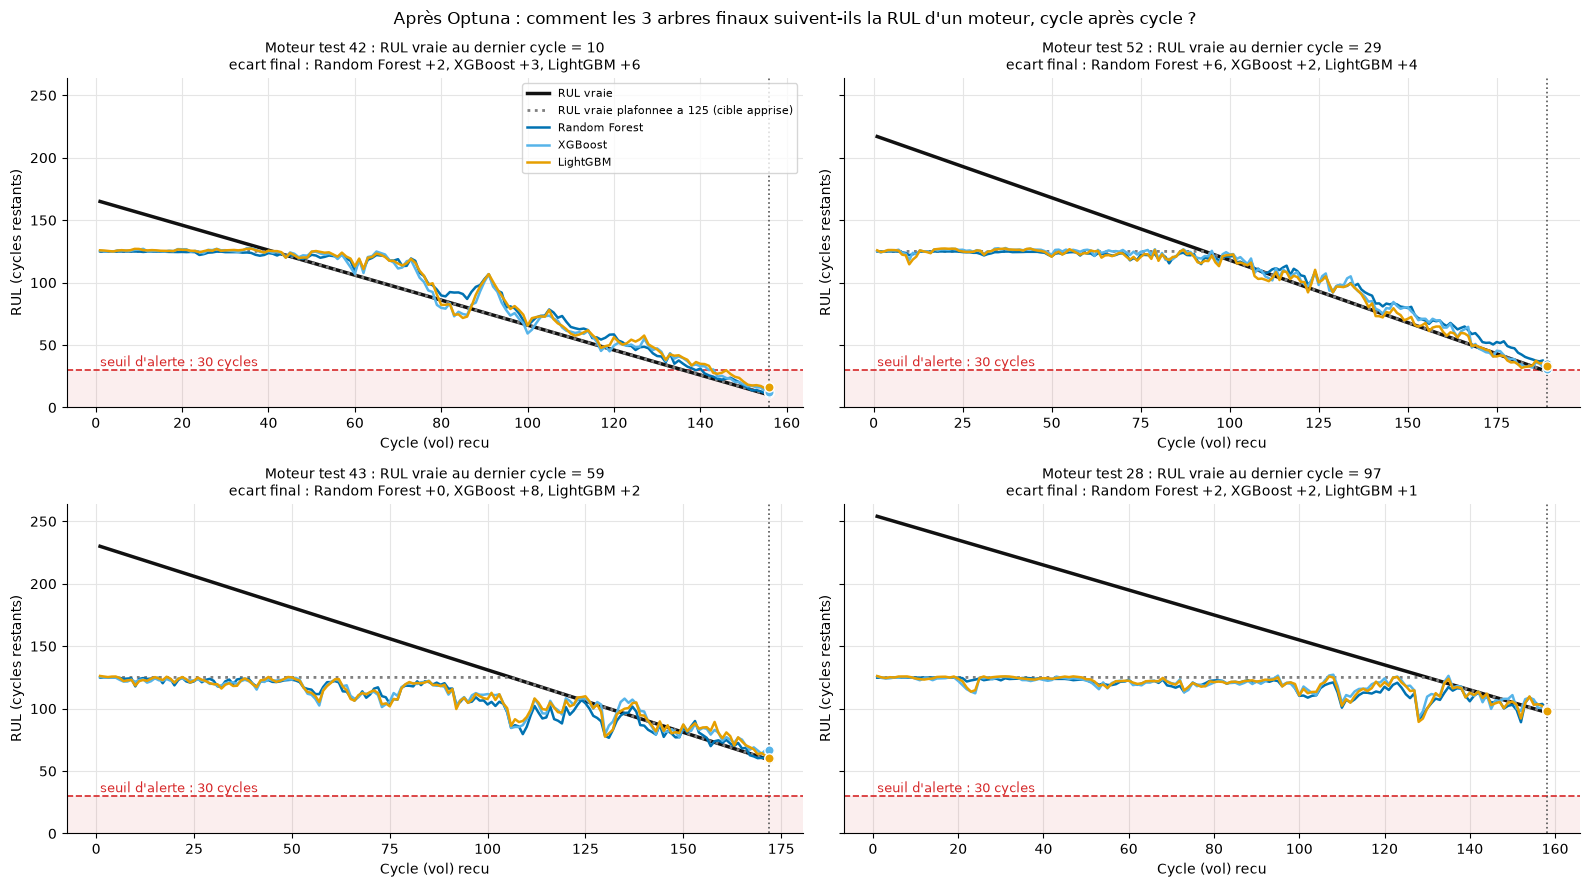

In [44]:
# --- Graphique : RUL predite cycle apres cycle par les 3 modeles finaux, sur 4 moteurs du test (04g, cellule 3) ---
# Lissage et ecart a l'etat initial sont causaux : la prediction au cycle t n'utilise que les cycles <= t.
SEUIL_ALERTE_FIGURE = 30
COULEURS_04G = {"XGBoost Phase 3": "#56B4E9", "LightGBM": "#E69F00", "Random Forest": "#0072B2"}  # memes couleurs que l'app

test_31 = contexte_test_31["test"]  # tous les cycles de chaque moteur test, features deja calculees (src/features.py)
X_test_complet = test_31[X31.columns]  # memes 31 variables, meme ordre que l'entrainement
fin = test_31.groupby("unit_number")["time_cycles"].transform("max")
rul_finale = pd.Series(np.asarray(y_test_vraie, dtype=float), index=moteurs_test_ordre)  # RUL vraie au dernier cycle, par moteur

# prediction a chaque cycle de chaque moteur test, ramenee a 0 si negative (une boucle par modele)
pred_cycles = {}
for nom_modele in modeles_finaux_arbres:
    pred_cycles[nom_modele] = np.clip(modeles_finaux_arbres[nom_modele].predict(X_test_complet), 0, None)

# 4 moteurs a l'historique long (>= 150 cycles), RUL finale la plus proche de 10, 30, 60 et 100 cycles
longueurs = test_31.groupby("unit_number")["time_cycles"].max()
candidats = rul_finale[longueurs.loc[rul_finale.index].to_numpy() >= 150]
moteurs_figure = []
for cible in [10, 30, 60, 100]:
    restants = candidats.drop(moteurs_figure)
    moteurs_figure.append(int((restants - cible).abs().idxmin()))

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)
rul_vraie_max = 0.0  # meme echelle verticale pour les 4 moteurs
for moteur in moteurs_figure:
    masque = (test_31["unit_number"] == moteur).values
    rul_vraie_max = max(rul_vraie_max, float(test_31.loc[masque, "RUL_vraie"].max()))
for ax, moteur in zip(axes.flat, moteurs_figure):
    masque = (test_31["unit_number"] == moteur).values
    cycles = test_31.loc[masque, "time_cycles"].values
    rul_vraie = test_31.loc[masque, "RUL_vraie"].values
    ax.axhspan(0, SEUIL_ALERTE_FIGURE, color="#D62728", alpha=0.08, linewidth=0)
    ax.axhline(SEUIL_ALERTE_FIGURE, color="#D62728", linestyle="--", linewidth=1.2)
    ax.text(cycles[0], SEUIL_ALERTE_FIGURE + 3, f"seuil d'alerte : {SEUIL_ALERTE_FIGURE} cycles", color="#D62728", fontsize=9)
    ax.plot(cycles, rul_vraie, color="#111111", linewidth=2.5, label="RUL vraie")
    ax.plot(cycles, np.minimum(rul_vraie, PLAFOND_RUL), color="#7F7F7F", linewidth=2, linestyle=":",
            label=f"RUL vraie plafonnee a {PLAFOND_RUL} (cible apprise)")
    textes_erreurs = []  # ecart final de chaque modele, pour le titre
    for nom_modele in pred_cycles:
        pred = pred_cycles[nom_modele]
        ax.plot(cycles, pred[masque], color=COULEURS_04G[nom_modele], linewidth=1.8, label=NOMS_ARBRES_FINAUX[nom_modele])
        ax.scatter(cycles[-1], pred[masque][-1], color=COULEURS_04G[nom_modele], s=45, edgecolors="white", zorder=3)
        textes_erreurs.append(f"{NOMS_ARBRES_FINAUX[nom_modele]} {pred[masque][-1] - rul_vraie[-1]:+.0f}")
    ax.axvline(cycles[-1], color="#555555", linestyle=":", linewidth=1.2)
    ax.set_title(f"Moteur test {moteur} : RUL vraie au dernier cycle = {rul_vraie[-1]:.0f}\necart final : "
                 + ", ".join(textes_erreurs), fontsize=10)
    ax.set_xlabel("Cycle (vol) recu")
    ax.set_ylabel("RUL (cycles restants)")
    ax.set_ylim(0, rul_vraie_max + 10)  # meme echelle, RUL vraie entiere
    ax.grid(color="#E5E5E5")
axes.flat[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Après Optuna : comment les 3 arbres finaux suivent-ils la RUL d'un moteur, cycle après cycle ?")
plt.tight_layout()
plt.show()

# controle : au dernier cycle, la prediction est celle du test officiel de la cellule precedente
for nom_modele in pred_cycles:
    derniers = test_31.groupby("unit_number")["time_cycles"].idxmax().sort_index().values
    assert np.allclose(pred_cycles[nom_modele][test_31.index.get_indexer(derniers)],
                       resultats_test_finaux[nom_modele]["predictions"])

### 5.4 Lecture de l'étape 5

- **Test officiel FD001** (31 variables, réglages de base → réglages finaux) : XGBoost 13,10 → 12,78 (12,73 sur la machine de Matisse, voir ci-dessous) ; LightGBM 13,40 → 12,76 ; Random Forest 14,27 → 13,14. Le gain est réel mais petit, du même ordre que le gain en validation (sur des plis qui ont servi à la recherche, donc optimiste).
- **Phase 3 → modèle final** : sur le test, le RMSE passe de 19,70 à 12,78 (ou 12,73), l'essentiel venant de l'étape 4 (19,70 → 13,10).
- **XGBoost final : 12,78 ou 12,73 selon l'environnement** : 12,73 publié (`src/config_modele.py`, `STATUS.md` du 2026-11-05, machine de Matisse), 12,78 sur la machine qui a généré cette version du notebook. Le contrôle ci-dessous dit laquelle des deux valeurs est obtenue à cette exécution ; l'écart de 0,05 cycle reste à trancher par l'équipe (versions des bibliothèques non fixées).

In [45]:
# XGBoost final : 12,73 (machine de Matisse) ou 12,78 (machine de generation de cette version) selon l'environnement
rmse_xgb_final = round(float(resultats_test_finaux["XGBoost Phase 3"]["rmse"]), 2)
print(f"XGBoost final, test FD001 a cette execution : {rmse_xgb_final:.2f} (valeurs connues : 12.73 ou 12.78)")
verifier("Etape 5 apres : RMSE test XGBoost final, 12,73 ou 12,78 selon la machine (1 = oui)", 1,
         float(rmse_xgb_final in [12.73, 12.78]), decimales=0)
verifier("Etape 5 apres : RMSE test XGBoost final publie (src/config_modele.py, autre machine)",
         CONFIG_XGBOOST_FINAL["metriques_test"]["rmse"], resultats_test_finaux["XGBoost Phase 3"]["rmse"], ecart_attendu=True)
verifier("Etape 5 apres : score NASA test XGBoost final publie (src/config_modele.py, autre machine)",
         CONFIG_XGBOOST_FINAL["metriques_test"]["score_nasa"], resultats_test_finaux["XGBoost Phase 3"]["score_nasa"],
         decimales=1, ecart_attendu=True)
verifier("Etape 5 apres : RMSE test LightGBM final", 12.76, resultats_test_finaux["LightGBM"]["rmse"])
verifier("Etape 5 apres : RMSE test Random Forest final", 13.14, resultats_test_finaux["Random Forest"]["rmse"])
verifier("Etape 5 : RMSE test 46 features (Phase 3), cellule du 04f", 19.70, regression[1]["RMSE"])
verifier("Etape 5 : RMSE test Phase 3 -> final", 19.70 - rmse_xgb_final, regression[1]["RMSE"] - regression[3]["RMSE"])
verifier("Etape 5 : RMSE test 31 features (final), cellule du 04f = test de la cellule precedente", rmse_xgb_final,
         regression[3]["RMSE"])

XGBoost final, test FD001 a cette execution : 12.78 (valeurs connues : 12.73 ou 12.78)
OK    Etape 5 apres : RMSE test XGBoost final, 12,73 ou 12,78 selon la machine (1 = oui) : cite 1, calcule 1.0
ECART ATTENDU (explique dans le texte) Etape 5 apres : RMSE test XGBoost final publie (src/config_modele.py, autre machine) : cite 12.73, calcule 12.78
ECART ATTENDU (explique dans le texte) Etape 5 apres : score NASA test XGBoost final publie (src/config_modele.py, autre machine) : cite 223.5, calcule 232.5
OK    Etape 5 apres : RMSE test LightGBM final : cite 12.76, calcule 12.76
OK    Etape 5 apres : RMSE test Random Forest final : cite 13.14, calcule 13.14
OK    Etape 5 : RMSE test 46 features (Phase 3), cellule du 04f : cite 19.7, calcule 19.7
OK    Etape 5 : RMSE test Phase 3 -> final : cite 6.92, calcule 6.92
OK    Etape 5 : RMSE test 31 features (final), cellule du 04f = test de la cellule precedente : cite 12.78, calcule 12.78


True

## Étape 6 : Optuna sur les réseaux (FD001 à FD004)

- **Ce qui change** : les réglages du LSTM, fixés à l'avance au 03b (2 × 64 unités, fenêtre 30, pas 1e-3…), sont cherchés par Optuna sur chaque sous-jeu, confirmés sur 3 découpages neufs, puis le modèle retenu devient la **moyenne de 5 LSTM** (5 graines).
- **Pourquoi** : même méthode que pour les arbres (étape 5) ; les réseaux étaient les seuls modèles jamais optimisés (manque listé dans `STATUS.md`, 2026-11-05).
- **Notebook d'origine** : [04h_optuna_reseaux](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04h_optuna_reseaux.ipynb), section 8 (évolution étape par étape), déplacée avec son code. **Rien n'est recalculé** : les calculs de nuit (environ 11 h sur tout le processeur pour FD001 et FD002, nuit du 2026-11-07 ; 16 h 12 pour FD003 et FD004, du 2026-11-07 au 08, voir `docs/resultats/04h/README.md`) ne sont pas relancés ; on relit leurs résultats versionnés dans `docs/resultats/04h/`. FD003 et FD004 ont eu la même recherche que FD001 et FD002 : mêmes étapes, mêmes nombres d'essais, mêmes règles écrites avant le calcul. Ils sont relus ici de la même façon, sans être recopiés.
  *Mise à jour du 2026-11-08 : le titre disait avant « (FD001 et FD002) », et cette puce disait « le calcul de nuit (environ 11 h sur tout le processeur) n'est pas relancé » puis finissait par « FD003 et FD004 n'ont pas de recherche propre : pas de réseau optimisé pour eux. » C'était vrai avant le calcul de la nuit du 2026-11-07 au 08.*

Une seule chose change à chaque marche. On montre la validation **et** le test côte à côte : les choix ont été faits sur la validation, le test n'est qu'un constat. La validation est celle des **3 découpages neufs** (graines 1000 à 1002), la même pour les trois marches (la référence du 03b y a été réévaluée à l'identique) ; elle n'est donc pas directement comparable aux 5 plis de graine 42 des étapes 1 à 5.

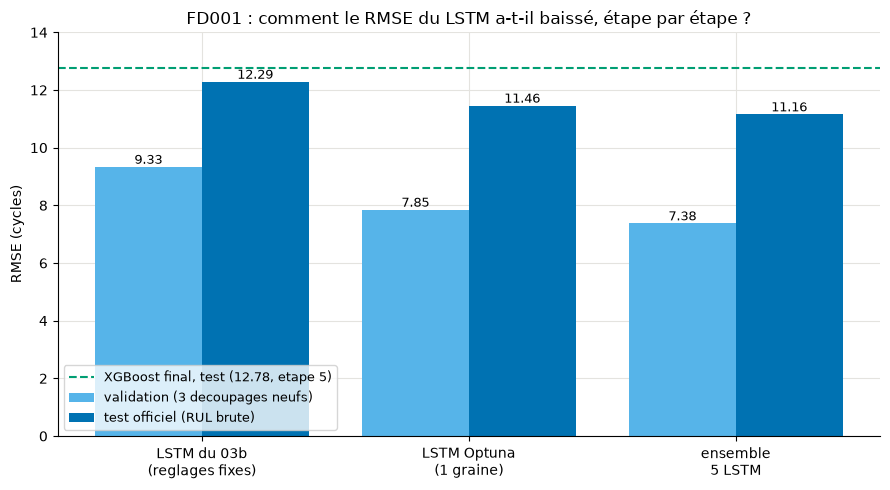

FD002, validation (3 decoupages neufs) : LSTM du 03b 10.28 -> LSTM Optuna 9.90 (retenu) -> ensemble de 5 LSTM Optuna 9.50
       test : ensemble 22.38 brut, 10.62 plafonne ; LSTM du 03b seul (graine 42, execution du 2026-11-04) 22.57 brut, 11.05 plafonne
FD003, validation (3 decoupages neufs) : LSTM du 03b 8.54 -> LSTM Optuna 8.09 (retenu) -> ensemble de 5 LSTM Optuna 7.59
       test : ensemble 13.30 brut, 12.05 plafonne ; LSTM du 03b seul (graine 42, execution du 2026-11-04) 13.40 brut, 11.93 plafonne
FD004, validation (3 decoupages neufs) : LSTM du 03b 11.11 -> LSTM Optuna 10.97 (NON retenu par la regle de confirmation) -> ensemble de 5 LSTM aux reglages du 03b 10.74
       test : ensemble 23.75 brut, 10.63 plafonne ; LSTM du 03b seul (graine 42, execution du 2026-11-04) 23.55 brut, 10.95 plafonne


In [46]:
# debut des noms de fichiers de chaque sous-jeu (FD001 et FD002 : nuit du 2026-11-07 ; FD003 et FD004 : du 07 au 08)
PREFIXES_04H = {"FD001": "04h_", "FD002": "04h_fd002_", "FD003": "04h_fd003_", "FD004": "04h_fd004_"}
DECOUPAGES_NEUFS = ["1000", "1001", "1002"]  # graines des 3 decoupages jamais utilises pour choisir
COULEURS_04H = {"lstm": "#0072B2", "cnn1d": "#E69F00", "reference": "#999999"}


def lire_json(sous_jeu, nom):
    """
    Relit un fichier de resultats du 04h (ex. lire_json("FD001", "confirmation_lstm")).

    Parameters
    ----------
    sous_jeu : str
        "FD001" a "FD004".
    nom : str
        Fin du nom de fichier, sans le prefixe du sous-jeu ni l'extension.

    Returns
    -------
    dict
        Le contenu du fichier JSON.
    """
    chemin = os.path.join(DOSSIER_04H, PREFIXES_04H[sous_jeu] + nom + ".json")
    with open(chemin, encoding="utf-8") as fichier:
        return json.load(fichier)


def moyenne_neufs(resume_cv):
    """
    RMSE de validation moyen sur les 3 decoupages neufs.

    Parameters
    ----------
    resume_cv : dict
        graine du decoupage -> {"rmse_cv_moyen", ...} (cles "cv_reference" ou "cv_candidat" d'un fichier
        de confirmation du 04h).

    Returns
    -------
    float
        La moyenne des 3 RMSE de validation.
    """
    valeurs = []
    for graine in DECOUPAGES_NEUFS:
        valeurs.append(resume_cv[graine]["rmse_cv_moyen"])
    return float(np.mean(valeurs))


anciens = pd.read_csv(os.path.join(DOSSIER_04H, "03b_deep_learning.csv"))  # anciens resultats relus par le 04h (reentrainement du 03b du 2026-11-05)
confirmation = lire_json("FD001", "confirmation_lstm")
ensembles = lire_json("FD001", "ensemble")
test_04h = lire_json("FD001", "test")["metriques_test"]
lstm_03b_fichier = anciens[(anciens["sous_jeu"] == "FD001") & (anciens["modele"] == "lstm")].iloc[0]

etapes = ["LSTM du 03b\n(reglages fixes)", "LSTM Optuna\n(1 graine)", "ensemble\n5 LSTM"]
validation = [moyenne_neufs(confirmation["cv_reference"]), moyenne_neufs(confirmation["cv_candidat"]),
              float(np.mean(ensembles["ensembles"]["lstm_5_graines"]["rmse_cv_par_decoupage"]))]
test_brut = [lstm_03b_fichier["rmse_test"], test_04h["lstm_g42"]["rmse"], test_04h["lstm_5_graines"]["rmse"]]
rmse_test_xgb_final = resultats_test_finaux["XGBoost Phase 3"]["rmse"]  # recalcule a l'etape 5

positions = np.arange(len(etapes))
fig, ax = plt.subplots(figsize=(9, 5))
barres_val = ax.bar(positions - 0.2, validation, width=0.4, color="#56B4E9", label="validation (3 decoupages neufs)")
barres_test = ax.bar(positions + 0.2, test_brut, width=0.4, color=COULEURS_04H["lstm"], label="test officiel (RUL brute)")
ax.axhline(rmse_test_xgb_final, color="#009E73", linestyle="--", label=f"XGBoost final, test ({rmse_test_xgb_final:.2f}, etape 5)")
for barres in [barres_val, barres_test]:
    for barre in barres:
        ax.annotate(f"{barre.get_height():.2f}", (barre.get_x() + barre.get_width() / 2, barre.get_height()),
                    ha="center", va="bottom", fontsize=9)
ax.set_xticks(positions)
ax.set_xticklabels(etapes)
ax.set_ylabel("RMSE (cycles)")
ax.set_ylim(0, 14)
ax.legend(loc="lower left", fontsize=9)
ax.set_title("FD001 : comment le RMSE du LSTM a-t-il baissé, étape par étape ?")
plt.tight_layout()
plt.show()

# FD002, FD003 et FD004 : la meme evolution en validation (3 decoupages neufs), puis le test de l'ensemble retenu.
# Le test "avant" de ces sous-jeux n'est pas dans les fichiers du 04h : on lit celui de l'execution du 03b du
# 2026-11-04 (docs/resultats/03b/03b_deep_learning.csv, relu a l'etape 3 : un seul LSTM, graine 42).
validation_autres = {}  # sous-jeu -> [LSTM du 03b, meilleur essai Optuna, ensemble de 5 LSTM], validation
optuna_lstm_retenu = {}  # sous-jeu -> le meilleur essai Optuna a-t-il passe la regle de confirmation ?
test_ensemble_autres = {}  # sous-jeu -> metriques test de l'ensemble de 5 LSTM (04h_..._test.json)
test_lstm_03b_autres = {}  # sous-jeu -> ligne du LSTM du 03b (test, execution du 2026-11-04)
for sous_jeu in ["FD002", "FD003", "FD004"]:
    confirmation_sous_jeu = lire_json(sous_jeu, "confirmation_lstm")
    ensembles_sous_jeu = lire_json(sous_jeu, "ensemble")
    valeurs = []
    valeurs.append(moyenne_neufs(confirmation_sous_jeu["cv_reference"]))  # reglages fixes du 03b
    valeurs.append(moyenne_neufs(confirmation_sous_jeu["cv_candidat"]))  # meilleur essai Optuna
    valeurs.append(float(np.mean(ensembles_sous_jeu["ensembles"]["lstm_5_graines"]["rmse_cv_par_decoupage"])))
    validation_autres[sous_jeu] = valeurs
    optuna_lstm_retenu[sous_jeu] = confirmation_sous_jeu["comparaison"]["retenu"]
    test_ensemble_autres[sous_jeu] = lire_json(sous_jeu, "test")["metriques_test"]["lstm_5_graines"]
    selection_03b = resultats_03b[(resultats_03b["sous_jeu"] == sous_jeu) & (resultats_03b["modele"] == "lstm")]
    test_lstm_03b_autres[sous_jeu] = selection_03b.iloc[0]
    if optuna_lstm_retenu[sous_jeu]:
        texte_optuna = f"LSTM Optuna {valeurs[1]:.2f} (retenu)"
        texte_ensemble = "ensemble de 5 LSTM Optuna"
    else:
        texte_optuna = f"LSTM Optuna {valeurs[1]:.2f} (NON retenu par la regle de confirmation)"
        texte_ensemble = "ensemble de 5 LSTM aux reglages du 03b"
    print(f"{sous_jeu}, validation (3 decoupages neufs) : LSTM du 03b {valeurs[0]:.2f} -> {texte_optuna} "
          f"-> {texte_ensemble} {valeurs[2]:.2f}")
    print(f"       test : ensemble {test_ensemble_autres[sous_jeu]['rmse']:.2f} brut, "
          f"{test_ensemble_autres[sous_jeu]['rmse_contre_rul_plafonnee']:.2f} plafonne ; "
          f"LSTM du 03b seul (graine 42, execution du 2026-11-04) {test_lstm_03b_autres[sous_jeu]['rmse_test']:.2f} brut, "
          f"{test_lstm_03b_autres[sous_jeu]['rmse_test_rul_plafonnee']:.2f} plafonne")
validation_fd002 = validation_autres["FD002"]  # noms gardes pour les controles de 6.1 et de la section 8
test_04h_fd002 = lire_json("FD002", "test")["metriques_test"]

# marches de l'escalier FD001 : validation sur les plis de graine 42 quand elle existe (comparable aux etapes 1 a 5)
ajouter_marche("6a", "LSTM Optuna, 1 graine", confirmation["cv_candidat"]["42"]["rmse_cv_moyen"],
               "5 plis, graine 42 (plis de la recherche : optimiste)", test_04h["lstm_g42"]["rmse"],
               "lu : docs/resultats/04h/04h_confirmation_lstm.json, 04h_test.json")
ajouter_marche("6b", "Ensemble de 5 LSTM Optuna (retenu)", validation[2], "3 decoupages neufs (graines 1000-1002)",
               test_04h["lstm_5_graines"]["rmse"], "lu : docs/resultats/04h/04h_ensemble.json, 04h_test.json")

### 6.1 Lecture de l'étape 6

- Les deux séries baissent ensemble, dans le même ordre : ce que la validation annonçait, le test le confirme.
- Mais **le gain au test est plus petit que le gain en validation** : 1,13 cycle au test (12,29 → 11,16) contre 1,96 en validation (9,33 → 7,38 ; le texte du 04h écrivait 9,34, arrondi différent du même chiffre, 9,3316). Une part du gain de validation ne se retrouve pas au test : c'est attendu quand on choisit parmi beaucoup d'essais, et c'est la raison pour laquelle on annonce le chiffre du test.
- Pourquoi la validation est plus basse que le test : elle porte sur toutes les lignes (beaucoup de cycles en début de vie, où la cible plafonnée vaut 125 et se prédit bien), le test seulement sur le dernier cycle de chaque moteur test, dont la vraie RUL n'est pas plafonnée.
- **FD002**, en validation : 10,28 → 9,90 → 9,50.
- **FD003**, en validation : 8,54 → 8,09 (Optuna retenu) → 7,59, soit 0,95 cycle de gain. Au test, l'ensemble fait 13,30 (12,05 contre la RUL plafonnée), contre 13,40 (11,93) pour le LSTM du 03b seul : presque rien du gain de validation ne se retrouve au test sur ce sous-jeu.
- **FD004**, en validation : 11,11 → 10,97 pour le meilleur essai Optuna, **non retenu** (gain 0,14 cycle, meilleur sur 1 découpage sur 3) ; l'ensemble est donc fait de 5 LSTM aux réglages du 03b : 10,74. Au test, 23,75 brut (10,63 plafonné), contre 23,55 (10,95) pour le LSTM du 03b seul : un peu moins bon contre la RUL brute, un peu meilleur contre la RUL plafonnée. Ces deux écarts sont lus sur le test, sans test apparié : ils ne changent aucun choix.

In [47]:
verifier("Etape 6 : test LSTM du 03b (fichier)", 12.29, test_brut[0])
verifier("Etape 6 : test ensemble 5 LSTM", 11.16, test_brut[2])
verifier("Etape 6 : gain au test", 1.13, test_brut[0] - test_brut[2])
verifier("Etape 6 : validation LSTM du 03b (3 decoupages neufs)", 9.33, validation[0])
verifier("Etape 6 : validation ensemble 5 LSTM", 7.38, validation[2])
verifier("Etape 6 : gain en validation", 1.96, validation[0] - validation[2])
verifier("Etape 6 : FD002, validation LSTM du 03b", 10.28, validation_fd002[0])
verifier("Etape 6 : FD002, validation LSTM Optuna", 9.90, validation_fd002[1])
verifier("Etape 6 : FD002, validation ensemble", 9.50, validation_fd002[2])
verifier("Etape 6 : FD003, validation LSTM du 03b", 8.54, validation_autres["FD003"][0])
verifier("Etape 6 : FD003, validation LSTM Optuna", 8.09, validation_autres["FD003"][1])
verifier("Etape 6 : FD003, LSTM Optuna retenu", 1, float(optuna_lstm_retenu["FD003"]), decimales=0)
verifier("Etape 6 : FD003, validation ensemble", 7.59, validation_autres["FD003"][2])
verifier("Etape 6 : FD003, gain en validation", 0.95, validation_autres["FD003"][0] - validation_autres["FD003"][2])
verifier("Etape 6 : FD003, test ensemble", 13.30, test_ensemble_autres["FD003"]["rmse"])
verifier("Etape 6 : FD003, test ensemble, RUL plafonnee", 12.05, test_ensemble_autres["FD003"]["rmse_contre_rul_plafonnee"])
verifier("Etape 6 : FD003, test LSTM du 03b", 13.40, test_lstm_03b_autres["FD003"]["rmse_test"])
verifier("Etape 6 : FD003, test LSTM du 03b, RUL plafonnee", 11.93, test_lstm_03b_autres["FD003"]["rmse_test_rul_plafonnee"])
verifier("Etape 6 : FD004, validation LSTM du 03b", 11.11, validation_autres["FD004"][0])
verifier("Etape 6 : FD004, validation meilleur essai Optuna", 10.97, validation_autres["FD004"][1])
verifier("Etape 6 : FD004, LSTM Optuna non retenu", 0, float(optuna_lstm_retenu["FD004"]), decimales=0)
verifier("Etape 6 : FD004, gain Optuna non retenu", 0.14, lire_json("FD004", "confirmation_lstm")["comparaison"]["gain_moyen"])
verifier("Etape 6 : FD004, decoupages gagnes par Optuna", 1, lire_json("FD004", "confirmation_lstm")["comparaison"]["nb_decoupages_gagnes"], decimales=0)
verifier("Etape 6 : FD004, validation ensemble", 10.74, validation_autres["FD004"][2])
verifier("Etape 6 : FD004, test ensemble", 23.75, test_ensemble_autres["FD004"]["rmse"])
verifier("Etape 6 : FD004, test ensemble, RUL plafonnee", 10.63, test_ensemble_autres["FD004"]["rmse_contre_rul_plafonnee"])
verifier("Etape 6 : FD004, test LSTM du 03b", 23.55, test_lstm_03b_autres["FD004"]["rmse_test"])
verifier("Etape 6 : FD004, test LSTM du 03b, RUL plafonnee", 10.95, test_lstm_03b_autres["FD004"]["rmse_test_rul_plafonnee"])

OK    Etape 6 : test LSTM du 03b (fichier) : cite 12.29, calcule 12.29
OK    Etape 6 : test ensemble 5 LSTM : cite 11.16, calcule 11.16
OK    Etape 6 : gain au test : cite 1.13, calcule 1.13
OK    Etape 6 : validation LSTM du 03b (3 decoupages neufs) : cite 9.33, calcule 9.33
OK    Etape 6 : validation ensemble 5 LSTM : cite 7.38, calcule 7.38
OK    Etape 6 : gain en validation : cite 1.96, calcule 1.96
OK    Etape 6 : FD002, validation LSTM du 03b : cite 10.28, calcule 10.28
OK    Etape 6 : FD002, validation LSTM Optuna : cite 9.9, calcule 9.9
OK    Etape 6 : FD002, validation ensemble : cite 9.5, calcule 9.5
OK    Etape 6 : FD003, validation LSTM du 03b : cite 8.54, calcule 8.54
OK    Etape 6 : FD003, validation LSTM Optuna : cite 8.09, calcule 8.09
OK    Etape 6 : FD003, LSTM Optuna retenu : cite 1, calcule 1.0
OK    Etape 6 : FD003, validation ensemble : cite 7.59, calcule 7.59
OK    Etape 6 : FD003, gain en validation : cite 0.95, calcule 0.95
OK    Etape 6 : FD003, test ensemble 

True

### 6.2 Le test officiel du 04h, lu une seule fois (04h, section 7)

*Notebook 04h, section 7, déplacée avec ses cellules* (le tableau, ses remarques et la figure « Où l'ensemble retenu se trompe-t-il au test ? »). Les modèles finaux sont entraînés sur **tous** les moteurs du train, pendant un nombre d'époques fixé par la validation (médiane des meilleures époques des 5 plis de la graine 42), puis notés au dernier cycle de chaque moteur test, comme le benchmark. Deux RMSE : contre la vraie RUL brute (le chiffre officiel), et contre la RUL plafonnée à 125 (ce que le modèle peut atteindre, puisque sa cible est plafonnée).

Les anciens résultats sont gardés à côté, pour la comparaison (ceux que relit le 04h : `docs/resultats/04h/03b_deep_learning.csv`, réentraînement du 03b du 2026-11-05).

In [48]:
# anciens resultats : notebook 03b (fichier 03b_deep_learning.csv du 04h) et XGBoost final publie (src/config_modele.py)
RESEAUX_04H = {"lstm": "LSTM", "cnn1d": "CNN 1D"}
lignes = []
for _, ligne in anciens.iterrows():
    lignes.append({"sous-jeu": ligne["sous_jeu"], "modele": RESEAUX_04H[ligne["modele"]] + " du 03b (avant)",
                   "RMSE brute": round(ligne["rmse_test"], 2), "RMSE plafonnee": round(ligne["rmse_test_rul_plafonnee"], 2),
                   "score NASA": round(ligne["nasa_test"], 1), "retenu": ""})
lignes.append({"sous-jeu": "FD001", "modele": "XGBoost final (04f), chiffre publie", "RMSE brute": CONFIG_XGBOOST_FINAL["metriques_test"]["rmse"],
               "RMSE plafonnee": None, "score NASA": CONFIG_XGBOOST_FINAL["metriques_test"]["score_nasa"], "retenu": ""})

# nouveaux resultats : chaque reseau seul (graine 42), la moyenne et l'ecart-type sur 5 graines, les ensembles
NOMS_TEST_04H = {"lstm_g42": "LSTM Optuna, graine 42", "cnn1d_g42": "CNN 1D, graine 42",
                 "lstm_5_graines": "ensemble 5 LSTM", "lstm_cnn_10": "ensemble 5 LSTM + 5 CNN"}
for sous_jeu in PREFIXES_04H:
    test_sous_jeu = lire_json(sous_jeu, "test")["metriques_test"]
    for cle in NOMS_TEST_04H:
        nom = NOMS_TEST_04H[cle]
        # reseau dont le meilleur essai Optuna n'a pas passe la confirmation : il garde les reglages du 03b
        # (CNN 1D de FD002, LSTM et CNN 1D de FD004), lu dans le fichier de confirmation, pas ecrit a la main
        if cle == "lstm_g42" and not lire_json(sous_jeu, "confirmation_lstm")["comparaison"]["retenu"]:
            nom = "LSTM (reglages du 03b), graine 42"
        if cle == "lstm_5_graines" and not lire_json(sous_jeu, "confirmation_lstm")["comparaison"]["retenu"]:
            nom = "ensemble 5 LSTM (reglages du 03b)"
        if cle == "cnn1d_g42" and not lire_json(sous_jeu, "confirmation_cnn1d")["comparaison"]["retenu"]:
            nom = "CNN 1D (reglages du 03b), graine 42"
        retenu = ""
        if cle == "lstm_5_graines":
            retenu = "OUI"  # le modele retenu par le 04h
        lignes.append({"sous-jeu": sous_jeu, "modele": nom, "RMSE brute": round(test_sous_jeu[cle]["rmse"], 2),
                       "RMSE plafonnee": round(test_sous_jeu[cle]["rmse_contre_rul_plafonnee"], 2),
                       "score NASA": round(test_sous_jeu[cle]["score_nasa"], 1), "retenu": retenu})
    for reseau in RESEAUX_04H:  # robustesse a la graine : 5 modeles de la meme configuration
        valeurs = []
        for graine in [42, 43, 44, 45, 46]:
            valeurs.append(test_sous_jeu[f"{reseau}_g{graine}"]["rmse"])
        print(f"{sous_jeu}, {RESEAUX_04H[reseau]} seul, 5 graines : RMSE brute {np.mean(valeurs):.2f} +- {np.std(valeurs):.2f} "
              f"(de {min(valeurs):.2f} a {max(valeurs):.2f})")
tableau_test_04h = pd.DataFrame(lignes)
tableau_test_04h

FD001, LSTM seul, 5 graines : RMSE brute 11.73 +- 0.24 (de 11.44 a 12.01)
FD001, CNN 1D seul, 5 graines : RMSE brute 12.89 +- 1.58 (de 11.68 a 15.78)
FD002, LSTM seul, 5 graines : RMSE brute 22.65 +- 0.64 (de 21.97 a 23.86)
FD002, CNN 1D seul, 5 graines : RMSE brute 24.06 +- 1.06 (de 23.00 a 26.09)
FD003, LSTM seul, 5 graines : RMSE brute 13.41 +- 0.18 (de 13.14 a 13.68)
FD003, CNN 1D seul, 5 graines : RMSE brute 13.34 +- 1.18 (de 11.92 a 15.21)
FD004, LSTM seul, 5 graines : RMSE brute 24.43 +- 1.96 (de 22.64 a 28.15)
FD004, CNN 1D seul, 5 graines : RMSE brute 26.67 +- 1.55 (de 23.79 a 28.45)


,sous-jeu,modele,RMSE brute,RMSE plafonnee,score NASA,retenu
0,FD001,LSTM du 03b (avant),12.29,11.37,228.7,
1,FD001,CNN 1D du 03b (avant),13.09,12.60,436.9,
2,FD001,"XGBoost final (04f), chiffre publie",12.73,NaN,223.5,
3,FD001,"LSTM Optuna, graine 42",11.46,10.37,212.9,
4,FD001,"CNN 1D, graine 42",11.68,10.33,189.3,
5,FD001,ensemble 5 LSTM,11.16,10.09,227.2,OUI
6,FD001,ensemble 5 LSTM + 5 CNN,10.97,9.72,190.9,
7,FD002,"LSTM Optuna, graine 42",23.86,10.88,4660.7,
8,FD002,"CNN 1D (reglages du 03b), graine 42",23.89,11.16,4436.5,
9,FD002,ensemble 5 LSTM,22.38,10.62,3432.5,OUI


**Deux remarques sur les anciens chiffres** (04h, section 7).

- Le CNN 1D du 03b vaut ici 13,09 au test FD001, alors que `STATUS.md` (entrée du 2026-11-05) indique 12,74. Le fichier `03b_deep_learning.csv` du 04h a été réécrit par un entraînement plus récent du 03b (même date, 3 graines, moyenne 12,18). On affiche le fichier, sans retoucher aucun des deux chiffres ; l'écart montre surtout combien le CNN du 03b dépend de sa graine. (Les étapes 3 et 4 de ce notebook, et `02_choix_du_modele`, lisent l'exécution qui donne 12,74 : `docs/resultats/03b/`.)
- Le 03b n'a pas enregistré de test des réseaux sur FD002 dans les fichiers du 04h : pour FD002, la comparaison avant / après se fait seulement en validation (section 6.1). Même chose pour FD003 et FD004 dans les fichiers du 04h ; pour ces deux sous-jeux, la section 6.1 cite le test du LSTM du 03b de l'exécution du 2026-11-04 (`docs/resultats/03b/`, un seul réseau, graine 42).

**Lecture** (04h, section 7).

- **FD001** : l'ensemble de 5 LSTM fait **11,16** (10,09 plafonné), contre 12,29 pour le LSTM du 03b et 12,73 pour le XGBoost final publié (12,78 recalculé à l'étape 5 sur la machine de génération). Le gain vient d'abord d'Optuna (12,29 → 11,46 pour un LSTM seul), puis de l'ensemble (11,46 → 11,16).
- Le CNN 1D seul est très sensible à la graine (12,89 ± 1,58 sur 5 graines) : c'est une raison de plus de ne pas l'utiliser seul.
- **FD002** : 22,38 brut mais 10,62 plafonné. L'écart vient des moteurs test dont la vraie RUL dépasse 125 : 57 sur 259 (22 %) sur FD002, contre 11 sur 100 sur FD001 (figure ci-dessous). Le modèle, entraîné sur une cible plafonnée, ne prédit jamais beaucoup plus de 125.
- **FD003** : l'ensemble de 5 LSTM fait 13,30 (12,05 plafonné), **moins bien au test que le XGBoost final** (11,78, 9,96 plafonné, `sorties/predictions/`), alors que la validation le plaçait devant (`resultats/FD003`, section 3). L'ensemble à 10 réseaux (5 LSTM + 5 CNN) fait 12,24 au test ; il n'a pas été retenu, car en validation il ne gagnait que 0,27 cycle sur les 5 LSTM (seuil : 0,3). Le reprendre maintenant parce qu'il est meilleur au test reviendrait à choisir sur le test : le choix reste celui de la validation, et le résultat du test est écrit tel quel.
- **FD004** : 23,75 brut mais 10,63 plafonné ; 67 moteurs test sur 248 (27 %) ont une vraie RUL au-dessus de 125. Aucun des deux réseaux n'a vu ses réglages Optuna confirmés : le gain de validation vient de la moyenne de 5 graines (11,11 → 10,74), pas d'Optuna.

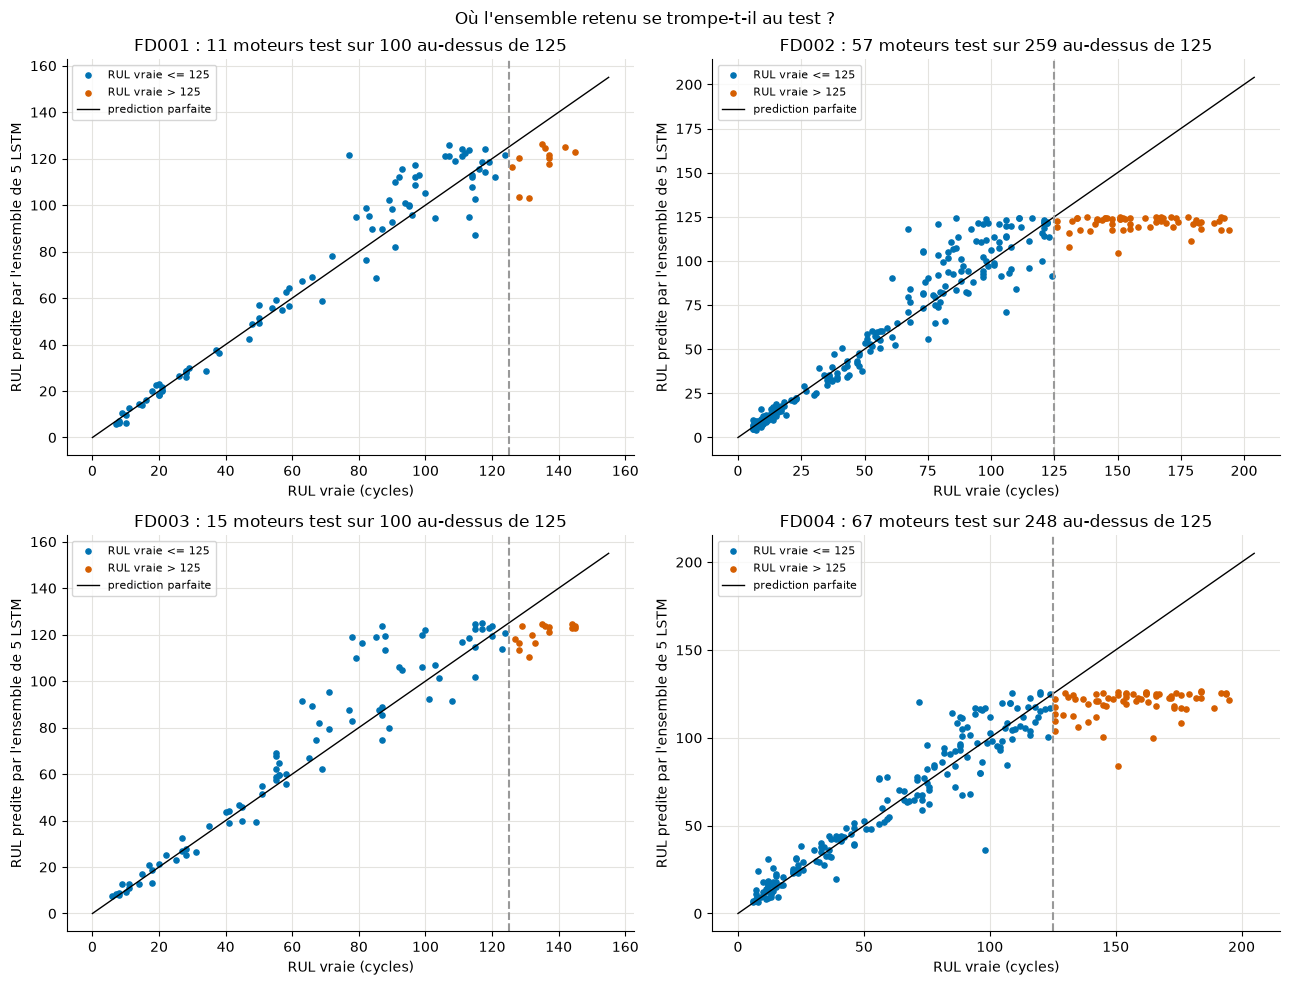

OK    Etape 6, 04h section 7 : CNN 1D du 03b au test (fichier du 04h) : cite 13.09, calcule 13.09
OK    Etape 6, 04h section 7 : ensemble 5 LSTM FD001, RUL plafonnee : cite 10.09, calcule 10.09
OK    Etape 6, 04h section 7 : LSTM Optuna seul FD001 : cite 11.46, calcule 11.46
OK    Etape 6, 04h section 7 : ensemble 5 LSTM FD002, RUL plafonnee : cite 10.62, calcule 10.62
OK    Etape 6, 04h section 7 : ensemble 5 LSTM FD003 : cite 13.3, calcule 13.3
OK    Etape 6, 04h section 7 : ensemble 5 LSTM FD003, RUL plafonnee : cite 12.05, calcule 12.05
OK    Etape 6, 04h section 7 : XGBoost final FD003 (demo) : cite 11.78, calcule 11.78
OK    Etape 6, 04h section 7 : XGBoost final FD003 (demo), RUL plafonnee : cite 9.96, calcule 9.96
OK    Etape 6, 04h section 7 : ensemble 5 LSTM + 5 CNN FD003 : cite 12.24, calcule 12.24
OK    Etape 6, 04h section 7 : FD003, gain validation 10 reseaux sur 5 LSTM : cite 0.27, calcule 0.27
OK    Etape 6, 04h section 7 : ensemble 5 LSTM FD004 : cite 23.75, calcule 23

True

In [49]:
# --- Figure : prediction au dernier cycle contre la vraie RUL, ensemble retenu (04h, section 7) ---
fig, axes = plt.subplots(2, 2, figsize=(13, 10))  # une case par sous-jeu
axes = axes.ravel()  # les 4 cases dans l'ordre FD001, FD002, FD003, FD004
for i, sous_jeu in enumerate(PREFIXES_04H):
    predictions = pd.read_csv(os.path.join(DOSSIER_04H, PREFIXES_04H[sous_jeu] + "test_dernier_cycle.csv"))
    vraie = predictions["rul_vraie"].to_numpy()
    predite = predictions["lstm_5_graines"].to_numpy()
    au_dessus = vraie > opt.PLAFOND_RUL  # moteurs dont la vraie RUL depasse le plafond
    ax = axes[i]
    ax.scatter(vraie[~au_dessus], predite[~au_dessus], s=14, color=COULEURS_04H["lstm"], label="RUL vraie <= 125")
    ax.scatter(vraie[au_dessus], predite[au_dessus], s=14, color="#D55E00", label="RUL vraie > 125")
    limite = max(vraie.max(), predite.max()) + 10
    ax.plot([0, limite], [0, limite], color="black", linewidth=1, label="prediction parfaite")
    ax.axvline(opt.PLAFOND_RUL, color=COULEURS_04H["reference"], linestyle="--")
    ax.set_xlabel("RUL vraie (cycles)")
    ax.set_ylabel("RUL predite par l'ensemble de 5 LSTM")
    ax.set_title(f"{sous_jeu} : {int(au_dessus.sum())} moteurs test sur {len(vraie)} au-dessus de 125")
    ax.legend(fontsize=8)
fig.suptitle("Où l'ensemble retenu se trompe-t-il au test ?")
plt.tight_layout()
plt.show()

# controle des chiffres cites dans la lecture ci-dessus
test_fd001_04h = lire_json("FD001", "test")["metriques_test"]
test_fd002_04h = lire_json("FD002", "test")["metriques_test"]
verifier("Etape 6, 04h section 7 : CNN 1D du 03b au test (fichier du 04h)", 13.09,
         anciens[(anciens["sous_jeu"] == "FD001") & (anciens["modele"] == "cnn1d")].iloc[0]["rmse_test"])
verifier("Etape 6, 04h section 7 : ensemble 5 LSTM FD001, RUL plafonnee", 10.09, test_fd001_04h["lstm_5_graines"]["rmse_contre_rul_plafonnee"])
verifier("Etape 6, 04h section 7 : LSTM Optuna seul FD001", 11.46, test_fd001_04h["lstm_g42"]["rmse"])
verifier("Etape 6, 04h section 7 : ensemble 5 LSTM FD002, RUL plafonnee", 10.62, test_fd002_04h["lstm_5_graines"]["rmse_contre_rul_plafonnee"])
# FD003 et FD004 (nuit du 2026-11-07 au 08) : chiffres de la lecture ci-dessus
test_fd003_04h = lire_json("FD003", "test")["metriques_test"]
test_fd004_04h = lire_json("FD004", "test")["metriques_test"]
with open(os.path.join("..", "sorties", "predictions", "FD003__xgboost_phase3.json"), encoding="utf-8") as fichier:
    xgboost_final_fd003 = json.load(fichier)["metriques_test"]  # XGBoost final de la demo (fichier non versionne)
ensembles_fd003 = lire_json("FD003", "ensemble")["ensembles"]
gain_10_sur_5_fd003 = (float(np.mean(ensembles_fd003["lstm_5_graines"]["rmse_cv_par_decoupage"]))
                       - float(np.mean(ensembles_fd003["lstm_cnn_10"]["rmse_cv_par_decoupage"])))
predictions_fd004 = pd.read_csv(os.path.join(DOSSIER_04H, PREFIXES_04H["FD004"] + "test_dernier_cycle.csv"))
verifier("Etape 6, 04h section 7 : ensemble 5 LSTM FD003", 13.30, test_fd003_04h["lstm_5_graines"]["rmse"])
verifier("Etape 6, 04h section 7 : ensemble 5 LSTM FD003, RUL plafonnee", 12.05, test_fd003_04h["lstm_5_graines"]["rmse_contre_rul_plafonnee"])
verifier("Etape 6, 04h section 7 : XGBoost final FD003 (demo)", 11.78, xgboost_final_fd003["rmse"])
verifier("Etape 6, 04h section 7 : XGBoost final FD003 (demo), RUL plafonnee", 9.96, xgboost_final_fd003["rmse_contre_rul_plafonnee"])
verifier("Etape 6, 04h section 7 : ensemble 5 LSTM + 5 CNN FD003", 12.24, test_fd003_04h["lstm_cnn_10"]["rmse"])
verifier("Etape 6, 04h section 7 : FD003, gain validation 10 reseaux sur 5 LSTM", 0.27, gain_10_sur_5_fd003)
verifier("Etape 6, 04h section 7 : ensemble 5 LSTM FD004", 23.75, test_fd004_04h["lstm_5_graines"]["rmse"])
verifier("Etape 6, 04h section 7 : ensemble 5 LSTM FD004, RUL plafonnee", 10.63, test_fd004_04h["lstm_5_graines"]["rmse_contre_rul_plafonnee"])
verifier("Etape 6, 04h section 7 : FD004, moteurs test au-dessus de 125", 67, int((predictions_fd004["rul_vraie"] > opt.PLAFOND_RUL).sum()), decimales=0)
verifier("Etape 6, 04h section 7 : FD004, part au-dessus de 125 (%)", 27, 100 * (predictions_fd004["rul_vraie"] > opt.PLAFOND_RUL).mean(), decimales=0)

**Lecture** (04h, section 7). Sous 125 cycles, les points suivent la diagonale, et les erreurs grandissent avec la RUL (un moteur encore loin de la panne donne peu de signal). Au-dessus de 125, les prédictions restent bloquées vers 125 : c'est le plafond de la cible, choisi en Phase 2. FD002 et FD004 ont beaucoup plus de moteurs test dans ce cas que FD001 et FD003, ce qui explique presque tout leur RMSE brut élevé.

## 7. Pistes et diagnostics

Ce qu'on a essayé ou mesuré **sans le retenir**, avec sa figure (décision de Matisse du 2026-11-07 : aucun graphe supprimé). Tout vient du notebook [05_comparaison_evaluation](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/05_comparaison_evaluation.ipynb), sur les modèles à réglages de base de l'étape 4 (46 variables), calculés en direct.

### 7.1 Rendre le modèle plus prudent : où mettre la pénalité ? (05, section C)

**Rappel — score NASA** : pour un écart d = prédiction − vérité, la pénalité vaut exp(d / 10) − 1 si le modèle surestime (d ≥ 0) et exp(−d / 13) − 1 s'il sous-estime ; le score est la somme des pénalités. Exemple : surestimer de 20 cycles coûte e² − 1 ≈ 6,4 ; sous-estimer de 20 cycles coûte e^(20/13) − 1 ≈ 3,7.

**Fausse piste : changer 13 et 10 dans la note ne change aucune prédiction.** On multiplie les deux constantes par un facteur k et on recalcule le score des **mêmes** prédictions test de XGBoost Phase 3. L'idée de départ était de « faire varier 10 et 13 » pour rendre le modèle plus prudent ; on montre que cela change la note, pas le modèle. Le test sert ici à une démonstration, pas à un choix.

In [50]:
# modele Phase 3 entraine sur les 100 moteurs d'entrainement (comme en Phase 3), puis predictions des 100 moteurs test
modele_phase3_demo = construire_fabrique_depuis_config(CONFIG_XGB_PHASE3)()  # la fabrique, appelee avec () : un modele neuf
modele_phase3_demo.fit(X, y)
predictions_test_phase3_demo = np.clip(modele_phase3_demo.predict(X_test_dernier), a_min=0, a_max=None)  # RUL negative -> 0

# les memes predictions, notees avec les constantes 13 x k et 10 x k
tableau_constantes = demontrer_constantes_score_degenerees(y_test_vraie, predictions_test_phase3_demo,
                                                          facteurs=(1, 2, 5, 10, 100, 1000))
tableau_constantes["rmse_test"] = rmse(y_test_vraie, predictions_test_phase3_demo)  # predictions inchangees : meme RMSE
tableau_constantes.round(3)

,facteur,a_sous,a_sur,score_nasa,predictions_inchangees,rmse_test
0,1,13,10,852.891,True,19.7
1,2,26,20,131.669,True,19.7
2,5,65,50,32.482,True,19.7
3,10,130,100,14.222,True,19.7
4,100,1300,1000,1.275,True,19.7
5,1000,13000,10000,0.126,True,19.7


**Comment lire** : les prédictions et le RMSE sont identiques sur toutes les lignes, seule la note change ; plus k est grand, plus le score tend vers 0, et ce serait vrai pour n'importe quel modèle, même mauvais.

**La bonne piste : la pénalité dans la perte d'apprentissage**, la quantité que le modèle rend la plus petite possible pendant l'entraînement. Deux pertes sur mesure existent dans `src/modeles.py` :
- **quadratique asymétrique** : erreur² × α si le modèle surestime, erreur² sinon (avec α = 2 : surestimer de 10 cycles coûte 200, sous-estimer de 10 cycles coûte 100) ;
- **forme NASA** : la forme du score NASA, avec des constantes h_sous et h_sur réglables (prolongée par une parabole au-delà de 50 cycles d'écart).

Une expérience sur une petite grille, mêmes plis : XGBoost (réglages Phase 3) et LightGBM (réglages de base) avec α ∈ {1 ; 1,5 ; 2 ; 3} ; XGBoost avec la perte NASA (13, 10) et (13, 5), à 200 arbres puis à 1 000 et 2 000 arbres au pas 0,1 (avec la perte NASA, chaque arbre ne déplace les prédictions que d'environ « pas × h » cycles : 200 arbres peuvent ne pas suffire). Aucun modèle n'est choisi ici.

In [51]:
reglages_penalite = []  # une entree par reglage : nom lisible, groupe (pour la figure) et configuration

for alpha in [1.0, 1.5, 2.0, 3.0]:  # XGBoost, perte quadratique asymetrique, reglages Phase 3
    reglage = {}
    reglage["reglage"] = f"XGBoost quadratique alpha={alpha:g}"  # :g affiche 1.0 comme "1" et 1.5 comme "1.5"
    reglage["groupe"] = "XGBoost quadratique asymétrique"
    reglage["config"] = {"famille": "xgboost", "perte": "quadratique_asymetrique",
                         "parametres_perte": {"alpha": alpha}, "hyperparametres": {"n_jobs": N_JOBS_ARBRES}}
    reglages_penalite.append(reglage)

for alpha in [1.0, 1.5, 2.0, 3.0]:  # LightGBM, perte quadratique asymetrique, reglages de base
    reglage = {}
    reglage["reglage"] = f"LightGBM quadratique alpha={alpha:g}"
    reglage["groupe"] = "LightGBM quadratique asymétrique"
    reglage["config"] = {"famille": "lightgbm", "perte": "quadratique_asymetrique",
                         "parametres_perte": {"alpha": alpha}, "hyperparametres": {"n_jobs": N_JOBS_ARBRES}}
    reglages_penalite.append(reglage)

for h_sous, h_sur in [(13.0, 10.0), (13.0, 5.0)]:  # XGBoost, perte de forme NASA (h_sur = 5 : plus prudent)
    for n_arbres, pas in [(200, 0.05), (1000, 0.1), (2000, 0.1)]:  # reglages Phase 3, puis beaucoup plus d'arbres
        reglage = {}
        reglage["reglage"] = f"XGBoost NASA ({h_sous:g},{h_sur:g}) {n_arbres} arbres pas {pas:g}"
        if n_arbres == 200:
            reglage["groupe"] = "XGBoost perte NASA, 200 arbres"
        else:
            reglage["groupe"] = "XGBoost perte NASA, 1000-2000 arbres"
        reglage["config"] = {"famille": "xgboost", "perte": "nasa",
                             "parametres_perte": {"h_sous": h_sous, "h_sur": h_sur},
                             "hyperparametres": {"n_estimators": n_arbres, "learning_rate": pas, "n_jobs": N_JOBS_ARBRES}}
        reglages_penalite.append(reglage)

resultats_cv_penalite = {}  # nom du reglage -> resultats de la validation croisee (memes 5 plis)
for reglage in reglages_penalite:
    fabrique = construire_fabrique_depuis_config(reglage["config"])
    debut = time.perf_counter()
    resultats_cv_penalite[reglage["reglage"]] = evaluer_en_validation_croisee(
        fabrique, X, y, groups, plis, seuil_surestimation=SEUIL_SURESTIMATION, seuil_alerte=SEUIL_ALERTE
    )
    print(f"{reglage['reglage']:45s} ({time.perf_counter() - debut:5.1f} s)")  # nom, puis duree des 5 plis

lignes = []
# premiere ligne : XGBoost Phase 3 de la section 4.1, comme reference
ligne_reference = resumer_cv("XGBoost Phase 3 (perte native)", resultats_cv_base["XGBoost Phase 3"], NB_MOTEURS_TRAIN)
ligne_reference["groupe"] = "référence"
lignes.append(ligne_reference)
for reglage in reglages_penalite:  # puis une ligne par reglage de la grille
    ligne = resumer_cv(reglage["reglage"], resultats_cv_penalite[reglage["reglage"]], NB_MOTEURS_TRAIN)
    ligne["groupe"] = reglage["groupe"]
    lignes.append(ligne)
tableau_penalite = pd.DataFrame(lignes).set_index("modele")
colonnes_affichees = ["rmse_cv_moyen", "rmse_cv_ecart_type", "nasa_cv_moyen", "surestimes_oof",
                      "alertes_manquees_oof", "fausses_alertes_oof", "biais_oof", "temps_entrainement_5_plis_s"]
tableau_penalite[colonnes_affichees].round(2)

XGBoost quadratique alpha=1                   (  2.2 s)


XGBoost quadratique alpha=1.5                 (  2.1 s)


XGBoost quadratique alpha=2                   (  2.2 s)


XGBoost quadratique alpha=3                   (  2.1 s)


LightGBM quadratique alpha=1                  (  4.1 s)


LightGBM quadratique alpha=1.5                (  4.1 s)


... (5 outputs left out)

XGBoost NASA (13,5) 200 arbres pas 0.05       (  2.2 s)


XGBoost NASA (13,5) 1000 arbres pas 0.1       ( 10.3 s)


XGBoost NASA (13,5) 2000 arbres pas 0.1       ( 18.2 s)


,rmse_cv_moyen,rmse_cv_ecart_type,nasa_cv_moyen,surestimes_oof,alertes_manquees_oof,fausses_alertes_oof,biais_oof,temps_entrainement_5_plis_s
modele,,,,,,,,
XGBoost Phase 3 (perte native),16.87,1.25,29782.56,2384,552,259,-0.16,1.77
XGBoost quadratique alpha=1,16.86,1.30,29119.88,2386,553,266,-0.21,2.15
XGBoost quadratique alpha=1.5,16.98,1.56,26981.81,2087,491,323,-1.58,2.02
XGBoost quadratique alpha=2,17.20,1.78,25513.73,1895,469,366,-2.64,2.14
XGBoost quadratique alpha=3,17.68,2.09,25527.42,1590,431,435,-4.16,2.04
LightGBM quadratique alpha=1,16.85,1.30,30141.84,2316,568,243,-0.22,4.03
LightGBM quadratique alpha=1.5,16.99,1.52,27900.74,2071,508,316,-1.50,4.06
LightGBM quadratique alpha=2,17.14,1.74,27164.88,1908,473,365,-2.37,4.02
LightGBM quadratique alpha=3,17.45,1.92,25660.44,1675,435,427,-3.65,4.07


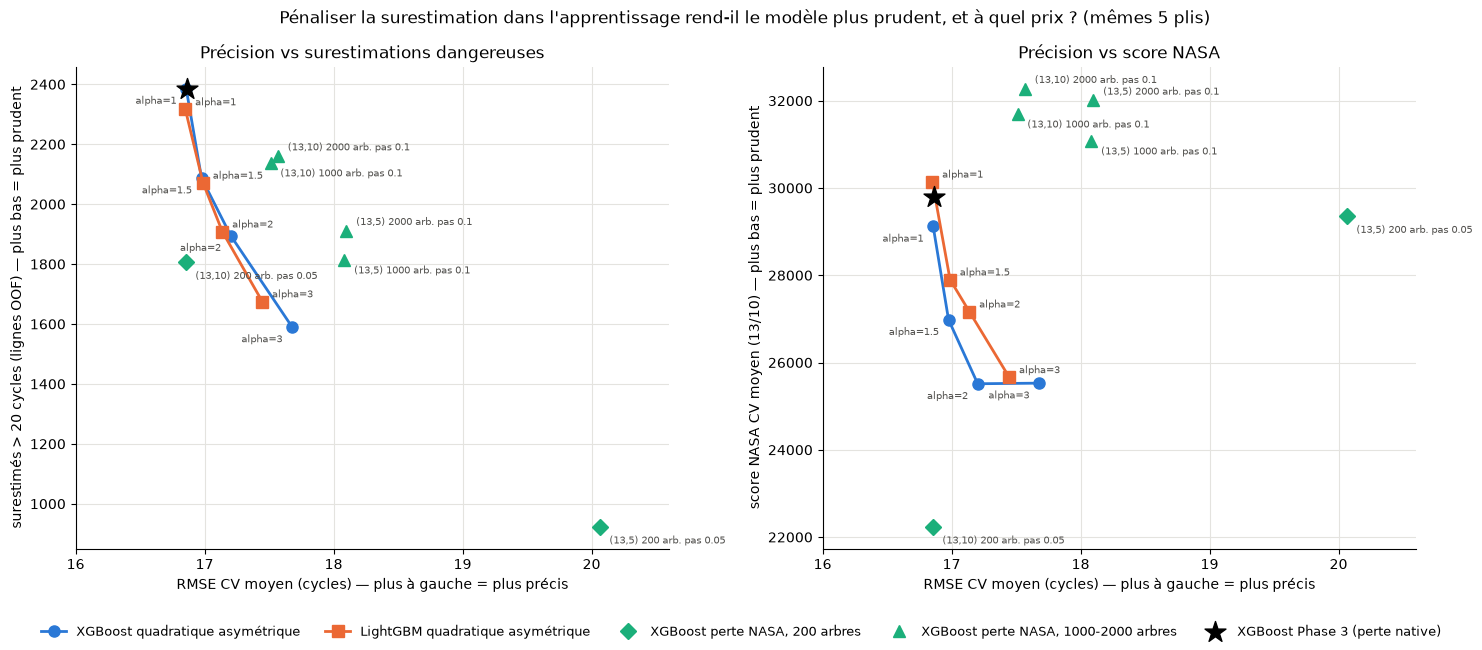

In [52]:
# --- Figure : le compromis precision / prudence (05, C.3) ---
# une ligne par groupe : (nom, couleur, marqueur, style de ligne, decalage de l'etiquette en points, alignement)
groupes_figure = [
    ("XGBoost quadratique asymétrique", COULEUR_1, "o", "-", (-7, -11), "right"),
    ("LightGBM quadratique asymétrique", COULEUR_2, "s", "-", (7, 3), "left"),
    ("XGBoost perte NASA, 200 arbres", COULEUR_3, "D", "none", (7, -12), "left"),
    ("XGBoost perte NASA, 1000-2000 arbres", COULEUR_3, "^", "none", (7, -10), "left"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, colonne_y, titre_y in [(axes[0], "surestimes_oof", "surestimés > 20 cycles (lignes OOF)"),
                                (axes[1], "nasa_cv_moyen", "score NASA CV moyen (13/10)")]:  # un panneau a la fois
    for groupe, couleur, marqueur, style_ligne, decalage, alignement in groupes_figure:
        sous_tableau = tableau_penalite[tableau_penalite["groupe"] == groupe]  # les reglages de ce groupe
        ax.plot(sous_tableau["rmse_cv_moyen"], sous_tableau[colonne_y], marker=marqueur, linestyle=style_ligne,
                color=couleur, markersize=8, linewidth=2, label=groupe)
        for nom_reglage in sous_tableau.index:  # etiquette courte a cote de chaque point
            etiquette = nom_reglage.replace("XGBoost quadratique ", "").replace("LightGBM quadratique ", "")
            etiquette = etiquette.replace("XGBoost NASA ", "").replace(" arbres pas ", " arb. pas ")
            decalage_point = decalage
            if "2000 arbres" in nom_reglage:  # 1000 et 2000 arbres sont tres proches : etiquette au-dessus
                decalage_point = (7, 4)
            ax.annotate(etiquette, (sous_tableau.loc[nom_reglage, "rmse_cv_moyen"], sous_tableau.loc[nom_reglage, colonne_y]),
                        textcoords="offset points", xytext=decalage_point, ha=alignement, fontsize=7, color=COULEUR_TEXTE)
    reference = tableau_penalite.loc["XGBoost Phase 3 (perte native)"]  # l'etoile noire
    ax.scatter(reference["rmse_cv_moyen"], reference[colonne_y], marker="*", s=250, color="black", zorder=4,
               label="XGBoost Phase 3 (perte native)")
    ax.set_xlim(16.0, 20.6)  # marge a gauche pour les etiquettes XGBoost
    ax.set_xlabel("RMSE CV moyen (cycles) — plus à gauche = plus précis")
    ax.set_ylabel(titre_y + " — plus bas = plus prudent")
axes[0].set_title("Précision vs surestimations dangereuses")
axes[1].set_title("Précision vs score NASA")
poignees, etiquettes = axes[0].get_legend_handles_labels()  # elements de legende du premier panneau
fig.legend(poignees, etiquettes, loc="lower center", ncol=5, fontsize=9, frameon=False)  # legende commune, sous les panneaux
fig.suptitle("Pénaliser la surestimation dans l'apprentissage rend-il le modèle plus prudent, et à quel prix ? (mêmes 5 plis)")
plt.tight_layout(rect=(0, 0.06, 1, 1))  # on laisse la place de la legende en bas
plt.show()

**Conclusion de 7.1** (05, C.4) :

1. **Changer 13 et 10 dans la note ne change rien au modèle** : RMSE test identique pour tous les k, alors que le score tend vers 0.
2. **La pénalité dans l'apprentissage fonctionne, avec un prix.** Quand α passe de 1 à 3, les surestimés hors-pli de plus de 20 cycles baissent d'environ un tiers pour XGBoost ; en échange, le RMSE CV monte (16,86 → 17,68), les fausses alertes augmentent et le biais devient nettement négatif.
3. **α = 1 redonne la Phase 3** (RMSE CV 16,86 contre 16,87) : la perte sur mesure est bien branchée.
4. **Perte NASA : attention à la convergence.** À 200 arbres, (13, 10) paraît le meilleur compromis, mais ce modèle n'a pas fini d'apprendre : à 1 000 et 2 000 arbres, il devient moins bon que la Phase 3 sur les deux critères. Le gain à 200 arbres vient de l'apprentissage inachevé, pas de la perte seule.
5. **Non retenu** : pénalité, nombre d'arbres et pas devraient être réglés ensemble ; aucune version pénalisée n'a été choisie (le modèle « α = 2,26 » d'un prototype antérieur a été retiré, `STATUS.md`, 2026-11-04).

In [53]:
verifier("7.1 : RMSE test identique pour tous les k", 1, float(tableau_constantes["rmse_test"].nunique() == 1), decimales=0)
alpha_1 = resultats_cv_penalite["XGBoost quadratique alpha=1"]
alpha_3 = resultats_cv_penalite["XGBoost quadratique alpha=3"]
baisse_surestimes = 1 - alpha_3["surestimes_oof"] / alpha_1["surestimes_oof"]
verifier("7.1 : baisse des surestimes, alpha 1 -> 3 (environ un tiers)", 0.3, baisse_surestimes, decimales=1)
verifier("7.1 : RMSE CV alpha = 1", 16.86, alpha_1["rmse_moyen"])
verifier("7.1 : RMSE CV alpha = 3", 17.68, alpha_3["rmse_moyen"])
verifier("7.1 : plus de fausses alertes avec alpha = 3", 1, float(alpha_3["fausses_alertes_oof"] > alpha_1["fausses_alertes_oof"]), decimales=0)
nasa_200 = resultats_cv_penalite["XGBoost NASA (13,10) 200 arbres pas 0.05"]
nasa_1000 = resultats_cv_penalite["XGBoost NASA (13,10) 1000 arbres pas 0.1"]
reference_phase3 = resultats_cv_base["XGBoost Phase 3"]
verifier("7.1 : perte NASA 1000 arbres moins bonne que la Phase 3 en RMSE", 1, float(nasa_1000["rmse_moyen"] > reference_phase3["rmse_moyen"]), decimales=0)
verifier("7.1 : perte NASA 1000 arbres moins bonne que la Phase 3 en score NASA", 1, float(nasa_1000["nasa_moyen"] > reference_phase3["nasa_moyen"]), decimales=0)
verifier("7.1 : perte NASA 200 arbres meilleure que la Phase 3 en score NASA", 1, float(nasa_200["nasa_moyen"] < reference_phase3["nasa_moyen"]), decimales=0)

OK    7.1 : RMSE test identique pour tous les k : cite 1, calcule 1.0
OK    7.1 : baisse des surestimes, alpha 1 -> 3 (environ un tiers) : cite 0.3, calcule 0.3
OK    7.1 : RMSE CV alpha = 1 : cite 16.86, calcule 16.86
OK    7.1 : RMSE CV alpha = 3 : cite 17.68, calcule 17.68
OK    7.1 : plus de fausses alertes avec alpha = 3 : cite 1, calcule 1.0
OK    7.1 : perte NASA 1000 arbres moins bonne que la Phase 3 en RMSE : cite 1, calcule 1.0
OK    7.1 : perte NASA 1000 arbres moins bonne que la Phase 3 en score NASA : cite 1, calcule 1.0
OK    7.1 : perte NASA 200 arbres meilleure que la Phase 3 en score NASA : cite 1, calcule 1.0


True

### 7.2 À réglages de base, les trois modèles à arbres se distinguent-ils ? Et combien coûtent-ils à entraîner ? (05, B.3)

Un critère par panneau (jamais deux échelles sur le même axe). Panneau RMSE : la barre est la moyenne des 5 plis, les points sont les 5 plis. La référence naïve, hors échelle, est citée dans le titre. Les secondes dépendent de la machine et de sa charge (ici : 4 cœurs au plus, machine partagée) : ce sont des ordres de grandeur.

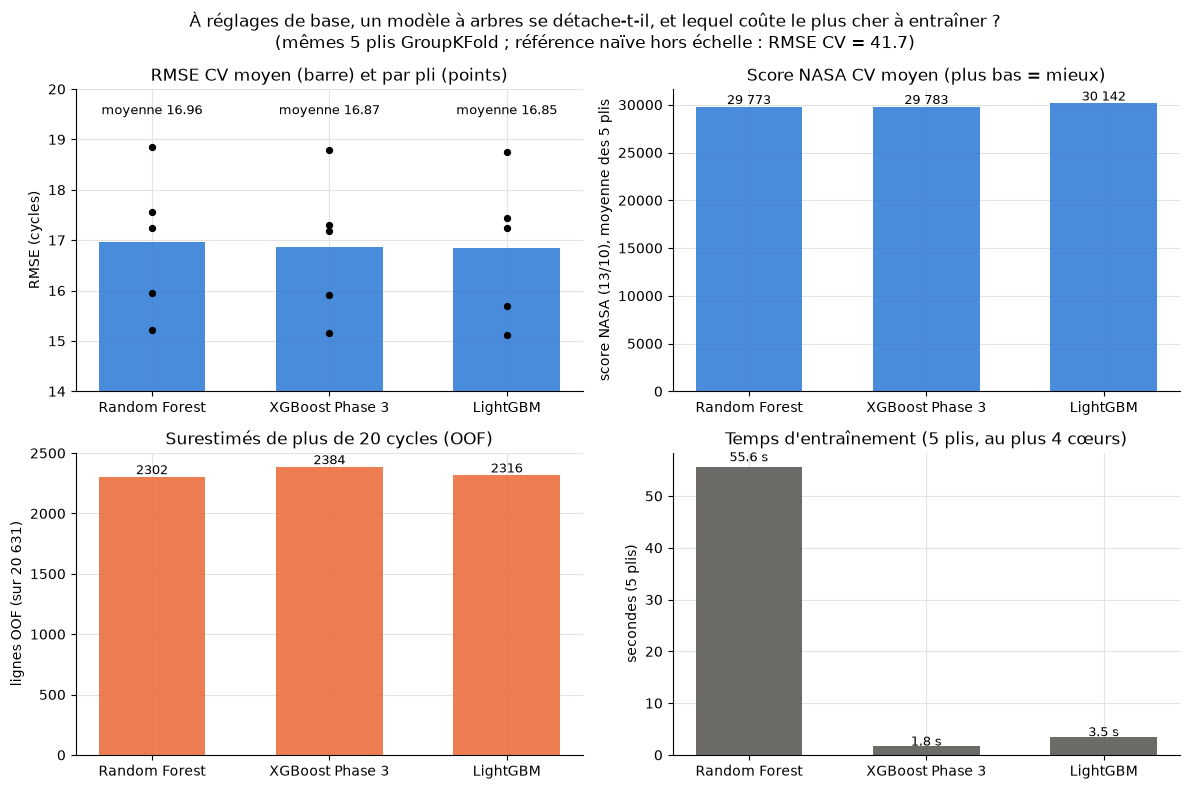

In [54]:
noms_compares = ["Random Forest", "XGBoost Phase 3", "LightGBM"]  # la reference naive est hors echelle : pas dessinee
positions = np.arange(len(noms_compares))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))  # 4 panneaux : 2 lignes x 2 colonnes

# (1) RMSE CV : moyenne (barre) et valeur de chaque pli (points)
ax = axes[0, 0]
for position, nom_modele in zip(positions, noms_compares):
    resultats = resultats_cv_base[nom_modele]
    ax.bar(position, resultats["rmse_moyen"], width=0.6, color=COULEUR_1, alpha=0.85)
    ax.scatter(np.full(5, position), resultats["rmse_par_pli"], color="black", s=18, zorder=3)  # 5 points a la meme abscisse
    ax.text(position, 19.5, f"moyenne {resultats['rmse_moyen']:.2f}", ha="center", fontsize=9)
ax.set_ylim(14, 20)
ax.set_ylabel("RMSE (cycles)")
ax.set_title("RMSE CV moyen (barre) et par pli (points)")

# (2) score NASA CV moyen
ax = axes[0, 1]
for position, nom_modele in zip(positions, noms_compares):
    valeur = resultats_cv_base[nom_modele]["nasa_moyen"]
    ax.bar(position, valeur, width=0.6, color=COULEUR_1, alpha=0.85)
    ax.text(position, valeur * 1.01, f"{valeur:,.0f}".replace(",", " "), ha="center", fontsize=9)
ax.set_ylabel("score NASA (13/10), moyenne des 5 plis")
ax.set_title("Score NASA CV moyen (plus bas = mieux)")

# (3) surestimations dangereuses : lignes OOF surestimees de plus de 20 cycles
ax = axes[1, 0]
for position, nom_modele in zip(positions, noms_compares):
    valeur = resultats_cv_base[nom_modele]["surestimes_oof"]
    ax.bar(position, valeur, width=0.6, color=COULEUR_2, alpha=0.85)
    ax.text(position, valeur * 1.01, str(valeur), ha="center", fontsize=9)
ax.set_ylabel("lignes OOF (sur 20 631)")
ax.set_title("Surestimés de plus de 20 cycles (OOF)")

# (4) temps d'entrainement cumule sur les 5 plis
ax = axes[1, 1]
for position, nom_modele in zip(positions, noms_compares):
    valeur = resultats_cv_base[nom_modele]["temps_entrainement_total"]
    ax.bar(position, valeur, width=0.6, color=COULEUR_TEXTE, alpha=0.85)
    ax.text(position, valeur * 1.02, f"{valeur:.1f} s", ha="center", fontsize=9)
ax.set_ylabel("secondes (5 plis)")
ax.set_title("Temps d'entraînement (5 plis, au plus 4 cœurs)")

for ax in axes.ravel():  # memes etiquettes de modeles sous chacun des 4 panneaux
    ax.set_xticks(positions)
    ax.set_xticklabels(noms_compares)

rmse_naive = resultats_cv_base["Reference naive"]["rmse_moyen"]
fig.suptitle(f"À réglages de base, un modèle à arbres se détache-t-il, et lequel coûte le plus cher à entraîner ?\n"
             f"(mêmes 5 plis GroupKFold ; référence naïve hors échelle : RMSE CV = {rmse_naive:.1f})")
plt.tight_layout()
plt.show()

**Lecture** (05, B.4) : égalité statistique en précision et en prudence entre les trois modèles (tests appariés de 4.1). XGBoost et LightGBM s'entraînent en quelques secondes pour les 5 plis, la Random Forest plusieurs fois plus lentement. XGBoost n'était donc pas justifié par sa précision, mais par sa vitesse et par la possibilité d'une perte d'apprentissage sur mesure (7.1), que la Random Forest de scikit-learn n'offre pas.

In [55]:
temps_rf = resultats_cv_base["Random Forest"]["temps_entrainement_total"]
temps_xgb = resultats_cv_base["XGBoost Phase 3"]["temps_entrainement_total"]
temps_lgbm = resultats_cv_base["LightGBM"]["temps_entrainement_total"]
verifier("7.2 : Random Forest plus lente que XGBoost et LightGBM", 1, float(temps_rf > temps_xgb and temps_rf > temps_lgbm), decimales=0)

OK    7.2 : Random Forest plus lente que XGBoost et LightGBM : cite 1, calcule 1.0


True

### 7.3 Les moteurs surestimés de plus de 20 cycles : d'où viennent-ils ? (05, section E)

On liste les moteurs test que XGBoost Phase 3 surestime de plus de 20 cycles, avec le nombre de cycles **observés** dans `test_FD001.txt` (la longueur de la trajectoire dont dispose le modèle). Cette analyse ne sert à choisir aucun modèle.

Deux hypothèses, testées plutôt qu'affirmées :
- **H1** : les moteurs surestimés ont des trajectoires observées **plus courtes** (le modèle a vu peu de cycles, le moteur « a l'air » neuf) ;
- **H2** : les moteurs surestimés ont des RUL vraies **différentes** des autres.

**Test de Mann-Whitney** : il compare deux groupes indépendants (surestimés contre autres) par les rangs, sans supposer de loi normale. **Limite** : très peu de moteurs surestimés ; une p-valeur > 0,05 ne prouve pas l'absence d'effet. En complément, une corrélation de Spearman (ρ, entre −1 et +1) sur les **100 moteurs**, entre l'écart signé et chaque variable.

In [56]:
# nombre de cycles observes pour chaque moteur test (trajectoire tronquee), dans l'ordre des moteurs
nb_cycles_par_moteur = contexte_test["test"].groupby("unit_number").size()  # nombre de lignes de chaque moteur
moteurs_test = contexte_test["moteurs_test"]  # numeros de moteur, meme ordre que y_test_vraie
nb_cycles_observes = nb_cycles_par_moteur.loc[moteurs_test].to_numpy()  # remis dans l'ordre de moteurs_test

# un tableau des 100 moteurs test pour XGBoost Phase 3
predictions_phase3 = resultats_test["XGBoost Phase 3"]["predictions"]
tableau_moteurs = pd.DataFrame({
    "unit_number": moteurs_test,
    "rul_vraie": y_test_vraie,
    "rul_predite": predictions_phase3,
    "ecart": predictions_phase3 - y_test_vraie,  # positif = surestimation
    "nb_cycles_observes": nb_cycles_observes,
})
tableau_moteurs["surestime_20"] = tableau_moteurs["ecart"] > SEUIL_SURESTIMATION  # Vrai si surestime de plus de 20 cycles

print(f"=== XGBoost Phase 3 : {int(tableau_moteurs['surestime_20'].sum())} moteurs surestimes de plus de 20 cycles ===")
surestimes_tries = tableau_moteurs[tableau_moteurs["surestime_20"]].sort_values("ecart", ascending=False)
display(surestimes_tries.round(1))

groupe_surestimes = tableau_moteurs[tableau_moteurs["surestime_20"]]  # les moteurs surestimes de plus de 20 cycles
groupe_autres = tableau_moteurs[~tableau_moteurs["surestime_20"]]     # tous les autres (~ : "non")

lignes = []
for variable in ["nb_cycles_observes", "rul_vraie"]:  # H1 puis H2
    test_mw = stats.mannwhitneyu(groupe_surestimes[variable], groupe_autres[variable], alternative="two-sided")
    correlation = stats.spearmanr(tableau_moteurs["ecart"], tableau_moteurs[variable])  # sur les 100 moteurs
    ligne = {}
    ligne["variable"] = variable
    ligne["n_surestimes"] = len(groupe_surestimes)
    ligne["n_autres"] = len(groupe_autres)
    ligne["mediane_surestimes"] = groupe_surestimes[variable].median()
    ligne["mediane_autres"] = groupe_autres[variable].median()
    ligne["p_valeur_mann_whitney"] = test_mw.pvalue
    ligne["rho_spearman_ecart_100_moteurs"] = correlation.statistic
    ligne["p_valeur_spearman"] = correlation.pvalue
    lignes.append(ligne)
tableau_hypotheses = pd.DataFrame(lignes).set_index("variable")
tableau_hypotheses.round(4)

=== XGBoost Phase 3 : 9 moteurs surestimes de plus de 20 cycles ===


,unit_number,rul_vraie,rul_predite,ecart,nb_cycles_observes,surestime_20
36,37,21,75.099998,54.1,121,True
66,67,77,115.099998,38.1,71,True
17,18,28,62.000000,34.0,133,True
14,15,83,116.900002,33.9,76,True
78,79,63,95.300003,32.3,101,True
40,41,18,49.700001,31.7,123,True
71,72,50,79.300003,29.3,131,True
26,27,66,88.900002,22.9,140,True
1,2,98,120.599998,22.6,49,True


,n_surestimes,n_autres,mediane_surestimes,mediane_autres,p_valeur_mann_whitney,rho_spearman_ecart_100_moteurs,p_valeur_spearman
variable,,,,,,,
nb_cycles_observes,9,91,121.0,137.0,0.0717,-0.1873,0.0620
rul_vraie,9,91,63.0,90.0,0.1159,-0.3405,0.0005


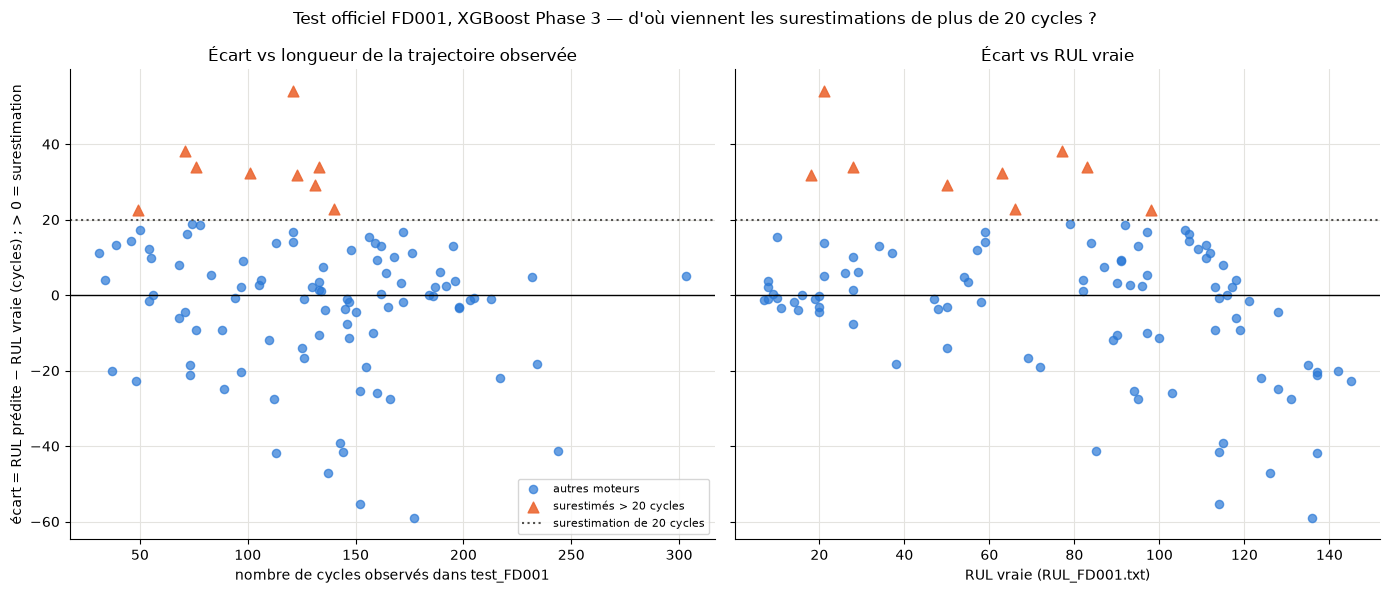

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)  # meme axe vertical (l'ecart) pour les deux panneaux

for ax, variable, titre_x in [(axes[0], "nb_cycles_observes", "nombre de cycles observés dans test_FD001"),
                               (axes[1], "rul_vraie", "RUL vraie (RUL_FD001.txt)")]:  # H1 a gauche, H2 a droite
    ax.scatter(groupe_autres[variable], groupe_autres["ecart"], color=COULEUR_1, marker="o", s=35, alpha=0.7,
               label="autres moteurs")
    ax.scatter(groupe_surestimes[variable], groupe_surestimes["ecart"], color=COULEUR_2, marker="^", s=60, alpha=0.9,
               label=f"surestimés > {SEUIL_SURESTIMATION} cycles")
    ax.axhline(0, color="black", linewidth=1)  # ecart nul : prediction parfaite
    ax.axhline(SEUIL_SURESTIMATION, color=COULEUR_TEXTE, linestyle=":", label=f"surestimation de {SEUIL_SURESTIMATION} cycles")
    ax.set_xlabel(titre_x)
axes[0].set_ylabel("écart = RUL prédite − RUL vraie (cycles) ; > 0 = surestimation")
axes[0].set_title("Écart vs longueur de la trajectoire observée")
axes[1].set_title("Écart vs RUL vraie")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Test officiel FD001, XGBoost Phase 3 — d'où viennent les surestimations de plus de 20 cycles ?")
plt.tight_layout()
plt.show()

**Conclusion de 7.3** (05, E.3) :

- **9 moteurs surestimés de plus de 20 cycles**, le pire étant le moteur 37.
- **H1 (trajectoires plus courtes) : non démontrée** (Mann-Whitney p > 0,05) : au mieux une faible tendance.
- **H2 (RUL vraie différente) : non démontrée entre les deux groupes** (p > 0,05). La corrélation entre écart et RUL vraie sur 100 moteurs est nette et négative, mais en partie **mécanique** : la cible apprise est plafonnée à 125, donc un moteur dont la RUL vraie dépasse largement 125 est presque forcément sous-estimé.
- **Piste non testée** : examiner les capteurs des moteurs les plus dangereusement surestimés (alertes manquées sur des trajectoires de longueur ordinaire).

In [58]:
verifier("7.3 : moteurs surestimes de plus de 20 cycles", 9, int(tableau_moteurs["surestime_20"].sum()), decimales=0)
verifier("7.3 : moteur le plus surestime", 37, int(surestimes_tries["unit_number"].iloc[0]), decimales=0)
verifier("7.3 : H1 non demontree (p Mann-Whitney > 0,05)", 1, float(tableau_hypotheses.loc["nb_cycles_observes", "p_valeur_mann_whitney"] > 0.05), decimales=0)
verifier("7.3 : H2 non demontree (p Mann-Whitney > 0,05)", 1, float(tableau_hypotheses.loc["rul_vraie", "p_valeur_mann_whitney"] > 0.05), decimales=0)
verifier("7.3 : correlation ecart / RUL vraie negative et significative", 1,
         float(tableau_hypotheses.loc["rul_vraie", "rho_spearman_ecart_100_moteurs"] < 0
               and tableau_hypotheses.loc["rul_vraie", "p_valeur_spearman"] < 0.05), decimales=0)

OK    7.3 : moteurs surestimes de plus de 20 cycles : cite 9, calcule 9.0
OK    7.3 : moteur le plus surestime : cite 37, calcule 37.0
OK    7.3 : H1 non demontree (p Mann-Whitney > 0,05) : cite 1, calcule 1.0
OK    7.3 : H2 non demontree (p Mann-Whitney > 0,05) : cite 1, calcule 1.0
OK    7.3 : correlation ecart / RUL vraie negative et significative : cite 1, calcule 1.0


True

### 7.4 Autres pistes non retenues, sans figure (une ligne chacune)

- **Ablation à 7 jeux de variables de la Phase 3** ([03_modelisation](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/03_modelisation.ipynb), section 11) : elle a fait ajouter `time_cycles` ; remplacée par l'ablation par familles du 04e (`02_choix_du_modele`).
- **Grid search contre random search contre Optuna** ([04d_hyperparametres](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04d_hyperparametres.ipynb)) : les trois recherches et la figure RMSE contre score NASA de chaque essai sont en 5.2 (seule trace de Grid et Random dans la v2 : `02_choix_du_modele` ne garde qu'Optuna) ; la recherche Optuna, l'importance des réglages et la confirmation sur plis neufs sont dans `02_choix_du_modele`.
- **Variantes de variables testées après lecture des résultats** ([04e_feature_engineering](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/04e_feature_engineering.ipynb), section 9) : jamais évaluées sur le test, non retenues.
- **Perte asymétrique α = 2,26 pour le meilleur réseau** ([03b_deep_learning_lstm_cnn](https://github.com/MatisseGrl/aero-predict/blob/v1-avant-reorganisation/notebooks/03b_deep_learning_lstm_cnn.ipynb), section E) : non retenue.
- **Fenêtre de 50 cycles pour les réseaux** (05, F.5) : non retenue, chiffres relus en 4.4.

## 8. L'escalier, chiffres recalculés

Toutes les marches enregistrées au fil du notebook : RMSE de validation et RMSE du test officiel FD001 (contre la RUL brute), avec la provenance de chaque chiffre. **Attention aux protocoles de validation** : les étapes 1 à 5 utilisent les 5 plis de graine 42 ; l'ensemble de l'étape 6 n'a été validé que sur 3 découpages neufs ; et quand un réglage a été cherché sur les plis de graine 42 (étape 5, LSTM Optuna de l'étape 6), sa validation sur ces mêmes plis est optimiste. L'étape 2 ne concerne pas FD001 (une seule marche FD002, hors figure).

,etape,modele,rmse_cv,protocole_cv,rmse_test,provenance
0,0,Benchmark exploratoire (Random Forest),NaN,-,18.97,"README (NON recalculable : notebook supprime, ..."
1,1,"XGBoost Phase 3 (46 features, reglages a la main)",16.87,"5 plis, graine 42",19.70,recalcule ici
2,2,"XGBoost Phase 3, FD002 : normalisation globale...",19.48,"5 plis, graine 42 (FD002)",NaN,recalcule ici (pas de test pour la variante no...
3,2,"XGBoost Phase 3, FD002 : normalisation par reg...",16.41,"5 plis, graine 42 (FD002)",27.23,recalcule ici
4,3,"LSTM, reglages fixes a l'avance (16 entrees)",13.70,"5 plis, graine 42",13.86,recalcule ici (cache sorties/evolution/)
5,4a,"XGBoost, 31 variables (avec ecartinit_20)",9.36,"5 plis, graine 42",13.10,recalcule ici
6,4b,"LSTM, 31 entrees (avec ecartinit_20)",8.94,"5 plis, graine 42",12.29,lu : docs/resultats/03b/03b_deep_learning.csv
7,5,"XGBoost final (31 variables, reglages Optuna)",9.12,"5 plis, graine 42 (plis de la recherche : opti...",12.78,recalcule ici (reglages de src/config_modele.py)
8,6a,"LSTM Optuna, 1 graine",7.48,"5 plis, graine 42 (plis de la recherche : opti...",11.46,lu : docs/resultats/04h/04h_confirmation_lstm....
9,6b,Ensemble de 5 LSTM Optuna (retenu),7.38,3 decoupages neufs (graines 1000-1002),11.16,"lu : docs/resultats/04h/04h_ensemble.json, 04h..."


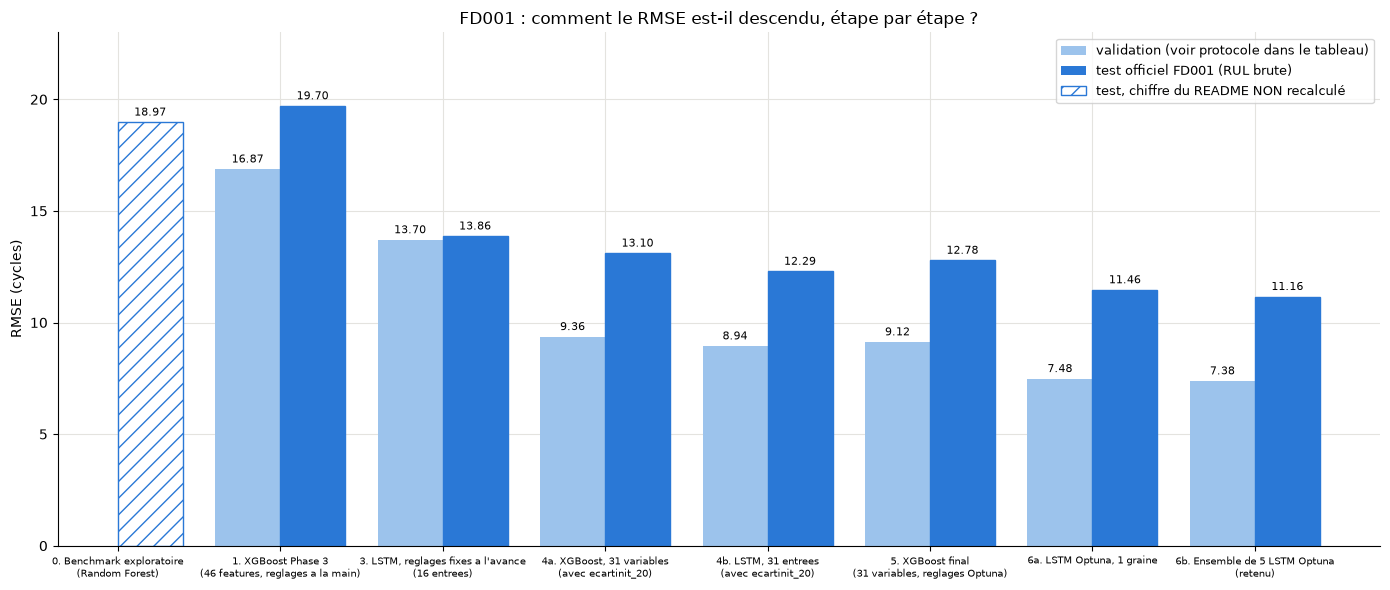

In [59]:
tableau_escalier = pd.DataFrame(ESCALIER)
display(tableau_escalier.round(2))

# --- Figure : l'escalier FD001 (l'etape 2, propre a FD002, est hors figure) ---
marches_fd001 = tableau_escalier[tableau_escalier["etape"] != "2"].reset_index(drop=True)
positions = np.arange(len(marches_fd001))
fig, ax = plt.subplots(figsize=(14, 6))
for position in range(len(marches_fd001)):
    marche = marches_fd001.iloc[position]
    if not np.isnan(marche["rmse_cv"]):  # validation croisee (absente pour le benchmark)
        ax.bar(position - 0.2, marche["rmse_cv"], width=0.4, color="#9cc3ec")
        ax.text(position - 0.2, marche["rmse_cv"] + 0.3, f"{marche['rmse_cv']:.2f}", ha="center", fontsize=8)
    couleur_test = COULEUR_1
    hachures = None
    if marche["etape"] == "0":  # benchmark : chiffre du README, non recalcule
        couleur_test = "white"
        hachures = "//"
    ax.bar(position + 0.2, marche["rmse_test"], width=0.4, color=couleur_test, edgecolor=COULEUR_1, hatch=hachures)
    ax.text(position + 0.2, marche["rmse_test"] + 0.3, f"{marche['rmse_test']:.2f}", ha="center", fontsize=8)
from matplotlib.patches import Patch  # elements de legende dessines a la main (une couleur par serie)

poignees = []
poignees.append(Patch(facecolor="#9cc3ec", label="validation (voir protocole dans le tableau)"))
poignees.append(Patch(facecolor=COULEUR_1, label="test officiel FD001 (RUL brute)"))
poignees.append(Patch(facecolor="white", edgecolor=COULEUR_1, hatch="//", label="test, chiffre du README NON recalculé"))
etiquettes = []
for position in range(len(marches_fd001)):
    marche = marches_fd001.iloc[position]
    texte = marche["modele"].replace(" (", "\n(")
    etiquettes.append(f"{marche['etape']}. {texte}")
ax.set_xticks(positions)
ax.set_xticklabels(etiquettes, fontsize=7)
ax.set_ylabel("RMSE (cycles)")
ax.set_ylim(0, 23)
ax.legend(handles=poignees, loc="upper right", fontsize=9)
ax.set_title("FD001 : comment le RMSE est-il descendu, étape par étape ?")
plt.tight_layout()
plt.show()

### 8.1 Contrôle des chiffres cités

Les chiffres écrits dans les cellules de texte, comparés aux chiffres recalculés ou lus par le code. Plus bas, les repères de non-régression du plan de réorganisation (section 9.2 et tableau 5.4) et de `STATUS.md`, comparés de la même façon. Un écart n'arrête pas le notebook : il est affiché ici, pour être corrigé ou expliqué.

In [60]:
# repere de non-regression (plan, section 9.2 et tableau 5.4 ; STATUS.md) : test FD001, sauf mention
verifier("Plan 5.4 / STATUS : etape 1, test benchmark (README)", 18.97, benchmark_test_rmse)
verifier("Plan 5.4 / STATUS : etape 1, test XGBoost Phase 3", 19.70, rmse_test)
verifier("Plan 5.4 / STATUS : etape 2, CV FD002 globale", 19.48, ablations_index.loc[("FD002", "globale"), "rmse_cv_moyen"])
verifier("Plan 5.4 / STATUS : etape 2, CV FD002 par regime", 16.41, ablations_index.loc[("FD002", "par_regime"), "rmse_cv_moyen"])
verifier("Plan 5.4 / STATUS : etape 3, test LSTM 03b", 13.86, lstm_03b["metriques_test"]["rmse"])
verifier("Plan 5.4 / STATUS : etape 4, CV XGBoost 46 variables", 16.87, resultats_cv_base["XGBoost Phase 3"]["rmse_moyen"])
verifier("Plan 5.4 / STATUS : etape 4, CV XGBoost 31 variables", 9.36, resultats_cv_31["XGBoost Phase 3"]["rmse_moyen"])
verifier("Plan 5.4 / STATUS : etape 4, test XGBoost 31 variables", 13.10, resultats_test_31["XGBoost Phase 3"]["rmse"])
verifier("Plan 5.4 / STATUS : etape 5, test XGBoost final (1 coeur, machine de Matisse)", 12.73,
         resultats_test_finaux["XGBoost Phase 3"]["rmse"], ecart_attendu=rmse_xgb_final != 12.73)
verifier("Plan 9.2 : test LightGBM final", 12.76, resultats_test_finaux["LightGBM"]["rmse"])
verifier("Plan 9.2 : test Random Forest final", 13.14, resultats_test_finaux["Random Forest"]["rmse"])
verifier("Plan 9.2 : test LSTM (03b avec ecart, fichier)", 12.29, ligne_lstm_a["rmse_test"])
verifier("Plan 9.2 : test CNN 1D (03b avec ecart, fichier docs/resultats/03b/)", 12.74, ligne_cnn_a["rmse_test"])
verifier("Plan 9.2 : test reference naive", 43.07, rmse_baseline_test)
verifier("STATUS 2026-11-07 : test ensemble 5 LSTM FD001", 11.16, test_04h["lstm_5_graines"]["rmse"])
verifier("STATUS 2026-11-07 : test ensemble 5 LSTM FD002", 22.38, test_04h_fd002["lstm_5_graines"]["rmse"])

tableau_controles = pd.DataFrame(CONTROLES)
nb_ecarts = int((~tableau_controles["identique"]).sum())
nb_ecarts_attendus = int(((~tableau_controles["identique"]) & tableau_controles["ecart_attendu_explique"]).sum())
print(f"\n{len(tableau_controles)} chiffres controles, {nb_ecarts} ecart(s), dont {nb_ecarts_attendus} attendu(s) et "
      f"explique(s) dans le texte :")
display(tableau_controles[~tableau_controles["identique"]])

OK    Plan 5.4 / STATUS : etape 1, test benchmark (README) : cite 18.97, calcule 18.97
OK    Plan 5.4 / STATUS : etape 1, test XGBoost Phase 3 : cite 19.7, calcule 19.7
OK    Plan 5.4 / STATUS : etape 2, CV FD002 globale : cite 19.48, calcule 19.48
OK    Plan 5.4 / STATUS : etape 2, CV FD002 par regime : cite 16.41, calcule 16.41
OK    Plan 5.4 / STATUS : etape 3, test LSTM 03b : cite 13.86, calcule 13.86
OK    Plan 5.4 / STATUS : etape 4, CV XGBoost 46 variables : cite 16.87, calcule 16.87
OK    Plan 5.4 / STATUS : etape 4, CV XGBoost 31 variables : cite 9.36, calcule 9.36
OK    Plan 5.4 / STATUS : etape 4, test XGBoost 31 variables : cite 13.1, calcule 13.1
ECART ATTENDU (explique dans le texte) Plan 5.4 / STATUS : etape 5, test XGBoost final (1 coeur, machine de Matisse) : cite 12.73, calcule 12.78
OK    Plan 9.2 : test LightGBM final : cite 12.76, calcule 12.76
OK    Plan 9.2 : test Random Forest final : cite 13.14, calcule 13.14
OK    Plan 9.2 : test LSTM (03b avec ecart, fichier)

,description,valeur_citee,valeur_calculee,identique,ecart_attendu_explique
61,Etape 5 apres : RMSE test XGBoost final publie...,12.73,12.78,False,True
62,Etape 5 apres : score NASA test XGBoost final ...,223.50,232.50,False,True
132,"Plan 5.4 / STATUS : etape 5, test XGBoost fina...",12.73,12.78,False,True


In [61]:
duree_notebook = time.perf_counter() - debut_notebook  # secondes ecoulees depuis la cellule des reglages
print(f"Execution complete du notebook : {duree_notebook / 60:.1f} min")

Execution complete du notebook : 6.1 min
